In [ ]:
import ast
import json
import subprocess
import sys
import stdlib_list  # Optional, but we can use a built-in fallback if not installed

# Define common package name mappings where the import name differs from the pip package name
PACKAGE_MAPPING = {
    "sklearn": "scikit-learn",
    "cv2": "opencv-python",
    "bs4": "beautifulsoup4",
    "PIL": "Pillow",
    "skimage": "scikit-image",
    "yaml": "PyYAML",
    "dateutil": "python-dateutil"
}

# Python standard library modules to exclude from pip installation
BUILTIN_MODULES = set(sys.builtin_module_names).union({
    "os", "sys", "re", "math", "json", "ast", "subprocess", "collections",
    "itertools", "functools", "pathlib", "time", "datetime", "random", "typing",
    "glob", "shutil", "copy", "io", "pickle", "logging", "warnings", "abc",
    "unicodedata", "string", "contextlib", "threading", "multiprocessing"
})

def extract_imports_from_notebook(notebook_path):
    """Parses a .ipynb file and extracts all unique top-level import names."""
    with open(notebook_path, "r", encoding="utf-8") as f:
        notebook = json.load(f)
    
    imported_modules = set()
    
    for cell in notebook.get("cells", []):
        if cell.get("cell_type") == "code":
            source_code = "".join(cell.get("source", []))
            try:
                tree = ast.parse(source_code)
                for node in ast.walk(tree):
                    if isinstance(node, ast.Import):
                        for alias in node.names:
                            imported_modules.add(alias.name.split(".")[0])
                    elif isinstance(node, ast.ImportFrom):
                        if node.module:
                            imported_modules.add(node.module.split(".")[0])
            except SyntaxError:
                # Skip cells with syntax errors or incomplete code snippets
                continue
                
    return imported_modules

def install_dependencies(notebook_path):
    raw_modules = extract_imports_from_notebook(notebook_path)
    
    # Filter out built-ins and internal modules
    target_packages = set()
    for mod in raw_modules:
        if mod not in BUILTIN_MODULES:
            # Map import name to official pip package name if necessary
            pkg_name = PACKAGE_MAPPING.get(mod, mod)
            target_packages.add(pkg_name)
            
    if not target_packages:
        print("No external dependencies detected.")
        return

    print(f"Discovered packages to install: {sorted(target_packages)}")
    
    # Execute pip install programmatically
    for package in target_packages:
        print(f"\n--- Installing: {package} ---")
        subprocess.check_call([sys.executable, "-m", "pip", "install", package])

# --- Execution ---
# Replace with your actual Jupyter Notebook filename if running externally
notebook_filename = "your_notebook_name.ipynb" 

# If running inside the notebook, you can dynamically fetch the current notebook name 
# or hardcode the filename string above.
try:
    install_dependencies(notebook_filename)
except FileNotFoundError:
    print(f"Error: Could not locate '{notebook_filename}'. Please update the path variable.")

# PS 02: Computational Linguistics/NLP Basics

## Learning Objectives

By the end of this practice session, you will be able to:

1. **Explain morphology fundamentals**: word formation, morphemes, inflection, and derivation.
2. **Compare tokenization strategies**: inspect how regex, NLTK, and spaCy handle the same text.
3. **Distinguish stemming from lemmatization**: explain their behavior, assumptions, and use cases.
4. **Trace a compact neural POS tagger**: connect token-level features, vectorization, training, and evaluation.
5. **Analyze syntactic structure**: inspect POS tags, dependency heads, attachment choices, the conditions on dependency trees, and Arc-standard transitions.
6. **Recognize lexical ambiguity**: explain why a word's context is needed to select its meaning.
7. **Use WordNet**: explore synsets, definitions, semantic relations, and path similarity.

---

## Session Flow

We follow the same learning pattern throughout the notebook:

**explain → demonstrate → implement → inspect and interpret**

| Block | Guided demonstration | Your focused task | What to inspect |
|---|---|---|---|
| Morphology | Toy stemmer and lemmatizer | **1.1** Compare NLTK stems and lemmas | Non-word stems and POS-sensitive lemmas |
| Tokenization | Space split vs. NLTK vs. spaCy | **1.2** Build regex tokenizers | Contractions, numbers, punctuation, and URLs |
| Syntax | Tiny neural POS tagger, spaCy dependencies, tree conditions, and Arc-standard parsing | **2.1** Extract POS and dependency information | Parser attachment choices and unresolved ambiguity |
| Semantics | Lexical ambiguity, WordNet, and Lesk | **2.2** Explore WordNet relations and definitions | Hypernyms, hyponyms, and definition lookups |

Run the setup first, then work through the notebook from top to bottom. The four task cells contain the only intended student gaps.

**Walkthrough cells.** Some code cells are followed by a **Walkthrough** cell. It reruns the code above, or a shortened copy of it, and lets you step through it: the highlighted line has just run, the variables panel marks inputs and anything new or changed, and the output panel shows what has been printed so far. Other walkthroughs open up a regex scan, the POS tagger, or a WordNet path. Use **Next →**, **Play**, the slider, or the ← / → keys. An **Explorer** cell lets you click through several examples. An **Animation** cell plays by itself; pause it or step through it with the same buttons. Their code is collapsed because only the output matters (in Colab, click **Show code** if you are curious). They need the walkthrough-tools setup cell below.


In [1]:
# @title Setup: walkthrough tools (run once; you do not need to read this cell)
# Defines trace_call(), regex_walkthrough(), tagger_walkthrough(), dependency_explorer(), wordnet_path_explorer(),
# lesk_explorer(), dependency_conditions_explorer(), arc_standard_walkthrough(), pos_pipeline_animation(),
# arc_standard_animation(), and the other walkthrough tools for the Walkthrough and Explorer cells below.
# They run the code, record what happens, and draw an interactive player.
_I2L_VIZ_SOURCE = r'''
# Intro2LLM step-through visualizer: runs real code, records every executed line,
# and renders an interactive player (code | variables | printed output).
import builtins
import contextlib
import hashlib
import html
import io
import json
import keyword
import re
import sys
import textwrap
import tokenize
import types
import uuid

from IPython.display import HTML, display

_MAX_STEPS = 400
_HEADERS = ("for ", "if ", "elif ", "while ")


def _code_part(line):
    """Line text without a trailing comment (good enough for loop/if headers)."""
    return re.sub(r"\s+#[^'\"]*$", "", line).strip()


# ----------------------------------------------------------------------------- values
def _short(text, limit):
    return text if len(text) <= limit else text[: limit - 1] + "…"


def _num(x):
    if isinstance(x, float):
        return f"{x:.4g}"
    return repr(x) if isinstance(x, str) else str(x)


def _sig(text):
    """Short fingerprint used by the player to detect changed values."""
    return hashlib.md5(text.encode()).hexdigest()[:10]


def _view(value):
    """Describe a value so the player can draw it (array grid, dict table, list chips, text)."""
    type_name = type(value).__name__
    shape = getattr(value, "shape", None)
    if shape is not None and hasattr(value, "tolist") and not isinstance(value, type):
        dims = [int(d) for d in shape]
        view = {"kind": "array", "type": type_name, "shape": dims,
                "dtype": str(getattr(value, "dtype", "")).replace("torch.", ""), "sig": _sig(repr(value))}
        data = value.tolist()
        if len(dims) == 0:
            view["rows"] = [[_num(data)]]
        elif len(dims) == 1:  # long vectors: first 12 values, then "…"
            cells = [_num(x) for x in data[:16 if dims[0] <= 16 else 12]]
            view["rows"] = [cells + (["…"] if dims[0] > 16 else [])]
        elif len(dims) == 2:  # large matrices: first rows/columns, then "…" / "⋮"
            n_rows = dims[0] if dims[0] <= 8 else 5
            n_cols = dims[1] if dims[1] <= 10 else 8
            rows = [[_num(x) for x in row[:n_cols]] + (["…"] if dims[1] > n_cols else []) for row in data[:n_rows]]
            view["rows"] = rows + ([["⋮"] * len(rows[0])] if dims[0] > n_rows else [])
        else:
            view["kind"], view["text"] = "text", _short(" ".join(repr(value).split()), 140)
        return view
    if isinstance(value, dict) and len(value) <= 14:
        return {"kind": "dict", "type": type_name, "sig": _sig(repr(value)),
                "items": [[_short(repr(k), 28), _short(repr(v), 40)] for k, v in value.items()]}
    if isinstance(value, (list, tuple)) and len(value) <= 24:
        return {"kind": "seq", "type": type_name, "sig": _sig(repr(value)),
                "items": [_short(repr(x), 28) for x in value]}
    text = repr(value)
    return {"kind": "text", "type": type_name, "text": _short(text, 140), "sig": _sig(text)}


def _visible(name, value):
    hidden_types = (types.ModuleType, types.FunctionType, types.BuiltinFunctionType, type)
    return not name.startswith("_") and not isinstance(value, hidden_types)


# ----------------------------------------------------------------------------- source
def _highlight(lines):
    """Return one HTML string per source line with light syntax colouring."""
    marks = [[""] * len(line) for line in lines]
    builtin_names = set(dir(builtins))
    string_types = {tokenize.STRING} | {getattr(tokenize, n) for n in ("FSTRING_START", "FSTRING_MIDDLE", "FSTRING_END")
                                        if hasattr(tokenize, n)}
    try:
        toks = list(tokenize.generate_tokens(io.StringIO("\n".join(lines) + "\n").readline))
    except (tokenize.TokenError, IndentationError, SyntaxError):
        toks = []
    for tok in toks:
        cls = ""
        if tok.type == tokenize.COMMENT:
            cls = "cm"
        elif tok.type in string_types:
            cls = "st"
        elif tok.type == tokenize.NAME and keyword.iskeyword(tok.string):
            cls = "kw"
        elif tok.type == tokenize.NAME and tok.string in builtin_names:
            cls = "bi"
        elif tok.type == tokenize.NUMBER:
            cls = "nu"
        if not cls:
            continue
        (r0, c0), (r1, c1) = tok.start, tok.end
        for r in range(r0, r1 + 1):
            if r - 1 >= len(lines):
                break
            start = c0 if r == r0 else 0
            end = c1 if r == r1 else len(lines[r - 1])
            for c in range(start, min(end, len(lines[r - 1]))):
                marks[r - 1][c] = cls
    out = []
    for line, mark in zip(lines, marks):
        parts, i = [], 0
        while i < len(line):
            j = i
            while j < len(line) and mark[j] == mark[i]:
                j += 1
            chunk = html.escape(line[i:j])
            parts.append(f'<span class="{mark[i]}">{chunk}</span>' if mark[i] else chunk)
            i = j
        out.append("".join(parts) or " ")
    return out


def _block_ends(lines):
    """For each header line (for/if/while ...:), the last line number of its indented body."""
    def indent(s):
        return len(s) - len(s.lstrip())

    ends = {}
    for i, line in enumerate(lines):
        text = _code_part(line)
        if text.startswith(_HEADERS) and text.endswith(":"):
            end = i + 1
            for j in range(i + 1, len(lines)):
                body = lines[j].strip()
                if not body or body.startswith("#"):
                    continue
                if indent(lines[j]) <= indent(line):
                    break
                end = j + 1
            ends[i + 1] = end
    return ends


# ----------------------------------------------------------------------------- tracing
class _Recorder:
    def __init__(self, lines, offset, notes, watch, hide, inputs):
        self.lines, self.offset = lines, offset
        self.notes, self.watch, self.hide, self.inputs = notes or {}, watch, set(hide or ()), inputs
        self.block_ends = _block_ends(lines)
        self.steps, self.pending, self.exc = [], None, None
        self.buffer = io.StringIO()
        self.truncated = False

    # values ------------------------------------------------------------------
    def snapshot(self, local_vars, global_vars=None):
        if not self.watch:
            names = [n for n, v in local_vars.items() if _visible(n, v) and n not in self.hide]
            return [[n, _view(local_vars[n]), n in self.inputs] for n in names]
        shown = []
        for expr in self.watch:  # watch entries may be names or expressions
            if expr.isidentifier() and expr not in local_vars:
                continue  # a plain name appears once the traced code defines it, never as a stale notebook global
            try:
                value = eval(expr, global_vars if global_vars is not None else {}, dict(local_vars))
            except Exception:
                continue  # not defined yet at this step
            shown.append([expr, _view(value), expr in self.inputs])
        return shown

    def user_note(self, key_text, frame):
        for key, template in self.notes.items():
            if key == "return":  # reserved for the final return-value step
                continue
            if (isinstance(key, int) and key == key_text) or (isinstance(key, str) and key in str(key_text)):
                try:
                    return eval("f" + repr(template), frame.f_globals, dict(frame.f_locals))
                except Exception:
                    return template
        return ""

    def auto_note(self, line, next_line, frame):
        if self.exc:
            note, self.exc = f"raises {self.exc}", None
            return note
        text = _code_part(self.lines[line - 1])
        if line not in self.block_ends:
            return ""
        entered = next_line is not None and line < next_line <= self.block_ends[line]
        if text.startswith("for "):
            target = text[4:].split(" in ", 1)[0].strip()
            if not entered:
                return "no items left → the loop ends"
            try:
                value = eval(target, frame.f_globals, dict(frame.f_locals))
                return f"next item: {target} = {_short(repr(value), 50)}"
            except Exception:
                return "next item"
        condition = text.split(" ", 1)[1][:-1].strip()
        verdict = "True" if entered else "False"
        if text.startswith("while "):
            return f"{condition} → {verdict}: " + ("run the loop body" if entered else "leave the loop")
        return f"{condition} → {verdict}: " + ("run the indented block" if entered else "skip the block")

    # events ------------------------------------------------------------------
    def finalize(self, frame, next_line):
        if self.pending is None:
            return
        line, self.pending = self.pending, None
        step = {"line": line, "vars": self.snapshot(frame.f_locals, frame.f_globals), "out": len(self.buffer.getvalue()),
                "note": self.user_note(self.lines[line - 1], frame),
                "auto": self.auto_note(line, next_line, frame)}
        # Inlined comprehensions re-trigger the same line; keep only the finished state.
        if self.steps and self.steps[-1]["line"] == line and self.steps[-1].get("kind") != "start":
            self.steps[-1] = step
        elif len(self.steps) < _MAX_STEPS:
            self.steps.append(step)
        else:
            self.truncated = True

    def local_tracer(self, frame, event, arg):
        line = frame.f_lineno - self.offset
        if event == "line":
            self.finalize(frame, line)
            self.pending = line
        elif event == "exception":
            self.exc = f"{arg[0].__name__}: {arg[1]}"
        elif event == "return":
            self.finalize(frame, None)
            self.return_frame = frame
        return self.local_tracer


def _run(recorder, should_trace, runner):
    def global_tracer(frame, event, arg):
        return recorder.local_tracer if event == "call" and should_trace(frame) else None

    previous = sys.gettrace()
    error = None
    result = None
    with contextlib.redirect_stdout(recorder.buffer):
        sys.settrace(global_tracer)
        try:
            result = runner()
        except Exception as exc:  # shown inside the player instead of stopping the notebook
            error = f"{type(exc).__name__}: {exc}"
        finally:
            sys.settrace(previous)
    return result, error


def trace_call(func, *args, title=None, intro="", notes=None, watch=None, hide=None, **kwargs):
    """Call `func(*args, **kwargs)` and show every executed line of its body."""
    import inspect
    source = textwrap.dedent(inspect.getsource(func))
    lines = source.rstrip("\n").split("\n")
    offset = func.__code__.co_firstlineno - 1
    bound = inspect.signature(func).bind(*args, **kwargs)
    bound.apply_defaults()
    rec = _Recorder(lines, offset, notes, watch, hide, inputs=set(bound.arguments))
    start_vars = [[n, _view(v), True] for n, v in bound.arguments.items()]
    if watch:
        start_vars = rec.snapshot(bound.arguments, func.__globals__)
    rec.steps.append({"kind": "start", "line": None, "vars": start_vars, "out": 0,
                      "note": intro or f"Call {func.__name__}(...) with the inputs shown on the right.", "auto": ""})
    result, error = _run(rec, lambda f: f.f_code is func.__code__, lambda: func(*args, **kwargs))
    _finish(rec, title or f"Step through {func.__name__}()", lines, result, error, returns=True)


def trace_code(code, env=None, title="Step through the code", intro="", notes=None, watch=None, hide=None):
    """Execute a code snippet line by line. `env` provides the input variables (and imports)."""
    source = textwrap.dedent(code).strip("\n")
    lines = source.split("\n")
    namespace = dict(env or {})
    inputs = {n for n, v in namespace.items() if _visible(n, v)}
    rec = _Recorder(lines, 0, notes, watch, hide, inputs=inputs)
    compiled = compile(source, "<i2l-trace>", "exec")
    rec.steps.append({"kind": "start", "line": None, "out": 0, "auto": "",
                      "vars": rec.snapshot(namespace, namespace),
                      "note": intro or ("Before running: these are the inputs." if inputs
                                        else "Nothing has run yet. Press Next → to run line 1.")})
    _, error = _run(rec, lambda f: f.f_code is compiled, lambda: exec(compiled, namespace))
    _finish(rec, title, lines, None, error, returns=False)


def _finish(rec, title, lines, result, error, returns):
    last = rec.steps[-1]
    if error:
        rec.steps.append({"kind": "error", "line": last["line"], "vars": last["vars"],
                          "out": len(rec.buffer.getvalue()), "note": f"The code stopped with {error}", "auto": ""})
    elif returns:
        rec.steps.append({"kind": "return", "line": last["line"], "vars": last["vars"],
                          "out": len(rec.buffer.getvalue()), "ret": _view(result),
                          "note": rec.notes.get("return", "") or "The function returns this value to the caller.",
                          "auto": ""})
    data = {"title": title, "code": _highlight(lines), "steps": rec.steps,
            "stdout": rec.buffer.getvalue(), "truncated": rec.truncated}
    _render(data)


# ----------------------------------------------------------------------------- HTML
_CSS = """
#ID{--bd:#dfe3e8;--mut:#667085;--acc:#b45309;--accS:#fff7ed;--new:#f0fdf4;--chg:#fffbeb;
 font-family:Inter,ui-sans-serif,system-ui,-apple-system,"Segoe UI",sans-serif;color:#18212f;background:#fff;
 border:1px solid var(--bd);border-radius:14px;padding:14px;max-width:1150px;outline:none;color-scheme:light;--h:440px}
#ID *{box-sizing:border-box}
#ID .hd{display:flex;justify-content:space-between;gap:12px;align-items:center;flex-wrap:wrap;margin-bottom:10px}
#ID .tt{font-size:17px;font-weight:750}
#ID .pill{border:1px solid var(--bd);background:#f7f8fa;border-radius:999px;padding:5px 10px;font-size:12px;font-weight:700}
#ID .grid{display:grid;grid-template-columns:minmax(0,1fr) minmax(0,1fr);gap:12px;align-items:stretch}
#ID .card{border:1px solid var(--bd);border-radius:11px;overflow:hidden;background:#fff;min-width:0}
#ID .ct{padding:7px 11px;border-bottom:1px solid var(--bd);font-size:11px;font-weight:750;color:var(--mut);
 text-transform:uppercase;letter-spacing:.04em;background:#f7f8fa}
#ID .codecard{display:flex;flex-direction:column;height:var(--h)}
#ID .code{background:#111827;color:#e5e7eb;font:12.5px/1.6 ui-monospace,SFMono-Regular,Menlo,Consolas,monospace;
 flex:1;min-height:0;overflow:auto;padding:8px 0;position:relative}
#ID .ln{display:grid;grid-template-columns:34px 1fr;white-space:pre;border-left:4px solid transparent;padding-right:10px}
#ID .ln>i{font-style:normal;color:#6b7280;text-align:right;padding-right:10px;user-select:none}
#ID .ln.on{background:rgba(245,158,11,.2);border-left-color:#f59e0b}
#ID .ln.done>i{color:#9ca3af}
#ID .kw{color:#c084fc}#ID .st{color:#86efac}#ID .cm{color:#7c8594;font-style:italic}#ID .bi{color:#93c5fd}#ID .nu{color:#fbbf24}
#ID .side{display:flex;flex-direction:column;gap:10px;min-width:0;height:var(--h)}
#ID .varcard{flex:1;min-height:0;display:flex;flex-direction:column}
#ID .outcard{flex:none}
#ID .msg{flex:none;border-left:4px solid #2563eb;background:#eff6ff;border-radius:8px;padding:8px 10px;font-size:13px;line-height:1.45;min-height:46px}
#ID .msg .where{font-size:11px;color:var(--mut);font-weight:700;text-transform:uppercase;letter-spacing:.03em}
#ID .msg .auto{margin-top:4px;font:12px ui-monospace,Menlo,monospace;color:#1e3a8a}
#ID .msg.err{border-left-color:#b42318;background:#fef2f2}
#ID .msg.ret{border-left-color:#15803d;background:#f0fdf4}
#ID .vars{padding:8px;display:flex;flex-direction:column;gap:6px;flex:1;min-height:0;overflow-y:auto;position:relative}
#ID .var{flex:none;border:1px solid var(--bd);border-radius:8px;padding:6px 8px;transition:background .25s;min-width:0}
#ID .val{overflow-x:auto;max-width:100%}
#ID .var.new{background:var(--new);border-color:#86efac}
#ID .var.chg{background:var(--chg);border-color:#fcd34d}
#ID .vh{display:flex;gap:6px;align-items:baseline;flex-wrap:wrap;font-size:12px;margin-bottom:3px}
#ID .vn{font:700 12.5px ui-monospace,Menlo,monospace}
#ID .ty{color:var(--mut);font-size:11px}
#ID .tag{font-size:10px;font-weight:750;border-radius:999px;padding:1px 6px;text-transform:uppercase}
#ID .tag.in{background:#e0e7ff;color:#3730a3}#ID .tag.new{background:#dcfce7;color:#166534}#ID .tag.chg{background:#fef3c7;color:#92400e}
#ID .tag.ret{background:#dcfce7;color:#166534}
#ID .mono{font:12px/1.45 ui-monospace,Menlo,monospace;word-break:break-word}
#ID .chips{display:flex;flex-wrap:wrap;gap:4px}
#ID .chip{border:1px solid #cfd4dc;border-radius:6px;padding:2px 6px;font:12px ui-monospace,Menlo,monospace;background:#fff;position:relative}
#ID .chip sub{color:var(--mut);font-size:9px;margin-left:3px}
#ID .chip.hl,#ID td.hl{background:#fde68a;border-color:#f59e0b}
#ID table{border-collapse:collapse;font:12px ui-monospace,Menlo,monospace}
#ID td{border:1px solid #e5e7eb;padding:2px 7px;text-align:right}
#ID .kv td{text-align:left}
#ID .out{background:#0b1020;color:#d1d5db;font:12px/1.5 ui-monospace,Menlo,monospace;white-space:pre-wrap;
 padding:8px 10px;height:110px;overflow:auto}
@media (max-width:560px){#ID .grid{grid-template-columns:1fr}#ID .codecard,#ID .side{height:auto}
 #ID .code{max-height:340px}#ID .vars{max-height:320px}}
#ID .out b{color:#fde68a;font-weight:600}
#ID .ctl{display:flex;gap:7px;align-items:center;flex-wrap:wrap;margin-top:10px}
#ID button{border:1px solid var(--bd);background:#fff;color:#18212f;border-radius:8px;min-height:34px;padding:5px 11px;
 font-weight:700;font-size:13px;cursor:pointer}
#ID button.pri{background:var(--acc);border-color:var(--acc);color:#fff}
#ID button:disabled{opacity:.4;cursor:default}
#ID input[type=range]{flex:1;min-width:120px;accent-color:#b45309}
#ID .hint{color:var(--mut);font-size:11px}
"""

_JS = r"""
(() => {
  const root = document.getElementById("ID");
  if (!root) return;
  try {
  const nojs = root.querySelector(".nojs"); if (nojs) nojs.remove();
  const D = __I2L_DATA__;
  const S = D.steps, $ = s => root.querySelector(s);
  const esc = s => String(s).replace(/[&<>]/g, c => ({"&":"&amp;","<":"&lt;",">":"&gt;"}[c]));
  const codeBox = $(".code");
  codeBox.innerHTML = D.code.map((h, i) => `<div class="ln" data-n="${i+1}"><i>${i+1}</i><span>${h}</span></div>`).join("");
  const lines = [...codeBox.children];
  // Height: fit the code (within limits) so code and state stay visible side by side.
  const codeHeight = D.code.length * 20 + 50;
  root.style.setProperty("--h", Math.max(D.stdout ? 420 : 340, Math.min(520, codeHeight)) + "px");
  if (!D.stdout) $(".outcard").style.display = "none";
  let k = 0, timer = null;

  function value(v, prev) {
    if (v.kind === "array") {
      const p = prev && prev.kind === "array" && JSON.stringify(prev.shape) === JSON.stringify(v.shape) ? prev.rows : null;
      return `<table>${v.rows.map((r, i) => `<tr>${r.map((x, j) =>
        `<td class="${p && p[i][j] !== x ? "hl" : ""}">${esc(x)}</td>`).join("")}</tr>`).join("")}</table>`;
    }
    if (v.kind === "dict") {
      if (!v.items.length) return `<span class="mono" style="color:var(--mut)">{} (empty)</span>`;
      const old = new Map(prev && prev.kind === "dict" ? prev.items : []);
      return `<table class="kv">${v.items.map(([a, b]) =>
        `<tr><td class="${prev && old.get(a) !== b ? "hl" : ""}">${esc(a)}</td><td class="${prev && old.get(a) !== b ? "hl" : ""}">${esc(b)}</td></tr>`).join("")}</table>`;
    }
    if (v.kind === "seq") {
      if (!v.items.length) return `<span class="mono" style="color:var(--mut)">${v.type === "tuple" ? "()" : "[]"} (empty)</span>`;
      const p = prev && prev.kind === "seq" ? prev.items : null;
      return `<div class="chips">${v.items.map((x, i) =>
        `<span class="chip ${p && p[i] !== x ? "hl" : ""}">${esc(x)}<sub>${i}</sub></span>`).join("")}</div>`;
    }
    return `<div class="mono">${esc(v.text)}</div>`;
  }

  function typeLabel(v) {
    if (v.kind === "array") return `${v.type} · shape (${v.shape.join(", ")}${v.shape.length === 1 ? "," : ""}) · ${v.dtype}`;
    if (v.kind === "dict" || v.kind === "seq") return `${v.type} · len ${v.items.length}`;
    return v.type;
  }

  function render() {
    const s = S[k], prevStep = k > 0 ? S[k - 1] : null;
    const prevVars = new Map(prevStep ? prevStep.vars.map(([n, v]) => [n, v]) : []);
    const ran = new Set(S.slice(1, k + 1).map(x => x.line));
    lines.forEach(el => {
      const n = +el.dataset.n;
      el.classList.toggle("on", n === s.line);
      el.classList.toggle("done", ran.has(n) && n !== s.line);
    });
    const on = lines[(s.line || 1) - 1];
    if (on && s.line) {
      const top = on.offsetTop;
      if (top < codeBox.scrollTop || top > codeBox.scrollTop + codeBox.clientHeight - 30)
        codeBox.scrollTop = Math.max(0, top - codeBox.clientHeight / 3);
    }

    const msg = $(".msg");
    msg.className = "msg" + (s.kind === "error" ? " err" : s.kind === "return" ? " ret" : "");
    const where = s.kind === "start" ? "Before running" : s.kind === "return" ? "Return value"
                : s.kind === "error" ? "Error" : `Line ${s.line} just ran`;
    msg.innerHTML = `<div class="where">${where}</div>${s.note ? `<div>${esc(s.note)}</div>` : ""}` +
                    (s.auto ? `<div class="auto">▸ ${esc(s.auto)}</div>` : "");

    let varsHtml = s.vars.map(([n, v, isIn]) => {
      const prev = prevVars.get(n);
      const state = !prevStep || s.kind === "start" ? "" : !prev ? "new" : prev.sig !== v.sig ? "chg" : "";
      const tags = (isIn ? `<span class="tag in">input</span>` : "") +
                   (state === "new" ? `<span class="tag new">new</span>` : state === "chg" ? `<span class="tag chg">changed</span>` : "");
      return `<div class="var ${state}"><div class="vh"><span class="vn">${esc(n)}</span><span class="ty">${esc(typeLabel(v))}</span>${tags}</div><div class="val">${value(v, state === "chg" ? prev : null)}</div></div>`;
    }).join("");
    if (s.ret) varsHtml = `<div class="var new"><div class="vh"><span class="vn">return</span><span class="ty">${esc(typeLabel(s.ret))}</span><span class="tag ret">output</span></div><div class="val">${value(s.ret)}</div></div>` + varsHtml;
    const varsBox = $(".vars");
    varsBox.innerHTML = varsHtml || `<span class="hint">No variables yet.</span>`;
    const focus = varsBox.querySelector(".var.new, .var.chg");
    varsBox.scrollTop = focus ? Math.max(0, focus.offsetTop - 8) : 0;

    const before = prevStep ? prevStep.out : 0;
    const out = D.stdout.slice(0, before) ;
    const fresh = D.stdout.slice(before, s.out);
    const outBox = $(".outcard .out");  // not $(".out"): other elements may also carry that class
    outBox.innerHTML = esc(out) + (fresh ? `<b>${esc(fresh)}</b>` : "") || `<span style="color:#6b7280">(nothing printed yet)</span>`;
    outBox.scrollTop = outBox.scrollHeight;

    $(".pill").textContent = `Step ${k + 1} / ${S.length}`;
    $("input").value = k;
    $(".b-first").disabled = $(".b-back").disabled = k === 0;
    $(".b-next").disabled = k === S.length - 1;
  }

  const go = i => { k = Math.max(0, Math.min(S.length - 1, i)); render(); };
  const stop = () => { clearInterval(timer); timer = null; $(".b-play").textContent = "Play"; };
  $("input").max = S.length - 1;
  $(".b-first").onclick = () => { stop(); go(0); };
  $(".b-back").onclick = () => { stop(); go(k - 1); };
  $(".b-next").onclick = () => { stop(); go(k + 1); };
  $("input").oninput = e => { stop(); go(+e.target.value); };
  $(".b-play").onclick = () => {
    if (timer) return stop();
    if (k === S.length - 1) go(0);
    $(".b-play").textContent = "Pause";
    timer = setInterval(() => (k >= S.length - 1 ? stop() : go(k + 1)), 900);
  };
  root.addEventListener("keydown", e => {
    if (e.key === "ArrowRight") { stop(); go(k + 1); e.preventDefault(); }
    if (e.key === "ArrowLeft") { stop(); go(k - 1); e.preventDefault(); }
  });
  render();
  } catch (err) {
    const box = document.createElement("div");
    box.className = "hint";
    box.style.cssText = "color:#b42318;margin-top:8px";
    box.textContent = "Interactive view failed: " + (err && err.message ? err.message : err);
    root.appendChild(box);
  }
})();
"""


def _script(js, uid, data):
    """Inline script with the data embedded as a JS literal ('<' escaped so it cannot close the tag)."""
    payload = json.dumps(data).replace("<", "\\u003c")
    return "<script>" + js.replace('"ID"', json.dumps(uid)).replace("__I2L_DATA__", payload) + "</script>"


def _render(data):
    uid = "i2l-" + uuid.uuid4().hex[:8]
    note = " (trace truncated)" if data["truncated"] else ""
    page = f"""
<div id="{uid}" tabindex="0">
<style>{_CSS.replace("#ID", "#" + uid)}</style>
<div class="hd"><div class="tt">{html.escape(data["title"])}{note}</div><div class="pill"></div></div>
<div class="nojs hint">Run this cell (and trust the notebook) to load the interactive player.</div>
<div class="grid">
  <div class="card codecard"><div class="ct">Code — highlighted line just ran</div><div class="code"></div></div>
  <div class="side">
    <div class="msg"></div>
    <div class="card varcard"><div class="ct">Variables after this line</div><div class="vars"></div></div>
    <div class="card outcard"><div class="ct">Printed output</div><div class="out"></div></div>
  </div>
</div>
<div class="ctl">
  <button class="b-first" title="First step">|←</button><button class="b-back">← Back</button>
  <button class="b-next pri">Next →</button><button class="b-play">Play</button>
  <input type="range" min="0" value="0" aria-label="Step">
  <span class="hint">Click the player, then use ← / → keys.</span>
</div>
{_script(_JS, uid, data)}
</div>"""
    display(HTML(page))


# ----------------------------------------------------------------------------- slicing explorer
_SLICE_RE = re.compile(r"^\[\s*(-?\d*)\s*(?::\s*(-?\d*)\s*(?::\s*(-?\d*)\s*)?)?\]$")

_SLICE_CSS = """
#ID{font-family:Inter,ui-sans-serif,system-ui,-apple-system,"Segoe UI",sans-serif;color:#18212f !important;background:#fff !important;
 border:1px solid #dfe3e8;border-radius:14px;padding:14px;max-width:1150px;color-scheme:only light}
#ID *{box-sizing:border-box}
#ID .tt{font-size:17px;font-weight:750;margin-bottom:4px;color:#18212f !important}
#ID .hint{color:#667085 !important;font-size:12px}
#ID .ruler{display:flex;flex-wrap:wrap;gap:3px;margin:14px 0 6px;min-height:0;background:transparent !important}
#ID .cell{display:flex;flex-direction:column;align-items:center;width:34px;position:relative}
#ID .cell .pos,#ID .cell .neg{font:10.5px ui-monospace,Menlo,monospace;color:#667085 !important}
#ID .cell .neg{color:#b45309 !important}
#ID .ch{width:34px;height:34px;border:1px solid #cfd4dc;border-radius:7px;display:flex;align-items:center;justify-content:center;
 font:15px ui-monospace,Menlo,monospace;background:#fff !important;color:#18212f !important;margin:2px 0;transition:background .2s,transform .2s}
#ID .ch.sel{background:#fde68a !important;border-color:#f59e0b;font-weight:800;transform:translateY(-2px)}
#ID .ch.stop{border:2px dashed #b42318}
#ID .ord{position:absolute;top:13px;right:-3px;background:#b45309;color:#fff;border-radius:999px;font:9px/14px ui-monospace,Menlo,monospace;
 min-width:14px;padding:0 3px;text-align:center}
#ID .mk{font:9.5px ui-monospace,Menlo,monospace;height:12px;color:#15803d;font-weight:700}
#ID .mk.stop{color:#b42318}
#ID .row{display:flex;gap:8px;align-items:center;flex-wrap:wrap;margin-top:8px}
#ID input{font:14px ui-monospace,Menlo,monospace;border:1px solid #cfd4dc;border-radius:8px;padding:6px 9px;width:150px;background:#fff !important;color:#18212f !important}
#ID .res{font:14px ui-monospace,Menlo,monospace;background:#0b1020;color:#e5e7eb;border-radius:8px;padding:8px 11px;margin-top:10px}
#ID .res .v{color:#86efac}#ID .res .e{color:#fca5a5}
#ID .explain{font-size:13px;margin-top:8px;border-left:4px solid #2563eb;background:#eff6ff;border-radius:8px;padding:8px 10px;line-height:1.45}
#ID button{border:1px solid #dfe3e8;background:#fff !important;border-radius:8px;padding:5px 9px;font:12.5px ui-monospace,Menlo,monospace;cursor:pointer;color:#18212f !important}
#ID button.on{background:#b45309 !important;border-color:#b45309;color:#fff !important}
#ID .legend{display:flex;gap:14px;flex-wrap:wrap;font-size:11.5px;color:#667085;margin-top:4px}
"""

_SLICE_JS = r"""
(() => {
  const root = document.getElementById("ID");
  if (!root) return;
  try {
  const nojs = root.querySelector(".nojs"); if (nojs) nojs.remove();
  const D = __I2L_DATA__;
  const text = D.text, n = text.length, $ = s => root.querySelector(s);
  const esc = s => String(s).replace(/[&<>]/g, c => ({"&":"&amp;","<":"&lt;",">":"&gt;"}[c]));
  const pyRepr = s => "'" + s.replace(/\\/g, "\\\\").replace(/'/g, "\\'") + "'";

  if (!$(".ruler").children.length) {
    $(".ruler").innerHTML = [...text].map((c, i) =>
      `<div class="cell"><span class="pos">${i}</span><span class="ch">${esc(c === " " ? "␣" : c)}</span>` +
      `<span class="neg">${i - n}</span><span class="mk"></span></div>`).join("");
  }
  const cells = [...root.querySelectorAll(".cell")];

  // Same rules as CPython's slice.indices(len)
  function evaluate(expr) {
    const m = expr.replace(/\s+/g, "").match(/^\[(-?\d*)(?::(-?\d*)(?::(-?\d*))?)?\]$/);
    if (!m) return {error: "Write it like [3], [-2], [2:7], [:5], [::2] or [::-1]."};
    const isSlice = expr.includes(":");
    const num = s => (s === undefined || s === "" ? null : parseInt(s, 10));
    if (!isSlice) {
      let i = num(m[1]);
      if (i === null) return {error: "SyntaxError: an index needs a number."};
      if (i < -n || i >= n) return {error: "IndexError: string index out of range"};
      const real = i < 0 ? i + n : i;
      return {indices: [real], index: i,
              explain: i < 0 ? `Negative index: ${i} + len (${n}) = ${real}.` : `Index ${i} is the ${i + 1}. character (counting starts at 0).`};
    }
    let step = num(m[3]); step = step === null ? 1 : step;
    if (step === 0) return {error: "ValueError: slice step cannot be zero"};
    const lower = step > 0 ? 0 : -1, upper = step > 0 ? n : n - 1;
    const fix = (v, dflt) => v === null ? dflt : v < 0 ? Math.max(v + n, lower) : Math.min(v, upper);
    const start = fix(num(m[1]), step < 0 ? upper : lower);
    const stop = fix(num(m[2]), step < 0 ? lower : upper);
    const indices = [];
    for (let i = start; step > 0 ? i < stop : i > stop; i += step) indices.push(i);
    const dir = step > 0 ? "left to right" : "right to left";
    let explain = `Start at index ${start}, move ${dir} in steps of ${Math.abs(step)}, ` +
                  (stop >= 0 && stop < n ? `and stop BEFORE index ${stop} (the stop is excluded).` : `until the ${step > 0 ? "end" : "beginning"} of the string.`);
    if (num(m[1]) !== null && num(m[1]) < 0) explain += ` Negative start ${num(m[1])} means index ${start}.`;
    if (num(m[2]) !== null && num(m[2]) < 0) explain += ` Negative stop ${num(m[2])} means index ${stop}.`;
    if (!indices.length) explain += " Nothing lies between start and stop in this direction → empty string.";
    return {indices, start, stop, step, explain};
  }

  function show(expr) {
    $("input").value = expr;
    root.querySelectorAll(".presets button").forEach(b => b.classList.toggle("on", b.textContent === expr));
    const r = evaluate(expr);
    cells.forEach(c => {
      c.querySelector(".ch").classList.remove("sel", "stop");
      c.querySelector(".mk").textContent = ""; c.querySelector(".mk").className = "mk";
      const o = c.querySelector(".ord"); if (o) o.remove();
    });
    const call = `${esc(D.name)}${esc(expr.replace(/\s+/g, ""))}`;
    if (r.error) {
      $(".res").innerHTML = `${call} → <span class="e">${esc(r.error)}</span>`;
      $(".explain").textContent = r.error.startsWith("Write") ? r.error : "Python raises this error.";
      return;
    }
    r.indices.forEach((i, k) => {
      const c = cells[i]; c.querySelector(".ch").classList.add("sel");
      if (r.indices.length > 1) c.insertAdjacentHTML("beforeend", `<span class="ord">${k + 1}</span>`);
    });
    if (r.start !== undefined && r.start >= 0 && r.start < n) cells[r.start].querySelector(".mk").textContent = "start";
    if (r.stop !== undefined && r.stop >= 0 && r.stop < n) {
      cells[r.stop].querySelector(".ch").classList.add("stop");
      const mk = cells[r.stop].querySelector(".mk"); mk.textContent = "stop"; mk.classList.add("stop");
    }
    const value = r.indices.map(i => text[i]).join("");
    $(".res").innerHTML = `${call} → <span class="v">${esc(pyRepr(value))}</span>`;
    $(".explain").textContent = r.explain;
  }

  if (!$(".presets").children.length) {
    $(".presets").innerHTML = D.examples.map(e => `<button type="button">${esc(e)}</button>`).join("");
  }
  root.querySelectorAll(".presets button").forEach(b => b.onclick = () => show(b.textContent));
  $("input").addEventListener("input", e => show(e.target.value));
  show(D.examples[0] || "[0:5]");
  } catch (err) {
    const box = document.createElement("div");
    box.className = "hint";
    box.style.cssText = "color:#b42318;margin-top:8px";
    box.textContent = "Interactive view failed: " + (err && err.message ? err.message : err);
    root.appendChild(box);
  }
})();
"""


def _python_slice(text, expr):
    """Ground truth for the explorer: evaluate text[...] in Python (only plain index/slice syntax)."""
    if not _SLICE_RE.match(expr.strip()):
        raise ValueError(f"not an index or slice: {expr}")
    return eval("text" + expr.strip(), {"__builtins__": {}}, {"text": text})


def slice_explorer(text, name="text", examples=("[0:5]",), title="Indexing and slicing explorer"):
    """Interactive ruler for text[i] and text[start:stop:step]; the presets are checked against Python."""
    examples = list(examples)
    data = {"text": text, "name": name, "examples": examples,
            "python": {e: _python_slice(text, e) for e in examples}}
    uid = "i2l-" + uuid.uuid4().hex[:8]
    # Pre-render the ruler and presets in Python, so the explorer stays readable even without JS.
    ruler_parts = []
    for i, ch in enumerate(text):
        shown = "␣" if ch == " " else ch
        ruler_parts.append(
            f'<div class="cell"><span class="pos">{i}</span>'
            f'<span class="ch">{html.escape(shown)}</span>'
            f'<span class="neg">{i - len(text)}</span><span class="mk"></span></div>'
        )
    presets_html = "".join(
        f'<button type="button">{html.escape(example)}</button>' for example in examples
    )
    first = examples[0] if examples else "[0:5]"
    page = f"""
<div id="{uid}">
<style>{_SLICE_CSS.replace("#ID", "#" + uid)}</style>
<div class="tt">{html.escape(title)}</div>
<div class="hint">Predict the result first, then click an example or type your own index or slice, e.g. <code>[2:8:2]</code>.</div>
<div class="nojs hint">If the buttons do not respond, run the setup cell at the top, then this cell again.</div>
<div class="ruler">{"".join(ruler_parts)}</div>
<div class="legend"><span>top: positive index</span><span style="color:#b45309">bottom: negative index</span>
<span>small badge: order in which characters are taken</span><span style="color:#b42318">dashed: stop index (excluded)</span></div>
<div class="row"><b style="font:14px ui-monospace,Menlo,monospace">{html.escape(name)}</b>
<input aria-label="index or slice" spellcheck="false" value="{html.escape(first)}"></div>
<div class="row presets">{presets_html}</div>
<div class="res"><code>{html.escape(name + first)}</code> — click a preset or edit the box after the interactive script loads.</div>
<div class="explain">The character ruler above is ready. Interaction highlights selected indices once the script loads.</div>
{_script(_SLICE_JS, uid, data)}
</div>"""
    display(HTML(page))


# ----------------------------------------------------------------------------- network walkthrough
_NET_CSS = """
#ID{font-family:Inter,ui-sans-serif,system-ui,-apple-system,"Segoe UI",sans-serif;color:#18212f;background:#fff;
 border:1px solid #dfe3e8;border-radius:14px;padding:14px;max-width:1150px;outline:none;color-scheme:light}
#ID *{box-sizing:border-box}
#ID .hd{display:flex;justify-content:space-between;gap:12px;align-items:center;flex-wrap:wrap;margin-bottom:10px}
#ID .tt{font-size:17px;font-weight:750}
#ID .pill{border:1px solid #dfe3e8;background:#f7f8fa;border-radius:999px;padding:5px 10px;font-size:12px;font-weight:700}
#ID .grid{display:grid;grid-template-columns:minmax(0,1.45fr) minmax(0,1fr);gap:12px;align-items:start}
@media (max-width:640px){#ID .grid{grid-template-columns:1fr}}
#ID .card{border:1px solid #dfe3e8;border-radius:11px;background:#fff;overflow:hidden;min-width:0}
#ID .ct{padding:7px 11px;border-bottom:1px solid #dfe3e8;font-size:11px;font-weight:750;color:#667085;
 text-transform:uppercase;letter-spacing:.04em;background:#f7f8fa}
#ID svg{display:block;width:100%;height:auto}
#ID .legend{display:flex;gap:12px;flex-wrap:wrap;font-size:11px;color:#667085;padding:6px 10px;border-top:1px solid #eef0f3}
#ID .side{display:flex;flex-direction:column;gap:10px;min-width:0}
#ID .msg{border-left:4px solid #2563eb;background:#eff6ff;border-radius:8px;padding:9px 11px;font-size:13px;line-height:1.5}
#ID .msg.b{border-left-color:#c2410c;background:#fff7ed}
#ID .msg.u{border-left-color:#15803d;background:#f0fdf4}
#ID .msg .ph{font-size:11px;font-weight:800;text-transform:uppercase;letter-spacing:.04em;color:#475569}
#ID .msg .f{display:block;margin-top:6px;font:12px/1.5 ui-monospace,SFMono-Regular,Menlo,monospace;color:#334155;white-space:pre-wrap}
#ID .vals{overflow-x:auto}
#ID table{border-collapse:collapse;font:11.5px ui-monospace,SFMono-Regular,Menlo,monospace;width:100%}
#ID td{border-bottom:1px solid #eef0f3;padding:3px 7px;white-space:nowrap}
#ID td:first-child{font-weight:700;color:#475569}
#ID tr.now td{background:#fef3c7}
#ID tr.g td:first-child{color:#c2410c}
#ID .ctl{display:flex;gap:7px;align-items:center;flex-wrap:wrap;margin-top:10px}
#ID button{border:1px solid #dfe3e8;background:#fff;color:#18212f;border-radius:8px;min-height:34px;padding:5px 11px;
 font-weight:700;font-size:13px;cursor:pointer}
#ID button.pri{background:#b45309;border-color:#b45309;color:#fff}
#ID button:disabled{opacity:.4;cursor:default}
#ID input[type=range]{flex:1;min-width:120px;accent-color:#b45309}
#ID .hint{color:#667085;font-size:11px}
"""

_NET_JS = r"""
(() => {
  const root = document.getElementById("ID");
  if (!root) return;
  try {
  const nojs = root.querySelector(".nojs"); if (nojs) nojs.remove();
  const D = __I2L_DATA__;
  const $ = s => root.querySelector(s);
  const esc = s => String(s).replace(/[&<>]/g, c => ({"&":"&amp;","<":"&lt;",">":"&gt;"}[c]));
  const fmt = v => { const a = Math.abs(v); if (v === 0) return "0"; if (a >= 100) return v.toFixed(0);
                     if (a >= 1) return v.toFixed(2); if (a >= 0.01) return v.toFixed(3); return v.toExponential(1); };
  const vec = a => "[" + a.map(fmt).join(", ") + "]";
  const nIn = D.x.length, nHid = D.z1.length, nOut = D.logits.length, y = D.y;
  const cls = D.class_names, feat = D.feature_names;
  const dead = D.z1.map(v => v <= 0), nDead = dead.filter(Boolean).length;
  const onehot = cls.map((_, k) => (k === y ? 1 : 0));

  // ---------------------------------------------------------------- layout
  const W = 720, H = 390, xIn = 160, xHid = 370, xOut = 570, xLoss = 668;
  const wIn = 64, wHid = 58, wOut = 70, wLoss = 72, hN = 24;
  const ys = (n, top, bottom) => Array.from({length: n}, (_, i) => n === 1 ? (top + bottom) / 2 : top + i * (bottom - top) / (n - 1));
  const yIn = ys(nIn, 110, 300), yHid = ys(nHid, 58, 345), yOut = ys(nOut, 165, 245), yLoss = 205;

  // ---------------------------------------------------------------- steps
  const sum = (a) => a.reduce((s, v) => s + v, 0);
  const z0terms = D.x.map((xi, i) => `${i === 0 ? (D.W1[0][i] < 0 ? "−" : "") : (D.W1[0][i] < 0 ? " − " : " + ")}${fmt(Math.abs(D.W1[0][i]))}·${fmt(xi)}`).join("");
  const b0 = `${D.b1[0] < 0 ? " − " : " + "}${fmt(Math.abs(D.b1[0]))}`;
  const S = [
    {ph: "intro", title: "The network before training",
     msg: `Lines are weights: blue = positive, red = negative, thicker = larger. We follow one flower: a ${cls[y]} with the 4 measurements on the left.`,
     f: `x = ${vec(D.x)}\ntrue label y = ${y} (${cls[y]})`, inp: "x", edges1: "w", edges2: "w", rows: ["x"]},
    {ph: "fwd", title: "Forward 1: fc1",
     msg: "Each hidden unit multiplies the 4 inputs by its weights, adds them up, and adds a bias. Line thickness = |weight × input|, the contribution of each input.",
     f: `z = W1 · x + b1\nz[0] = ${z0terms}${b0} = ${fmt(D.z1[0])}`,
     inp: "x", hid: "z1", edges1: "contrib", edges2: "dim", rows: ["x", "z1"]},
    {ph: "fwd", title: "Forward 2: ReLU",
     msg: `ReLU keeps positive values and turns negative ones into 0. Here ${nDead} of ${nHid} hidden units are switched off (grey); they send nothing forward.`,
     f: "h = max(0, z)", inp: "x", hid: "h", edges1: "dim", edges2: "dim", rows: ["x", "z1", "h"]},
    {ph: "fwd", title: "Forward 3: fc2",
     msg: "Each output unit adds up the hidden values times its weights: one raw score (logit) per class. Switched-off units contribute nothing.",
     f: `logits = W2 · h + b2 = ${vec(D.logits)}`, inp: "x", hid: "h", out: "logits", edges1: "dim", edges2: "contrib",
     rows: ["x", "z1", "h", "logits"]},
    {ph: "fwd", title: "Forward 4: loss",
     msg: `Softmax turns the logits into probabilities. Cross-entropy looks only at the probability of the true class (${cls[y]}): the closer it is to 1, the smaller the loss.`,
     f: `p = softmax(logits) = ${vec(D.probs)}\nloss = −log p[${y}] = −log(${fmt(D.probs[y])}) = ${fmt(D.loss)}`,
     inp: "x", hid: "h", out: "probs", loss: "loss", edges1: "dim", edges2: "dim", rows: ["x", "z1", "h", "logits", "probs", "loss"]},
    {ph: "bwd", title: "Backward 1: gradient at the output",
     msg: `loss.backward() starts at the loss and walks back. A negative gradient means "increase this score to lower the loss": here the ${cls[y]} score should go up and the other one down.`,
     f: `∂loss/∂logits = p − onehot(y)\n= ${vec(D.probs)} − ${vec(onehot)}\n= ${vec(D.g_logits)}`,
     inp: "x", hid: "h", out: "g_logits", loss: "loss", edges1: "dim", edges2: "dim", rows: ["loss", "g_logits"]},
    {ph: "bwd", title: "Backward 2: gradients of fc2's weights",
     msg: "Each fc2 weight gets the output gradient times the hidden value it multiplied. Weights leaving switched-off units (h = 0) get a zero gradient.",
     f: "∂loss/∂W2[k, j] = ∂loss/∂logits[k] · h[j]", inp: "x", hid: "h", out: "g_logits", edges1: "dim", edges2: "grad",
     rows: ["loss", "g_logits"]},
    {ph: "bwd", title: "Backward 3: gradient at the hidden layer",
     msg: "The output gradients flow back through the same fc2 weights to tell every hidden unit how it should change.",
     f: "∂loss/∂h = W2ᵀ · ∂loss/∂logits", inp: "x", hid: "g_h", out: "g_logits", edges1: "dim", edges2: "w",
     rows: ["loss", "g_logits", "g_h"]},
    {ph: "bwd", title: "Backward 4: through ReLU",
     msg: `ReLU lets the gradient pass only where z > 0. The ${nDead} switched-off units get a zero gradient, so their fc1 weights will not change for this flower.`,
     f: "∂loss/∂z = ∂loss/∂h · [z > 0]", inp: "x", hid: "g_z1", out: "g_logits", edges1: "dim", edges2: "dim",
     rows: ["loss", "g_logits", "g_h", "g_z1"]},
    {ph: "bwd", title: "Backward 5: gradients of fc1's weights",
     msg: "Each fc1 weight gets the hidden gradient times the input it multiplied. Now every weight in the network has a gradient.",
     f: "∂loss/∂W1[j, i] = ∂loss/∂z[j] · x[i]", inp: "x", hid: "g_z1", out: "g_logits", edges1: "grad", edges2: "grad",
     rows: ["loss", "g_logits", "g_h", "g_z1"]},
    {ph: "upd", title: "Update: optimizer.step()",
     msg: `Every weight moves a small step against its gradient (green lines = weights that changed). Running the forward pass again on the same flower: the loss drops from ${fmt(D.loss)} to ${fmt(D.loss_new)}, and p(${cls[y]}) rises from ${fmt(D.probs[y])} to ${fmt(D.probs_new[y])}.`,
     f: `W ← W − ${D.lr} · ∂loss/∂W\nnew p = ${vec(D.probs_new)}\nnew loss = ${fmt(D.loss_new)}`,
     inp: "x", hid: "h_new", out: "probs_new", loss: "loss_new", edges1: "delta", edges2: "delta",
     rows: ["probs", "loss", "probs_new", "loss_new"]},
  ];
  const ROWS = {x: ["x", D.x], z1: ["z", D.z1], h: ["h", D.h], logits: ["logits", D.logits], probs: ["p", D.probs],
                loss: ["loss", [D.loss]], g_logits: ["∂loss/∂logits", D.g_logits], g_h: ["∂loss/∂h", D.g_h],
                g_z1: ["∂loss/∂z", D.g_z1], probs_new: ["new p", D.probs_new], loss_new: ["new loss", [D.loss_new]]};
  const NODE = {x: D.x, z1: D.z1, h: D.h, logits: D.logits, probs: D.probs, g_logits: D.g_logits, g_h: D.g_h,
                g_z1: D.g_z1, h_new: D.h_new, probs_new: D.probs_new, loss: [D.loss], loss_new: [D.loss_new]};

  // ---------------------------------------------------------------- drawing
  const maxAbs = m => Math.max(1e-12, ...m.flat().map(Math.abs));
  function edgeSet(kind, layer) {
    const isOne = layer === 1, Wt = isOne ? D.W1 : D.W2, G = isOne ? D.g_W1 : D.g_W2, Wn = isOne ? D.W1_new : D.W2_new;
    const src = isOne ? D.x : D.h, nFrom = isOne ? nIn : nHid, nTo = isOne ? nHid : nOut;
    const x1 = (isOne ? xIn + wIn / 2 : xHid + wHid / 2), x2 = (isOne ? xHid - wHid / 2 : xOut - wOut / 2);
    const yA = isOne ? yIn : yHid, yB = isOne ? yHid : yOut;
    let val;
    if (kind === "contrib") val = (j, i) => Wt[j][i] * src[i];
    else if (kind === "grad") val = (j, i) => G[j][i];
    else if (kind === "delta") val = (j, i) => Wn[j][i] - Wt[j][i];
    else val = (j, i) => Wt[j][i];
    const all = []; for (let j = 0; j < nTo; j++) for (let i = 0; i < nFrom; i++) all.push(val(j, i));
    const m = Math.max(1e-12, ...all.map(Math.abs));
    let out = "";
    for (let j = 0; j < nTo; j++) for (let i = 0; i < nFrom; i++) {
      const v = val(j, i), r = Math.abs(v) / m;
      let color, width, op;
      if (kind === "dim") { color = "#cbd5e1"; width = 0.8; op = 0.55; }
      else if (kind === "grad") { color = "#ea580c"; width = 0.4 + 4.6 * r; op = r < 1e-9 ? 0.12 : 0.25 + 0.75 * r; }
      else if (kind === "delta") { color = "#16a34a"; width = 0.4 + 4.6 * r; op = r < 1e-9 ? 0.12 : 0.25 + 0.75 * r; }
      else { color = v >= 0 ? "#2563eb" : "#dc2626"; width = 0.4 + 4.1 * r; op = 0.2 + 0.7 * r; }
      out += `<line x1="${x1}" y1="${yA[i]}" x2="${x2}" y2="${yB[j]}" stroke="${color}" stroke-width="${width.toFixed(2)}" stroke-opacity="${op.toFixed(2)}"/>`;
    }
    return out;
  }
  function nodes(xc, yList, w, values, opts) {
    return yList.map((yc, i) => {
      const v = values ? values[i] : null;
      const off = opts.dead && opts.dead[i];
      const fill = off ? "#f1f5f9" : opts.grad ? "#fff7ed" : opts.upd ? "#f0fdf4" : values ? "#eff6ff" : "#fff";
      const stroke = off ? "#cbd5e1" : opts.grad ? "#ea580c" : opts.upd ? "#16a34a" : opts.active ? "#2563eb" : "#94a3b8";
      const text = v === null ? "" : fmt(v);
      return `<rect x="${xc - w / 2}" y="${yc - hN / 2}" width="${w}" height="${hN}" rx="7" fill="${fill}" stroke="${stroke}" stroke-width="${opts.active ? 2 : 1.3}"/>` +
             `<text x="${xc}" y="${yc + 4}" text-anchor="middle" font-size="11" font-family="ui-monospace,Menlo,monospace" fill="${off ? "#94a3b8" : "#0f172a"}">${esc(text)}</text>`;
    }).join("");
  }
  function draw(s) {
    const kindOf = key => key && key.startsWith("g_") ? "grad" : key && key.endsWith("_new") ? "upd" : "val";
    let svg = `<svg viewBox="0 0 ${W} ${H}" xmlns="http://www.w3.org/2000/svg" font-family="Inter,system-ui,sans-serif">`;
    const cap = (x, t1, t2) => `<text x="${x}" y="20" text-anchor="middle" font-size="12" font-weight="700" fill="#334155">${t1}</text>` +
                              `<text x="${x}" y="35" text-anchor="middle" font-size="10.5" fill="#64748b">${t2}</text>`;
    svg += cap(xIn, "input x", `${nIn} features`) + cap(xHid, "fc1 + ReLU", `${nHid} hidden units`) +
           cap(xOut, "fc2", `${nOut} classes`) + cap(xLoss, "loss", "cross-entropy");
    svg += edgeSet(s.edges1, 1) + edgeSet(s.edges2, 2);
    yOut.forEach(yo => { svg += `<line x1="${xOut + wOut / 2}" y1="${yo}" x2="${xLoss - wLoss / 2}" y2="${yLoss}" stroke="#94a3b8" stroke-width="1.2"/>`; });
    feat.forEach((name, i) => { svg += `<text x="${xIn - wIn / 2 - 8}" y="${yIn[i] + 4}" text-anchor="end" font-size="11.5" fill="#334155">${esc(name)}</text>`; });
    cls.forEach((name, k) => { svg += `<text x="${xOut}" y="${yOut[k] - hN / 2 - 5}" text-anchor="middle" font-size="11" font-weight="${k === y ? 800 : 500}" fill="${k === y ? "#15803d" : "#334155"}">${esc(name)}${k === y ? " (true)" : ""}</text>`; });
    svg += nodes(xIn, yIn, wIn, D.x, {active: s.ph === "intro" || s.ph === "fwd"});
    const hk = s.hid, ok = s.out;
    svg += nodes(xHid, yHid, wHid, hk ? NODE[hk] : null,
                 {active: !!hk, grad: kindOf(hk) === "grad", upd: kindOf(hk) === "upd",
                  dead: hk && hk !== "z1" && hk !== "h_new" ? dead : hk === "h_new" ? D.h_new.map(v => v <= 0) : null});
    svg += nodes(xOut, yOut, wOut, ok ? NODE[ok] : null, {active: !!ok, grad: kindOf(ok) === "grad", upd: kindOf(ok) === "upd"});
    svg += nodes(xLoss, [yLoss], wLoss, s.loss ? NODE[s.loss] : null, {active: !!s.loss, upd: kindOf(s.loss) === "upd"});
    const dir = s.ph === "bwd" ? ["← backward pass: gradients flow from the loss to every weight", "#c2410c"]
              : s.ph === "upd" ? ["update: every weight takes a small step against its gradient", "#15803d"]
              : ["forward pass: values flow from the input to the loss →", "#2563eb"];
    svg += `<text x="${W / 2}" y="${H - 10}" text-anchor="middle" font-size="12.5" font-weight="800" fill="${dir[1]}">${dir[0]}</text>`;
    return svg + "</svg>";
  }

  // ---------------------------------------------------------------- player
  let k = 0, timer = null;
  function render() {
    const s = S[k];
    $(".net").innerHTML = draw(s);
    const msg = $(".msg");
    msg.className = "msg" + (s.ph === "bwd" ? " b" : s.ph === "upd" ? " u" : "");
    msg.innerHTML = `<div class="ph">${esc(s.title)}</div><div>${esc(s.msg)}</div><span class="f">${esc(s.f)}</span>`;
    $(".vals tbody").innerHTML = s.rows.map((r, i) => {
      const [label, values] = ROWS[r];
      return `<tr class="${i === s.rows.length - 1 ? "now" : ""} ${r.startsWith("g_") ? "g" : ""}"><td>${esc(label)}</td><td>${esc(vec(values))}</td></tr>`;
    }).join("");
    $(".pill").textContent = `Step ${k + 1} / ${S.length}`;
    $("input").value = k;
    $(".b-first").disabled = $(".b-back").disabled = k === 0;
    $(".b-next").disabled = k === S.length - 1;
  }
  const go = i => { k = Math.max(0, Math.min(S.length - 1, i)); render(); };
  const stop = () => { clearInterval(timer); timer = null; $(".b-play").textContent = "Play"; };
  $("input").max = S.length - 1;
  $(".b-first").onclick = () => { stop(); go(0); };
  $(".b-back").onclick = () => { stop(); go(k - 1); };
  $(".b-next").onclick = () => { stop(); go(k + 1); };
  $("input").oninput = e => { stop(); go(+e.target.value); };
  $(".b-play").onclick = () => {
    if (timer) return stop();
    if (k === S.length - 1) go(0);
    $(".b-play").textContent = "Pause";
    timer = setInterval(() => (k >= S.length - 1 ? stop() : go(k + 1)), 2200);
  };
  root.addEventListener("keydown", e => {
    if (e.key === "ArrowRight") { stop(); go(k + 1); e.preventDefault(); }
    if (e.key === "ArrowLeft") { stop(); go(k - 1); e.preventDefault(); }
  });
  render();
  } catch (err) {
    const box = document.createElement("div");
    box.className = "hint";
    box.style.cssText = "color:#b42318;margin-top:8px";
    box.textContent = "Interactive view failed: " + (err && err.message ? err.message : err);
    root.appendChild(box);
  }
})();
"""


def network_walkthrough(model, x, y, lr=0.1, feature_names=None, class_names=None,
                        title="Forward and backward pass for one example"):
    """Animate one forward pass, the loss, the backward pass, and one SGD update for a fc1-ReLU-fc2 model.

    Works on a copy of `model`, so the original weights are not changed.
    """
    import copy
    import torch
    import torch.nn.functional as F

    if not all(hasattr(model, name) for name in ("fc1", "relu", "fc2")):
        raise ValueError("network_walkthrough expects a model with the attributes fc1, relu, and fc2")
    net = copy.deepcopy(model)
    net.zero_grad()
    x_in = torch.as_tensor(x, dtype=torch.float32).reshape(1, -1)
    target = torch.as_tensor([int(y)])

    z1 = net.fc1(x_in); z1.retain_grad()
    h = net.relu(z1); h.retain_grad()
    logits = net.fc2(h); logits.retain_grad()
    loss = F.cross_entropy(logits, target)
    loss.backward()

    with torch.no_grad():
        probs = F.softmax(logits, dim=1)
        W1_new = net.fc1.weight - lr * net.fc1.weight.grad
        b1_new = net.fc1.bias - lr * net.fc1.bias.grad
        W2_new = net.fc2.weight - lr * net.fc2.weight.grad
        b2_new = net.fc2.bias - lr * net.fc2.bias.grad
        h_new = torch.relu(x_in @ W1_new.T + b1_new)
        logits_new = h_new @ W2_new.T + b2_new
        probs_new = F.softmax(logits_new, dim=1)
        loss_new = F.cross_entropy(logits_new, target)

    def flat(t):
        return [round(float(v), 6) for v in t.detach().reshape(-1)]

    def mat(t):
        return [[round(float(v), 6) for v in row] for row in t.detach()]

    n_in, n_out = x_in.shape[1], logits.shape[1]
    data = {
        "x": flat(x_in), "y": int(y), "lr": lr,
        "feature_names": list(feature_names or [f"x{i}" for i in range(n_in)]),
        "class_names": list(class_names or [f"class {k}" for k in range(n_out)]),
        "W1": mat(net.fc1.weight), "b1": flat(net.fc1.bias), "W2": mat(net.fc2.weight), "b2": flat(net.fc2.bias),
        "z1": flat(z1), "h": flat(h), "logits": flat(logits), "probs": flat(probs), "loss": float(loss),
        "g_logits": flat(logits.grad), "g_h": flat(h.grad), "g_z1": flat(z1.grad),
        "g_W1": mat(net.fc1.weight.grad), "g_W2": mat(net.fc2.weight.grad),
        "W1_new": mat(W1_new), "W2_new": mat(W2_new), "h_new": flat(h_new),
        "probs_new": flat(probs_new), "loss_new": float(loss_new),
    }
    uid = "i2l-" + uuid.uuid4().hex[:8]
    page = f"""
<div id="{uid}" tabindex="0">
<style>{_NET_CSS.replace("#ID", "#" + uid)}</style>
<div class="hd"><div class="tt">{html.escape(title)}</div><div class="pill"></div></div>
<div class="nojs hint">Run this cell (and the setup cell at the top) to load the interactive view.</div>
<div class="grid">
  <div class="card"><div class="ct">Network</div><div class="net"></div>
    <div class="legend"><span style="color:#2563eb">blue / red: weights (+ / −)</span><span style="color:#ea580c">orange: gradients</span>
    <span style="color:#16a34a">green: weight changes</span><span>thicker = larger</span><span>grey box: unit switched off by ReLU</span></div></div>
  <div class="side">
    <div class="msg"></div>
    <div class="card"><div class="ct">Values so far</div><div class="vals"><table><tbody></tbody></table></div></div>
  </div>
</div>
<div class="ctl">
  <button class="b-first" title="First step">|←</button><button class="b-back">← Back</button>
  <button class="b-next pri">Next →</button><button class="b-play">Play</button>
  <input type="range" min="0" value="0" aria-label="Step">
  <span class="hint">Click the view, then use ← / → keys.</span>
</div>
{_script(_NET_JS, uid, data)}
</div>"""
    display(HTML(page))


# ----------------------------------------------------------------------------- regex walkthrough
_PLAYER_CSS = """
#ID{font-family:Inter,ui-sans-serif,system-ui,-apple-system,"Segoe UI",sans-serif;color:#18212f;background:#fff;
 border:1px solid #dfe3e8;border-radius:14px;padding:14px;max-width:1150px;outline:none;color-scheme:light}
#ID *{box-sizing:border-box}
#ID .hd{display:flex;justify-content:space-between;gap:12px;align-items:center;flex-wrap:wrap;margin-bottom:10px}
#ID .tt{font-size:17px;font-weight:750}
#ID .pill{border:1px solid #dfe3e8;background:#f7f8fa;border-radius:999px;padding:5px 10px;font-size:12px;font-weight:700}
#ID .grid{display:grid;grid-template-columns:minmax(0,1.3fr) minmax(0,1fr);gap:12px;align-items:start}
@media (max-width:560px){#ID .grid{grid-template-columns:1fr}}
#ID .card{border:1px solid #dfe3e8;border-radius:11px;background:#fff;overflow:hidden;min-width:0}
#ID .ct{padding:7px 11px;border-bottom:1px solid #dfe3e8;font-size:11px;font-weight:750;color:#667085;
 text-transform:uppercase;letter-spacing:.04em;background:#f7f8fa}
#ID .side{display:flex;flex-direction:column;gap:10px;min-width:0}
#ID .msg{border-left:4px solid #2563eb;background:#eff6ff;border-radius:8px;padding:9px 11px;font-size:13px;line-height:1.5}
#ID .msg.b{border-left-color:#c2410c;background:#fff7ed}
#ID .msg.u{border-left-color:#15803d;background:#f0fdf4}
#ID .msg .ph{font-size:11px;font-weight:800;text-transform:uppercase;letter-spacing:.04em;color:#475569}
#ID .msg .f{display:block;margin-top:6px;font:12px/1.5 ui-monospace,SFMono-Regular,Menlo,monospace;color:#334155;white-space:pre-wrap;word-break:break-word}
#ID .mono{font-family:ui-monospace,SFMono-Regular,Menlo,monospace}
#ID svg{display:block;width:100%;height:auto}
#ID .legend{display:flex;gap:12px;flex-wrap:wrap;font-size:11px;color:#667085;padding:6px 10px;border-top:1px solid #eef0f3}
#ID .vals{overflow-x:auto}
#ID table{border-collapse:collapse;font:11.5px ui-monospace,SFMono-Regular,Menlo,monospace;width:100%}
#ID td{border-bottom:1px solid #eef0f3;padding:3px 7px;white-space:nowrap;text-align:left}
#ID td:first-child{font-weight:700;color:#475569}
#ID tr.now td{background:#fef3c7}
#ID .presets{display:flex;gap:6px;flex-wrap:wrap;margin-bottom:10px}
#ID .presets button{font:12px ui-monospace,Menlo,monospace;min-height:28px;padding:3px 9px}
#ID .presets button.on{background:#b45309;border-color:#b45309;color:#fff}
#ID .ctl{display:flex;gap:7px;align-items:center;flex-wrap:wrap;margin-top:10px}
#ID button{border:1px solid #dfe3e8;background:#fff;color:#18212f;border-radius:8px;min-height:34px;padding:5px 11px;
 font-weight:700;font-size:13px;cursor:pointer}
#ID button.pri{background:#b45309;border-color:#b45309;color:#fff}
#ID button:disabled{opacity:.4;cursor:default}
#ID input[type=range]{flex:1;min-width:120px;accent-color:#b45309}
#ID .hint{color:#667085;font-size:11px}
#ID .row2{display:grid;grid-template-columns:minmax(0,1fr) minmax(0,1fr);gap:12px;margin-top:10px;align-items:start}
@media (max-width:560px){#ID .row2{grid-template-columns:1fr}}
#ID .wide svg{max-width:840px;margin:0 auto}
"""

_PLAYER_CONTROLS = """<div class="ctl">
  <button class="b-first" title="First step">|←</button><button class="b-back">← Back</button>
  <button class="b-next pri">Next →</button><button class="b-play">Play</button>
  <input type="range" min="0" value="0" aria-label="Step">
  <span class="hint">Click the view, then use ← / → keys.</span>
</div>"""

# Shared player loop: each widget defines steps(), render(k) and an optional preset list, then calls player(...).
_PLAYER_JS = r"""
  function player(root, $, count, render, delay) {
    let k = 0, timer = null;
    const go = i => { k = Math.max(0, Math.min(count() - 1, i)); show(); };
    const stop = () => { clearInterval(timer); timer = null; $(".b-play").textContent = "Play"; };
    function show() {
      render(k);
      $(".pill").textContent = `Step ${k + 1} / ${count()}`;
      $(".ctl input[type=range]").max = count() - 1;
      $(".ctl input[type=range]").value = k;
      $(".b-first").disabled = $(".b-back").disabled = k === 0;
      $(".b-next").disabled = k === count() - 1;
    }
    $(".b-first").onclick = () => { stop(); go(0); };
    $(".b-back").onclick = () => { stop(); go(k - 1); };
    $(".b-next").onclick = () => { stop(); go(k + 1); };
    $(".ctl input[type=range]").oninput = e => { stop(); go(+e.target.value); };
    $(".b-play").onclick = () => {
      if (timer) return stop();
      if (k === count() - 1) go(0);
      $(".b-play").textContent = "Pause";
      timer = setInterval(() => (k >= count() - 1 ? stop() : go(k + 1)), delay);
    };
    root.addEventListener("keydown", e => {
      // Inputs of the widget itself (text boxes, parameter sliders) keep their arrow keys.
      if (e.target && e.target.tagName === "INPUT" && !e.target.closest(".ctl")) return;
      if (e.key === "ArrowRight") { stop(); go(k + 1); e.preventDefault(); }
      if (e.key === "ArrowLeft") { stop(); go(k - 1); e.preventDefault(); }
    });
    return {go, stop, reset: () => { stop(); go(0); }};
  }
"""

_FAIL_JS = r"""
  } catch (err) {
    const box = document.createElement("div");
    box.className = "hint";
    box.style.cssText = "color:#b42318;margin-top:8px";
    box.textContent = "Interactive view failed: " + (err && err.message ? err.message : err);
    root.appendChild(box);
  }
})();
"""


def _widget(css, title, body, js, data, note="Run this cell (and the setup cell at the top) to load the interactive view.",
            controls=True):
    """Wrap a player widget: scoped CSS, header with step pill, body, controls, inline script with data.

    controls=False drops Back/Next/Play for explorers that have no steps (the pill stays for a live value)."""
    uid = "i2l-" + uuid.uuid4().hex[:8]
    page = f"""
<div id="{uid}" tabindex="0">
<style>{(_PLAYER_CSS + css).replace("#ID", "#" + uid)}</style>
<div class="hd"><div class="tt">{html.escape(title)}</div><div class="pill"></div></div>
<div class="nojs hint">{html.escape(note)}</div>
{body}
{_PLAYER_CONTROLS if controls else ""}
{_script(js, uid, data)}
</div>"""
    display(HTML(page))


def _message_box(title, text):
    """Static notice used when a widget cannot run (for example, an unfinished task)."""
    display(HTML(
        '<div style="font-family:Inter,ui-sans-serif,system-ui,sans-serif;color:#18212f;background:#fff;'
        'border:1px solid #dfe3e8;border-left:4px solid #b45309;border-radius:10px;padding:10px 12px;'
        f'max-width:1150px;color-scheme:light"><b>{html.escape(title)}</b><br>'
        f'<span style="font-size:13px">{html.escape(text)}</span></div>'))


_ALT_COLORS = [("#dbeafe", "#2563eb"), ("#dcfce7", "#16a34a"), ("#fef3c7", "#d97706"),
               ("#fce7f3", "#db2777"), ("#ede9fe", "#7c3aed"), ("#ccfbf1", "#0d9488")]


def _top_level_alternatives(pattern):
    """Split a regex at its top-level | (outside groups and character classes)."""
    parts, depth, in_class, start, i = [], 0, False, 0, 0
    while i < len(pattern):
        ch = pattern[i]
        if ch == "\\":
            i += 2
            continue
        if in_class:
            if ch == "]":
                in_class = False
        elif ch == "[":
            in_class = True
            if pattern[i + 1:i + 2] == "^":
                i += 1
            if pattern[i + 1:i + 2] == "]":  # a ] right after [ or [^ is a literal
                i += 1
        elif ch == "(":
            depth += 1
        elif ch == ")":
            depth -= 1
        elif ch == "|" and depth == 0:
            parts.append(pattern[start:i])
            start = i + 1
        i += 1
    parts.append(pattern[start:])
    return parts


def _regex_scan(compiled, alt_compiled, text, max_steps=150):
    """One step per match of re.finditer: which alternative won, which ones failed first, what was skipped."""
    steps, previous_end, truncated = [], 0, False
    for match in compiled.finditer(text):
        if len(steps) >= max_steps:
            truncated = True
            break
        start, end = match.span()
        failed, winner = [], None
        for i, alt in enumerate(alt_compiled):
            alt_match = alt.match(text, start) if alt is not None else None
            if alt_match is not None and alt_match.end() == end:
                winner = i
                break
            failed.append(i)
        steps.append({"start": start, "end": end, "token": match.group(0), "alt": winner,
                      "failed": failed if winner is not None else [], "skip": [previous_end, start]})
        previous_end = end
    return {"text": text, "steps": steps, "tail": [previous_end, len(text)], "truncated": truncated,
            "findall": [m if isinstance(m, str) else repr(m) for m in compiled.findall(text)][:max_steps]}


_REGEX_CSS = """
#ID .txt{display:flex;flex-wrap:wrap;gap:2px;padding:12px 10px 8px}
#ID .c{display:flex;flex-direction:column;align-items:center;width:24px}
#ID .c i{font:9.5px ui-monospace,Menlo,monospace;color:#94a3b8;font-style:normal;height:12px}
#ID .c b{width:24px;height:28px;border:1px solid #d5dae1;border-radius:5px;display:flex;align-items:center;justify-content:center;
 font:14px ui-monospace,Menlo,monospace;font-weight:500;background:#fff;color:#18212f;transition:background .2s}
#ID .c b.skip{background:#f1f5f9;color:#94a3b8;text-decoration:line-through;border-style:dashed}
#ID .c b.cur{border-width:2px;font-weight:800;transform:translateY(-2px)}
#ID .c.here i{color:#b45309;font-weight:800}
#ID .toks{display:flex;flex-wrap:wrap;gap:4px;padding:8px 10px 10px;border-top:1px solid #eef0f3;min-height:40px}
#ID .tok{border:1px solid #cfd4dc;border-radius:6px;padding:2px 6px;font:12px ui-monospace,Menlo,monospace}
#ID .alts{padding:6px 8px;display:flex;flex-direction:column;gap:5px}
#ID .alt{display:grid;grid-template-columns:22px minmax(0,1fr);gap:6px;align-items:start;border:1px solid #e5e7eb;border-radius:8px;padding:5px 7px}
#ID .alt .n{font:700 11px ui-monospace,Menlo,monospace;border-radius:999px;text-align:center;line-height:18px;height:18px;color:#fff}
#ID .alt code{font:12px ui-monospace,Menlo,monospace;word-break:break-all;color:#18212f}
#ID .alt .st{grid-column:2;font-size:11.5px;color:#667085}
#ID .alt.win{border-width:2px}
#ID .alt.fail{opacity:.75}
#ID .alt.fail .st{color:#b42318}
#ID .alt.idle{opacity:.45}
#ID .warn{font-size:12px;color:#92400e;background:#fffbeb;border:1px solid #fcd34d;border-radius:8px;padding:6px 9px;margin-bottom:8px}
"""

_REGEX_JS = r"""
(() => {
  const root = document.getElementById("ID");
  if (!root) return;
  try {
  const nojs = root.querySelector(".nojs"); if (nojs) nojs.remove();
  const D = __I2L_DATA__;
  const $ = s => root.querySelector(s);
  const esc = s => String(s).replace(/[&<>]/g, c => ({"&":"&amp;","<":"&lt;",">":"&gt;"}[c]));
  const show = c => c === " " ? "␣" : c;
  const rep = s => "'" + String(s).replace(/\\/g, "\\\\").replace(/'/g, "\\'") + "'";
  const describe = s => s.length > 3 ? `the ${s.length} characters ${rep(s)}`
    : s.split("").map(c => c === " " ? "a space" : rep(c)).filter((c, i, a) => a.indexOf(c) === i).join(", ");
  const COLORS = D.colors;
  let t = 0;
  __PLAYER__
  const altBox = $(".alts");
  altBox.innerHTML = D.alts.map((a, i) => `<div class="alt"><span class="n" style="background:${COLORS[i % COLORS.length][1]}">${i + 1}</span>` +
    `<code>${esc(a)}</code><span class="st"></span></div>`).join("");
  const altRows = [...altBox.children];
  if (D.texts.length > 1) {
    $(".presets").innerHTML = D.texts.map((x, i) => `<button type="button">${esc(x.text.length > 26 ? x.text.slice(0, 25) + "…" : x.text)}</button>`).join("");
    [...$(".presets").children].forEach((b, i) => b.onclick = () => { t = i; build(); ctl.reset(); });
  }
  let cells = [];
  function build() {
    const T = D.texts[t];
    $(".txt").innerHTML = [...T.text].map((c, i) => `<div class="c"><i>${i}</i><b>${esc(show(c))}</b></div>`).join("");
    cells = [...$(".txt").children];
    [...$(".presets").children].forEach((b, i) => b.classList.toggle("on", i === t));
  }
  const nSteps = () => D.texts[t].steps.length + 2;
  function render(k) {
    const T = D.texts[t], S = T.steps, last = nSteps() - 1;
    const done = Math.min(k, S.length);           // matches finished so far
    const cur = k >= 1 && k <= S.length ? S[k - 1] : null;
    cells.forEach(c => { const b = c.querySelector("b"); b.className = ""; b.style.background = ""; b.style.borderColor = ""; c.classList.remove("here"); });
    const paint = (st, strong) => {
      for (let i = st.start; i < st.end; i++) {
        const b = cells[i].querySelector("b"), col = COLORS[(st.alt === null ? 5 : st.alt) % COLORS.length];
        b.style.background = col[0]; b.style.borderColor = col[1]; if (strong) b.classList.add("cur");
      }
    };
    for (let j = 0; j < done; j++) {
      const st = S[j];
      for (let i = st.skip[0]; i < st.skip[1]; i++) cells[i].querySelector("b").classList.add("skip");
      paint(st, j === done - 1 && cur !== null);
    }
    if (k === last) for (let i = T.tail[0]; i < T.tail[1]; i++) cells[i].querySelector("b").classList.add("skip");
    if (cur && cells[cur.start]) cells[cur.start].classList.add("here");
    $(".toks").innerHTML = S.slice(0, done).map(st => {
      const col = COLORS[(st.alt === null ? 5 : st.alt) % COLORS.length];
      return `<span class="tok" style="background:${col[0]};border-color:${col[1]}">${esc(st.token === "" ? "''" : st.token)}</span>`;
    }).join("") || `<span class="hint">No tokens yet.</span>`;
    altRows.forEach((row, i) => {
      row.className = "alt"; row.style.borderColor = ""; row.querySelector(".st").textContent = "";
      if (!cur) return;
      if (cur.alt === i) { row.classList.add("win"); row.style.borderColor = COLORS[i % COLORS.length][1];
        row.querySelector(".st").textContent = `matches ${rep(cur.token)} here`; }
      else if (cur.failed.includes(i)) { row.classList.add("fail"); row.querySelector(".st").textContent = "tried first: no match at this position"; }
      else row.classList.add("idle");
    });
    const msg = $(".msg");
    msg.className = "msg" + (k === last ? " u" : "");
    let title, text, f = "";
    if (k === 0) {
      title = "Before scanning";
      text = `re.findall starts at position 0 and moves right. At each position it tries the ${D.alts.length} alternative${D.alts.length > 1 ? "s" : ""} on the right IN ORDER and keeps the first one that matches.`;
      f = `${D.name} = r"${D.pattern}"`;  // shown as the raw string from the code cell, not as an escaped repr
    } else if (cur) {
      const skipped = T.text.slice(cur.skip[0], cur.skip[1]);
      title = `Position ${cur.start}`;
      text = (skipped ? `Skipped ${describe(skipped)}: no alternative matches there, so findall moved on. ` : "") +
             (cur.alt === null ? `The pattern matched ${rep(cur.token)}.` :
              (cur.failed.length ? `Alternative${cur.failed.length > 1 ? "s" : ""} ${cur.failed.map(i => i + 1).join(", ")} failed here, so alternative ${cur.alt + 1} was tried next and matched ${rep(cur.token)}.`
                                 : `Alternative ${cur.alt + 1} is the first one tried and it matches ${rep(cur.token)}.`)) +
             ` Scanning continues at position ${cur.end}.`;
      if (cur.token === "") text += " This is an EMPTY match: the pattern can match zero characters.";
      f = `token ${done}: ${rep(cur.token)}  (characters ${cur.start}–${cur.end - 1})`;
    } else {
      const tail = T.text.slice(T.tail[0], T.tail[1]);
      title = "End of the text";
      text = (tail ? `Skipped ${describe(tail)} at the end. ` : "") + `findall returns these ${S.length} tokens.` + (T.truncated ? " (Only the first steps are shown.)" : "");
      f = "[" + T.findall.map(rep).join(", ") + "]";
    }
    msg.innerHTML = `<div class="ph">${esc(title)}</div><div>${esc(text)}</div>` + (f ? `<span class="f">${esc(f)}</span>` : "");
  }
  build();
  const ctl = player(root, $, nSteps, render, 1100);
  ctl.go(0);
  __FAIL__
"""


def regex_walkthrough(pattern, texts, name="pattern", title="How re.findall scans the text"):
    """Step through a findall-style scan of each text: at each position, which alternative (left to right) matches first."""
    if isinstance(texts, str):
        texts = [texts]
    if not isinstance(pattern, str) or not pattern:
        _message_box(title, f"{name} is empty or not a string yet. Complete the task above, then run this cell again.")
        return
    try:
        compiled = re.compile(pattern)
    except re.error as exc:
        _message_box(title, f"{name} is not a valid regular expression: {exc}")
        return
    alternatives = _top_level_alternatives(pattern)
    alt_compiled = []
    for alt in alternatives:
        try:
            alt_compiled.append(re.compile(alt))
        except re.error:
            alt_compiled.append(None)
    data = {"name": name, "pattern": pattern, "alts": alternatives, "colors": _ALT_COLORS,
            "texts": [_regex_scan(compiled, alt_compiled, text) for text in texts]}
    warning = ""
    if compiled.groups:
        warning = ('<div class="warn">This pattern has capturing groups <code>( )</code>, so <code>re.findall</code> returns the '
                   'groups instead of the whole matches. The steps show the whole matches; <code>(?: )</code> groups do not capture.</div>')
    if compiled.match(""):
        warning += '<div class="warn">This pattern can match an empty string, so findall also returns empty tokens.</div>'
    body = f"""{warning}<div class="presets"></div>
<div class="grid">
  <div class="card"><div class="ct">Text, scanned left to right</div><div class="txt"></div>
    <div class="ct" style="border-top:1px solid #dfe3e8">Tokens found so far (color = alternative)</div><div class="toks"></div></div>
  <div class="side">
    <div class="msg"></div>
    <div class="card"><div class="ct">Alternatives, tried in this order</div><div class="alts"></div></div>
  </div>
</div>"""
    js = _REGEX_JS.replace("__PLAYER__", _PLAYER_JS).replace("__FAIL__", _FAIL_JS)
    _widget(_REGEX_CSS, title, body, js, data)


# ----------------------------------------------------------------------------- dependency explorer
_DEP_CSS = """
#ID .arcs{overflow-x:auto;padding:4px 6px}
#ID .arcs svg{width:auto;height:auto;max-width:none}
#ID .arcs text.w{cursor:pointer}
"""

_DEP_JS = r"""
(() => {
  const root = document.getElementById("ID");
  if (!root) return;
  try {
  const nojs = root.querySelector(".nojs"); if (nojs) nojs.remove();
  const D = __I2L_DATA__;
  const $ = s => root.querySelector(s);
  const esc = s => String(s).replace(/[&<>"]/g, c => ({"&":"&amp;","<":"&lt;",">":"&gt;",'"':"&quot;"}[c]));
  const GLOSS = D.gloss;
  let t = 0;
  __PLAYER__
  if (D.sents.length > 1) {
    $(".presets").innerHTML = D.sents.map(s => `<button type="button">${esc(s.text)}</button>`).join("");
    [...$(".presets").children].forEach((b, i) => b.onclick = () => { t = i; ctl.reset(); });
  }
  // ---------------------------------------------------------------- layout of one sentence
  function layout(toks) {
    let x = 16;
    const xs = toks.map(tk => { const w = Math.max(54, tk.t.length * 9 + 22); const c = x + w / 2; x += w; return c; });
    const arcs = toks.map((tk, i) => tk.head === i ? null : {from: tk.head, to: i, len: Math.abs(tk.head - i)}).filter(Boolean);
    // Shorter arcs sit lower; an arc is drawn above every shorter arc that it spans.
    arcs.sort((a, b) => a.len - b.len);
    arcs.forEach(a => {
      const lo = Math.min(a.from, a.to), hi = Math.max(a.from, a.to);
      a.level = 1 + Math.max(0, ...arcs.filter(o => o !== a && o.level && Math.min(o.from, o.to) >= lo && Math.max(o.from, o.to) <= hi).map(o => o.level));
    });
    const maxLevel = Math.max(1, ...arcs.map(a => a.level));
    return {xs, arcs, width: x + 16, base: 34 + maxLevel * 30};
  }
  function draw(k) {
    const S = D.sents[t], toks = S.toks, L = layout(toks), cur = k >= 1 && k <= toks.length ? k - 1 : null;
    const H = L.base + 52;
    let svg = `<svg viewBox="0 0 ${L.width} ${H}" width="${L.width}" height="${H}" xmlns="http://www.w3.org/2000/svg" font-family="Inter,system-ui,sans-serif">`;
    svg += `<defs>` + ["#94a3b8", "#c2410c", "#2563eb"].map((c, i) =>
      `<marker id="ID-m${i}" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto"><path d="M0,0 L10,5 L0,10 z" fill="${c}"/></marker>`).join("") + `</defs>`;
    L.arcs.forEach(a => {
      const x1 = L.xs[a.from], x2 = L.xs[a.to], top = L.base - a.level * 30, yb = L.base - 6;
      const role = cur === null ? 0 : a.to === cur ? 1 : a.from === cur ? 2 : 3;
      const color = role === 1 ? "#c2410c" : role === 2 ? "#2563eb" : "#94a3b8";
      const op = role === 3 ? 0.35 : 1, sw = role === 1 || role === 2 ? 2.4 : 1.4;
      const sx = x1 + (x2 > x1 ? 6 : -6), ex = x2;
      svg += `<path d="M${sx},${yb} C${sx},${top} ${ex},${top} ${ex},${yb}" fill="none" stroke="${color}" stroke-width="${sw}" stroke-opacity="${op}" marker-end="url(#ID-m${role === 1 ? 1 : role === 2 ? 2 : 0})"/>`;
      const lx = (sx + ex) / 2, ly = top + 0.25 * (yb - top) - 2;
      svg += `<text x="${lx}" y="${ly}" text-anchor="middle" font-size="11" font-weight="700" fill="${color}" fill-opacity="${op}" stroke="#fff" stroke-width="4" paint-order="stroke">${esc(toks[a.to].dep)}</text>`;
    });
    toks.forEach((tk, i) => {
      if (tk.head !== i) return;
      const role = cur === null ? 0 : i === cur ? 1 : 3;
      const color = role === 1 ? "#c2410c" : "#94a3b8";
      svg += `<line x1="${L.xs[i]}" y1="10" x2="${L.xs[i]}" y2="${L.base - 6}" stroke="${color}" stroke-width="1.6" stroke-opacity="${role === 3 ? 0.35 : 1}" marker-end="url(#ID-m${role === 1 ? 1 : 0})"/>`;
      svg += `<text x="${L.xs[i] + 6}" y="20" font-size="11" font-weight="800" fill="${color}">ROOT</text>`;
    });
    toks.forEach((tk, i) => {
      const isCur = i === cur, isHead = cur !== null && toks[cur].head === i && i !== cur, isChild = cur !== null && tk.head === cur && i !== cur;
      const fill = isCur ? "#fde68a" : isHead ? "#ffedd5" : isChild ? "#dbeafe" : "#fff";
      const stroke = isCur ? "#d97706" : isHead ? "#c2410c" : isChild ? "#2563eb" : "#cbd5e1";
      const w = Math.max(54, tk.t.length * 9 + 22) - 8;
      svg += `<g data-i="${i}" style="cursor:pointer"><rect x="${L.xs[i] - w / 2}" y="${L.base}" width="${w}" height="26" rx="7" fill="${fill}" stroke="${stroke}" stroke-width="${isCur ? 2 : 1.2}"/>` +
             `<text class="w" x="${L.xs[i]}" y="${L.base + 17}" text-anchor="middle" font-size="13" font-weight="${isCur ? 800 : 500}" fill="#0f172a">${esc(tk.t)}</text>` +
             `<text x="${L.xs[i]}" y="${L.base + 42}" text-anchor="middle" font-size="10.5" fill="#64748b">${esc(tk.pos)}</text></g>`;
    });
    return svg + "</svg>";
  }
  const nSteps = () => D.sents[t].toks.length + 1;
  function render(k) {
    const S = D.sents[t], toks = S.toks, cur = k >= 1 ? k - 1 : null;
    [...$(".presets").children].forEach((b, i) => b.classList.toggle("on", i === t));
    $(".arcs").innerHTML = draw(k).replace(/ID-m/g, root.id + "-m");
    $(".arcs").querySelectorAll("g[data-i]").forEach(g => g.onclick = () => ctl.go(+g.dataset.i + 1));
    const msg = $(".msg");
    let title, text, f = "";
    if (cur === null) {
      title = "Reading the parse";
      text = "Each arrow starts at a HEAD and points to a word that depends on it; the label is the relation. One word is the ROOT and has no head. Click a word, or press Next to visit the words in order.";
      f = S.text;
    } else {
      const tk = toks[cur], kids = toks.map((o, i) => [o, i]).filter(([o, i]) => o.head === cur && i !== cur);
      title = `${tk.t} (${tk.pos})`;
      if (tk.head === cur) text = `${tk.t} is the ROOT of the sentence: every other word hangs below it.`;
      else {
        const h = toks[tk.head];
        text = `${tk.t} depends on ${h.t} (orange arrow) with the relation ${tk.dep}` + (GLOSS[tk.dep] ? ` (${GLOSS[tk.dep]})` : "") + ".";
        if (tk.dep === "prep") text += ` The phrase is attached to a ${h.pos === "VERB" ? "VERB, so it describes the action" : h.pos === "NOUN" || h.pos === "PROPN" ? "NOUN, so it describes that thing" : h.pos}.`;
      }
      text += kids.length ? ` Its dependents (blue): ${kids.map(([o]) => `${o.t} (${o.dep})`).join(", ")}.` : " It has no dependents.";
      f = `head = ${tk.head === cur ? "itself (ROOT)" : toks[tk.head].t}   relation = ${tk.dep}`;
    }
    msg.innerHTML = `<div class="ph">${esc(title)}</div><div>${esc(text)}</div><span class="f">${esc(f)}</span>`;
    $(".vals tbody").innerHTML = `<tr><td>token</td><td>POS</td><td>relation</td><td>head</td></tr>` + toks.map((o, i) =>
      `<tr class="${i === cur ? "now" : ""}"><td>${esc(o.t)}</td><td>${esc(o.pos)}</td><td>${esc(o.dep)}</td><td>${esc(o.head === i ? "—" : toks[o.head].t)}</td></tr>`).join("");
  }
  const ctl = player(root, $, nSteps, render, 1500);
  ctl.go(0);
  __FAIL__
"""

_DEP_GLOSS = {"nsubj": "nominal subject", "nsubjpass": "passive subject", "dobj": "direct object", "obj": "object",
              "det": "determiner", "amod": "adjectival modifier", "prep": "prepositional modifier",
              "pobj": "object of a preposition", "aux": "auxiliary", "advmod": "adverbial modifier",
              "acomp": "adjectival complement", "punct": "punctuation", "compound": "compound", "poss": "possessive",
              "attr": "attribute", "conj": "conjunct", "cc": "coordinating conjunction", "nummod": "numeric modifier"}


def dependency_explorer(docs, title="Dependency parse explorer"):
    """Draw spaCy dependency arcs; step through the words (or click one) to see its head, relation, and dependents."""
    if not isinstance(docs, (list, tuple)):
        docs = [docs]
    sents = []
    for doc in docs:
        offset = doc[0].i if len(doc) else 0
        sents.append({"text": doc.text, "toks": [{"t": tok.text, "pos": tok.pos_, "dep": tok.dep_,
                                                    "head": tok.head.i - offset} for tok in doc]})
    body = """<div class="presets"></div>
<div class="card"><div class="ct">Dependency arcs (head → dependent)</div><div class="arcs"></div>
  <div class="legend"><span style="color:#c2410c">orange: arc to the selected word's head</span><span style="color:#2563eb">blue: arcs to its dependents</span><span>grey label: part of speech</span></div></div>
<div class="row2">
  <div class="msg"></div>
  <div class="card"><div class="ct">All words</div><div class="vals"><table><tbody></tbody></table></div></div>
</div>"""
    js = _DEP_JS.replace("__PLAYER__", _PLAYER_JS).replace("__FAIL__", _FAIL_JS)
    _widget(_DEP_CSS, title, body, js, {"sents": sents, "gloss": _DEP_GLOSS})


# ----------------------------------------------------------------------------- WordNet path explorer
_WN_JS = r"""
(() => {
  const root = document.getElementById("ID");
  if (!root) return;
  try {
  const nojs = root.querySelector(".nojs"); if (nojs) nojs.remove();
  const D = __I2L_DATA__;
  const $ = s => root.querySelector(s);
  const esc = s => String(s).replace(/[&<>]/g, c => ({"&":"&amp;","<":"&lt;",">":"&gt;"}[c]));
  let p = 0;
  __PLAYER__
  if (D.pairs.length > 1) {
    $(".presets").innerHTML = D.pairs.map(q => `<button type="button">${esc(q.a + " ↔ " + q.b)}</button>`).join("");
    [...$(".presets").children].forEach((b, i) => b.onclick = () => { p = i; ctl.reset(); });
  }
  const nSteps = () => (D.pairs[p].dist === null ? 0 : D.pairs[p].dist) + 2;
  function draw(q, k) {
    const W = 460, rowH = 38, top = 30, A = q.chainA, B = q.chainB, da = A.length - 1, db = B.length - 1;
    const rows = Math.max(da, db) + 1, H = top + rows * rowH + 20;
    const xL = 112, xR = 348, xC = W / 2;
    const bw = s => Math.max(70, s.length * 7.1 + 16);
    const short = s => s.replace(/\.[a-z]\.\d+$/, "");  // inner nodes: lemma only
    // node positions: the shared hypernym on top, each chain hangs below it
    const posA = A.map((s, j) => [j === da ? xC : xL, top + (da - j) * rowH]);
    const posB = B.map((s, j) => [j === db ? xC : xR, top + (db - j) * rowH]);
    const edges = [];  // in path order: up from A, then down to B
    for (let j = 0; j < da; j++) edges.push([posA[j], posA[j + 1]]);
    for (let j = db; j > 0; j--) edges.push([posB[j], posB[j - 1]]);
    let svg = `<svg viewBox="0 0 ${W} ${H}" xmlns="http://www.w3.org/2000/svg" font-family="Inter,system-ui,sans-serif">`;
    const lit = Math.min(k, edges.length);
    let badges = "";
    edges.forEach(([p1, p2], i) => {
      const on = i < lit, now = i === lit - 1 && k <= edges.length;
      const [u, v] = p1[1] > p2[1] ? [p1, p2] : [p2, p1];  // u = lower box, v = upper box
      svg += `<line x1="${u[0]}" y1="${u[1] - 11}" x2="${v[0]}" y2="${v[1] + 12}" stroke="${on ? (now ? "#c2410c" : "#2563eb") : "#cbd5e1"}" stroke-width="${on ? 2.6 : 1.4}"/>`;
      if (on) {
        const mx = (u[0] + v[0]) / 2, my = (u[1] - 11 + v[1] + 12) / 2;
        badges += `<circle cx="${mx}" cy="${my}" r="7.5" fill="${now ? "#c2410c" : "#2563eb"}" stroke="#fff" stroke-width="1.5"/><text x="${mx}" y="${my + 3.4}" text-anchor="middle" font-size="9.5" font-weight="800" fill="#fff">${i + 1}</text>`;
      }
    });
    const node = (name, [x, y], kind) => {
      const s = kind ? name : short(name), w = bw(s), fill = kind === "end" ? "#fef3c7" : kind === "lcs" ? "#dcfce7" : "#fff";
      const stroke = kind === "end" ? "#d97706" : kind === "lcs" ? "#16a34a" : "#94a3b8";
      return `<rect x="${x - w / 2}" y="${y - 11}" width="${w}" height="23" rx="7" fill="${fill}" stroke="${stroke}" stroke-width="${kind ? 1.8 : 1.1}"/>` +
             `<text x="${x}" y="${y + 4.5}" text-anchor="middle" font-size="12" font-family="ui-monospace,Menlo,monospace" font-weight="${kind ? 700 : 500}" fill="#0f172a">${esc(s)}</text>`;
    };
    A.forEach((s, j) => { if (j < da) svg += node(s, posA[j], j === 0 ? "end" : ""); });
    B.forEach((s, j) => { if (j < db) svg += node(s, posB[j], j === 0 ? "end" : ""); });
    svg += node(A[da], posA[da], da === 0 ? "end" : "lcs");
    svg += badges;
    svg += `<text x="${xC}" y="${top - 18}" text-anchor="middle" font-size="11" font-weight="700" fill="#15803d">${da === 0 || db === 0 ? "" : "shared hypernym (more general)"}</text>`;
    return svg + "</svg>";
  }
  function render(k) {
    const q = D.pairs[p];
    [...$(".presets").children].forEach((b, i) => b.classList.toggle("on", i === p));
    const msg = $(".msg");
    if (q.dist === null) {
      $(".tree").innerHTML = "";
      msg.className = "msg";
      msg.innerHTML = `<div class="ph">Not connected</div><div>${esc(q.a)} and ${esc(q.b)} share no hypernym, so path_similarity returns None.</div>`;
      return;
    }
    const da = q.chainA.length - 1, db = q.chainB.length - 1, d = q.dist, last = d + 1;
    $(".tree").innerHTML = draw(q, k);
    msg.className = "msg" + (k === last ? " u" : "");
    let title, text, f = "";
    if (k === 0) {
      title = "Two senses, one taxonomy";
      text = `We count the edges on the shortest path from ${q.a} to ${q.b} in WordNet's hypernym tree (is-a links). The path climbs from each sense up to the closest hypernym they share.`;
    } else if (k <= d) {
      const up = k <= da;
      const lower = up ? q.chainA[k - 1] : q.chainB[d - k], upper = up ? q.chainA[k] : q.chainB[d - k + 1];
      title = `Edge ${k} of ${d}`;
      text = up ? `Up: ${lower} is a kind of ${upper}.` : `Down: ${lower} is a kind of ${upper}.`;
      if (up && k === da) text += ` ${upper} is also an ancestor of ${q.b}: the two chains meet here.`;
    } else {
      title = "path_similarity";
      text = `The shortest path has ${da} + ${db} = ${d} edges. A shorter path gives a higher score; identical senses (0 edges) score 1.`;
      f = `path_similarity = 1 / (path length + 1) = 1 / (${d} + 1) = ${q.score.toFixed(3)}`;
    }
    msg.innerHTML = `<div class="ph">${esc(title)}</div><div>${esc(text)}</div>` + (f ? `<span class="f">${esc(f)}</span>` : "");
    const rows = [[q.a, q.defA], [q.b, q.defB], [q.lcs, "(shared) " + q.defL]];
    $(".vals tbody").innerHTML = rows.map(([n, df]) => `<tr><td>${esc(n)}</td><td>${esc(df)}</td></tr>`).join("") +
      `<tr class="${k === last ? "now" : ""}"><td>edges</td><td>${da} + ${db} = ${d}  →  score ${q.score.toFixed(3)}</td></tr>`;
  }
  const ctl = player(root, $, nSteps, render, 1100);
  ctl.go(0);
  __FAIL__
"""


_WN_CSS = """
#ID .tree svg{max-width:560px;margin:0 auto}
#ID .vals td{white-space:normal}
#ID .vals td:first-child{white-space:nowrap}
"""


def _wordnet_path(a, b):
    """Shortest is-a path between two synsets through a shared hypernym: (length, chain from a up, chain from b up)."""
    best = None
    for path_a in a.hypernym_paths():
        for path_b in b.hypernym_paths():
            for shared in sorted(set(path_a) & set(path_b), key=lambda s: s.name()):
                ia, ib = path_a.index(shared), path_b.index(shared)
                length = (len(path_a) - 1 - ia) + (len(path_b) - 1 - ib)
                if best is None or length < best[0]:
                    best = (length, path_a[ia:][::-1], path_b[ib:][::-1])
    return best


def wordnet_path_explorer(pairs, title="How path_similarity counts edges"):
    """Step along the shortest hypernym path between pairs of WordNet synsets and compute 1 / (path length + 1)."""
    data = []
    for a, b in pairs:
        best = _wordnet_path(a, b)
        entry = {"a": a.name(), "b": b.name(), "defA": a.definition(), "defB": b.definition(), "dist": None}
        if best is not None:
            length, chain_a, chain_b = best
            score = a.path_similarity(b)
            if a.shortest_path_distance(b) != length or score is None or abs(score - 1 / (length + 1)) > 1e-9:
                raise ValueError(f"path for {a.name()} / {b.name()} does not match NLTK's path_similarity")
            entry.update({"dist": length, "score": score, "lcs": chain_a[-1].name(), "defL": chain_a[-1].definition(),
                          "chainA": [s.name() for s in chain_a], "chainB": [s.name() for s in chain_b]})
        data.append(entry)
    body = """<div class="presets"></div>
<div class="grid">
  <div class="card"><div class="ct">Hypernym paths (is-a links)</div><div class="tree" style="padding:4px 6px"></div>
    <div class="legend"><span style="color:#b45309">amber: the two senses</span><span style="color:#15803d">green: closest shared hypernym</span><span style="color:#2563eb">numbers: edges counted so far</span></div></div>
  <div class="side">
    <div class="msg"></div>
    <div class="card"><div class="ct">Senses and score</div><div class="vals"><table><tbody></tbody></table></div></div>
  </div>
</div>"""
    js = _WN_JS.replace("__PLAYER__", _PLAYER_JS).replace("__FAIL__", _FAIL_JS)
    _widget(_WN_CSS, title, body, js, {"pairs": data})


# ----------------------------------------------------------------------------- tagger walkthrough
_TAG_JS = r"""
(() => {
  const root = document.getElementById("ID");
  if (!root) return;
  try {
  const nojs = root.querySelector(".nojs"); if (nojs) nojs.remove();
  const D = __I2L_DATA__;
  const $ = s => root.querySelector(s);
  const esc = s => String(s).replace(/[&<>]/g, c => ({"&":"&amp;","<":"&lt;",">":"&gt;"}[c]));
  const fmt = v => { const a = Math.abs(v); if (v === 0) return "0"; if (a >= 100) return v.toFixed(0);
                     if (a >= 1) return v.toFixed(2); if (a >= 0.01) return v.toFixed(3); return v.toExponential(1); };
  const big = n => n.toLocaleString("en-US");
  __PLAYER__
  const F = D.feats, nF = F.length, known = F.filter(f => f[1] !== null), nK = known.length;
  const C = D.classes, nC = C.length, nH = D.z.length, pred = D.pred, gold = D.gold;
  const nOn = D.h.filter(v => v > 0).length, j = D.j;
  const sentence = D.tokens.map((t, i) => i === D.index ? `[${t}]` : t).join(" ");
  const sumTerms = known.map(([f, c, w], i) => `${i === 0 ? (w < 0 ? "−" : "") : (w < 0 ? " − " : " + ")}${fmt(Math.abs(w))}`).join("");
  const order = C.map((c, i) => i).sort((a, b) => D.logits[b] - D.logits[a]);
  const S = [
    {ph: "fwd", title: "One token in context", feat: "plain", rows: ["tok", "feats"],
     msg: `The tagger classifies ONE token at a time: here ${D.tokens[D.index]!==undefined ? "'" + D.tokens[D.index] + "'" : ""}. Its ${nF} feature strings describe the word itself and its neighbours.`,
     f: `${sentence}\nfeatures = ${F.map(f => f[0]).join("  ")}`},
    {ph: "fwd", title: "Features → sparse vector x", feat: "cols", rows: ["tok", "feats", "x"],
     msg: `CountVectorizer gives every feature string seen in training its own column. x has ${big(D.n_vocab)} entries: ${nK} of them are 1 for this token and all others are 0.` +
          (nK < nF ? ` ${nF - nK} feature${nF - nK > 1 ? "s were" : " was"} never seen in training, so ${nF - nK > 1 ? "they are" : "it is"} silently dropped.` : ""),
     f: known.map(([f, c]) => `x[${c}] = 1   (${f})`).join("\n")},
    {ph: "fwd", title: "fc1: add up weight rows", feat: "cols", grid: "z", edges: "fwd", rows: ["tok", "x", "z"],
     msg: `Because x is 0/1, multiplying by the weight matrix just ADDS the ${nK} weight rows of the active features, plus a bias: one number per hidden unit. The outlined unit is the most active one.`,
     f: `z = W1ᵀ · x + b1\nz[${j}] = ${sumTerms}${D.b1j < 0 ? " − " : " + "}${fmt(Math.abs(D.b1j))} = ${fmt(D.z[j])}`},
    {ph: "fwd", title: "ReLU", feat: "cols", grid: "h", rows: ["tok", "z", "h"],
     msg: `ReLU keeps positive values and sets negative ones to 0 (grey). ${nOn} of ${nH} hidden units stay on for this token.`,
     f: "h = max(0, z)"},
    {ph: "fwd", title: "Output layer: one score per tag", feat: "cols", grid: "h", tags: "logits", edges: "out", rows: ["tok", "h", "scores"],
     msg: `Each tag adds up the hidden values times its own weights. Highest scores: ${order.slice(0, 3).map(i => `${C[i]} ${fmt(D.logits[i])}`).join(", ")}.`,
     f: "scores = W2ᵀ · h + b2"},
    {ph: "fwd", title: "Softmax → prediction", feat: "cols", grid: "h", tags: "probs", loss: gold !== null, rows: ["tok", "probs", "pred"].concat(gold !== null ? ["loss"] : []),
     msg: `Softmax turns the scores into probabilities. The tagger predicts ${C[pred]} (p = ${fmt(D.probs[pred])}).` +
          (gold !== null ? (pred === gold ? ` That matches the correct tag ${C[gold]}.` : ` The correct tag is ${C[gold]} (p = ${fmt(D.probs[gold])}), so this token is tagged WRONG.`) : ""),
     f: `p = softmax(scores)\npredicted tag = argmax p = ${C[pred]}` + (gold !== null ? `\nloss = −log p[${C[gold]}] = −log(${fmt(D.probs[gold])}) = ${fmt(D.loss)}` : "")},
  ];
  if (gold !== null) {
    S.push({ph: "bwd", title: "Backward 1: gradient of the tag scores", feat: "cols", grid: "h", tags: "g", loss: true, rows: ["tok", "probs", "g"],
      msg: `During training, backpropagation starts at the loss. A negative value means "raise this score": the ${C[gold]} score should go up` +
           (pred !== gold ? ` and the ${C[pred]} score down.` : " and the others down."),
      f: `∂loss/∂scores = p − onehot(${C[gold]})`});
    S.push({ph: "bwd", title: "Backward 2: which weights get a gradient", feat: "grad", grid: "g", tags: "g", edges: "bwd", loss: true, rows: ["tok", "g", "rows"],
      msg: `loss.backward() sends the gradient back through the switched-on hidden units only. In fc1 only the weights of this token's ${nK} active features receive a gradient; the other ${big(D.n_vocab - nK)} feature columns get 0 from this token.`,
      f: `∂loss/∂z = (W2 · ∂loss/∂scores) · [z > 0]\nfeature columns of fc1 with a gradient: ${nK} of ${big(D.n_vocab)}`});
    if (D.probs_new) {
      const np_ = D.pred_new;
      S.push({ph: "upd", title: "Update: one optimizer step on this token", feat: "cols", grid: "h_new", tags: "probs_new", loss: "new",
        rows: ["tok", "probs", "new", "newpred"],
        msg: `optimizer.step() moves every weight a small step against its gradient (learning rate ${D.lr}). Running the forward pass again on the same token: p(${C[gold]}) rises from ${fmt(D.probs[gold])} to ${fmt(D.probs_new[gold])}, so ${C[np_]} now has the highest score` +
             (np_ === gold ? ", the correct tag." : ".") + " During training each step averages the gradients of a whole mini-batch, so a single step moves the weights much less than here.",
        f: `W ← W − ${D.lr} · ∂loss/∂W\nnew prediction = ${C[np_]} (p = ${fmt(D.probs_new[np_])})\nnew loss = ${fmt(D.loss_new)}`});
    }
  }
  const ROWS = {tok: ["token", `'${D.tokens[D.index]}'`], feats: ["features", `${nF}`], x: ["x", `${nK} ones, ${big(D.n_vocab - nK)} zeros`],
                z: [`z[${j}]`, fmt(D.z[j])], h: ["units on", `${nOn} of ${nH}`],
                scores: ["top score", `${C[order[0]]} ${fmt(D.logits[order[0]])}`], probs: ["p(pred)", `${C[pred]} ${fmt(D.probs[pred])}`],
                pred: ["prediction", C[pred] + (gold !== null ? (pred === gold ? " (correct)" : ` (correct: ${C[gold]})`) : "")],
                loss: ["loss", gold !== null ? fmt(D.loss) : "—"], g: [`∂loss/∂${gold !== null ? C[gold] : ""}`, gold !== null ? fmt(D.g_logits[gold]) : "—"],
                rows: ["fc1 columns", `${nK} of ${big(D.n_vocab)}`],
                new: [`new p(${gold !== null ? C[gold] : ""})`, D.probs_new ? fmt(D.probs_new[gold]) : "—"],
                newpred: ["new prediction", D.probs_new ? C[D.pred_new] : "—"]};

  // ---------------------------------------------------------------- drawing
  const W = 800, H = 400, top = 64, bottom = 340;
  const ys = (n, a, b) => Array.from({length: n}, (_, i) => n === 1 ? (a + b) / 2 : a + i * (b - a) / (n - 1));
  const yF = ys(nF, top + 10, bottom - 10), yC = ys(nC, top, bottom);
  const fx = 152, fw = 160;
  const cols = Math.ceil(Math.sqrt(nH)), cell = Math.min(20, Math.floor(180 / cols) - 2), gap = 2, gs = cols * (cell + gap);
  const gx = 300, gy = (top + bottom) / 2 - Math.ceil(nH / cols) * (cell + gap) / 2;
  const tx = 510, bx = 552, bw = 100, lx = 752;
  function color(v, m, kind) {
    if (v === 0 || m === 0) return "#f1f5f9";
    const r = Math.min(1, Math.abs(v) / m), a = (0.15 + 0.85 * r).toFixed(2);
    if (kind === "g") return `rgba(234,88,12,${a})`;
    return v > 0 ? `rgba(37,99,235,${a})` : `rgba(220,38,38,${a})`;
  }
  function draw(s) {
    let svg = `<svg viewBox="0 0 ${W} ${H}" xmlns="http://www.w3.org/2000/svg" font-family="Inter,system-ui,sans-serif">`;
    const cap = (x, t1, t2) => `<text x="${x}" y="20" text-anchor="middle" font-size="12" font-weight="700" fill="#334155">${t1}</text>` +
                              `<text x="${x}" y="35" text-anchor="middle" font-size="10.5" fill="#64748b">${t2}</text>`;
    svg += cap(fx, "features of the token", `${nK} active of ${big(D.n_vocab)}`) + cap(gx + gs / 2, "hidden layer", `${nH} units, ReLU`) +
           cap(tx + 70, s.tags === "probs" ? "probabilities" : s.tags === "probs_new" ? "probabilities after the step" : s.tags === "g" ? "gradients" : "tag scores", `${nC} tags`) + cap(lx, "loss", "vs correct tag");
    // edges: features → hidden, hidden → tags
    const gMidY = gy + Math.ceil(nH / cols) * (cell + gap) / 2;
    F.forEach((f, i) => {
      if (f[1] === null) return;
      const on = s.edges === "fwd" || s.edges === "bwd";
      const unitY = gy + Math.floor(j / cols) * (cell + gap) + cell / 2, unitX = gx + (j % cols) * (cell + gap);
      const ty = s.edges === "fwd" ? unitY : gMidY, txx = s.edges === "fwd" ? unitX : gx;
      svg += `<line x1="${fx + fw / 2}" y1="${yF[i]}" x2="${txx}" y2="${on ? ty : gMidY + (yF[i] - gMidY) * 0.25}" stroke="${s.edges === "bwd" ? "#ea580c" : on ? "#2563eb" : "#cbd5e1"}" stroke-width="${on ? 1.6 : 1}" stroke-opacity="${on ? 0.85 : 0.7}"/>`;
    });
    C.forEach((c, k) => {
      svg += `<line x1="${gx + gs}" y1="${gMidY + (yC[k] - gMidY) * 0.3}" x2="${tx - 4}" y2="${yC[k]}" stroke="${s.edges === "out" ? "#2563eb" : "#cbd5e1"}" stroke-width="${s.edges === "out" ? 1.2 : 0.9}" stroke-opacity="0.7"/>`;
    });
    // feature boxes
    F.forEach(([f, c, w], i) => {
      const unknown = c === null, active = s.feat !== "plain";
      const stroke = unknown ? "#cbd5e1" : s.feat === "grad" ? "#ea580c" : active ? "#2563eb" : "#94a3b8";
      const fill = unknown ? "#f8fafc" : s.feat === "grad" ? "#fff7ed" : active ? "#eff6ff" : "#fff";
      svg += `<rect x="${fx - fw / 2}" y="${yF[i] - 12}" width="${fw}" height="24" rx="7" fill="${fill}" stroke="${stroke}" stroke-width="1.3" ${unknown && active ? 'stroke-dasharray="4 3"' : ""}/>` +
             `<text x="${fx}" y="${yF[i] + 4}" text-anchor="middle" font-size="11.5" font-family="ui-monospace,Menlo,monospace" fill="${unknown && active ? "#94a3b8" : "#0f172a"}" ${unknown && active ? 'text-decoration="line-through"' : ""}>${esc(f.length > 21 ? f.slice(0, 20) + "…" : f)}</text>`;
      if (active) svg += `<text x="${fx - fw / 2 - 4}" y="${yF[i] + 4}" text-anchor="end" font-size="10.5" font-family="ui-monospace,Menlo,monospace" fill="${unknown ? "#b42318" : "#64748b"}">${unknown ? "unseen" : "col " + c}</text>`;
    });
    // hidden grid
    const vals = s.grid === "z" ? D.z : s.grid === "h" ? D.h : s.grid === "g" ? D.g_z : s.grid === "h_new" ? D.h_new : null;
    const m = vals ? Math.max(1e-12, ...vals.map(Math.abs)) : 0;
    for (let u = 0; u < nH; u++) {
      const x = gx + (u % cols) * (cell + gap), y = gy + Math.floor(u / cols) * (cell + gap);
      const fill = vals ? color(vals[u], m, s.grid === "g" ? "g" : "v") : "#fff";
      const mark = s.grid === "z" && u === j;
      svg += `<rect x="${x}" y="${y}" width="${cell}" height="${cell}" rx="3" fill="${fill}" stroke="${mark ? "#0f172a" : "#cbd5e1"}" stroke-width="${mark ? 2.2 : 0.8}"/>`;
    }
    // tag rows
    const tv = s.tags === "logits" ? D.logits : s.tags === "probs" ? D.probs : s.tags === "g" ? D.g_logits : s.tags === "probs_new" ? D.probs_new : null;
    const tm = tv ? Math.max(1e-12, ...tv.map(Math.abs)) : 0, centered = s.tags === "logits" || s.tags === "g";
    C.forEach((c, k) => {
      const isPred = tv && ((k === pred && s.tags === "probs") || (k === D.pred_new && s.tags === "probs_new")),
            isGold = gold !== null && k === gold && (s.tags === "probs" || s.tags === "g" || s.tags === "probs_new");
      svg += `<text x="${tx}" y="${yC[k] + 4}" font-size="11.5" font-family="ui-monospace,Menlo,monospace" font-weight="${isPred || isGold ? 800 : 500}" fill="${isGold ? "#15803d" : isPred ? "#b45309" : "#334155"}">${esc(c)}</text>`;
      svg += `<rect x="${bx}" y="${yC[k] - 8}" width="${bw}" height="16" rx="3" fill="#f8fafc" stroke="#e5e7eb"/>`;
      if (tv) {
        const v = tv[k], len = (centered ? bw / 2 : bw) * Math.abs(v) / tm;
        const x0 = centered ? (v >= 0 ? bx + bw / 2 : bx + bw / 2 - len) : bx;
        const col = s.tags === "g" ? "#ea580c" : v >= 0 ? "#2563eb" : "#dc2626";
        svg += `<rect x="${x0}" y="${yC[k] - 8}" width="${Math.max(len, 0.5)}" height="16" rx="3" fill="${col}" fill-opacity="${isPred || isGold ? 0.95 : 0.6}"/>`;
        svg += `<text x="${bx + bw + 5}" y="${yC[k] + 4}" font-size="10.5" font-family="ui-monospace,Menlo,monospace" fill="#334155">${fmt(v)}</text>`;
      }
      if (centered && tv) svg += `<line x1="${bx + bw / 2}" y1="${yC[k] - 9}" x2="${bx + bw / 2}" y2="${yC[k] + 9}" stroke="#94a3b8" stroke-width="0.8"/>`;
    });
    // loss box
    const lossOn = s.loss, lossVal = s.loss === "new" ? D.loss_new : D.loss;
    svg += `<rect x="${lx - 38}" y="${(top + bottom) / 2 - 22}" width="76" height="44" rx="9" fill="${lossOn ? (s.loss === "new" ? "#f0fdf4" : "#fef2f2") : "#fff"}" stroke="${lossOn ? (s.loss === "new" ? "#16a34a" : "#dc2626") : "#cbd5e1"}" stroke-width="1.5"/>` +
           `<text x="${lx}" y="${(top + bottom) / 2 + 5}" text-anchor="middle" font-size="13" font-weight="700" font-family="ui-monospace,Menlo,monospace" fill="${lossOn ? (s.loss === "new" ? "#15803d" : "#991b1b") : "#94a3b8"}">${lossOn ? fmt(lossVal) : gold !== null ? "?" : "—"}</text>`;
    const dir = s.ph === "bwd" ? ["← backward pass: loss.backward() sends gradients from the loss back to the weights", "#c2410c"]
              : s.ph === "upd" ? ["update: optimizer.step(), then the forward pass again on the same token", "#15803d"]
                               : ["forward pass: features → hidden layer → tag scores →", "#2563eb"];
    svg += `<text x="${W / 2}" y="${H - 12}" text-anchor="middle" font-size="12.5" font-weight="800" fill="${dir[1]}">${dir[0]}</text>`;
    return svg + "</svg>";
  }
  function render(k) {
    const s = S[k];
    $(".net").innerHTML = draw(s);
    const msg = $(".msg");
    msg.className = "msg" + (s.ph === "bwd" ? " b" : s.ph === "upd" ? " u" : "");
    msg.innerHTML = `<div class="ph">${esc(s.title)}</div><div>${esc(s.msg)}</div><span class="f">${esc(s.f)}</span>`;
    $(".vals tbody").innerHTML = s.rows.map((r, i) => `<tr class="${i === s.rows.length - 1 ? "now" : ""}"><td>${esc(ROWS[r][0])}</td><td>${esc(ROWS[r][1])}</td></tr>`).join("");
  }
  const ctl = player(root, $, () => S.length, render, 2400);
  ctl.go(0);
  __FAIL__
"""


def tagger_walkthrough(model, vectorizer, tokens, index, features, gold=None, tag_names=None, lr=None,
                       title="Inside the tagger: one token, forward and backward"):
    """Show how a trained one-hidden-layer tagger scores one token from its CountVectorizer features.

    `model` is a PyTorch module with fc1, relu, fc2 (pass `tag_names`, the class order of fc2) or a scikit-learn
    MLPClassifier. `features` is the feature document (or list of feature strings) of tokens[index]; `gold` is the
    correct tag. With `lr`, a last step applies one SGD update on this token to a copy of the model.
    The model itself is never changed.
    """
    import numpy as np

    feats = features.split() if isinstance(features, str) else [str(f) for f in features]
    x = vectorizer.transform([" ".join(feats)])
    vocab = vectorizer.vocabulary_
    torch_model = all(hasattr(model, name) for name in ("fc1", "relu", "fc2"))
    if torch_model:
        import torch
        if tag_names is None:
            raise ValueError("pass tag_names (the class order of fc2) for a PyTorch model")
        W1 = model.fc1.weight.detach().numpy().T.astype(np.float64)
        b1 = model.fc1.bias.detach().numpy().astype(np.float64)
        W2 = model.fc2.weight.detach().numpy().T.astype(np.float64)
        b2 = model.fc2.bias.detach().numpy().astype(np.float64)
        classes = [str(c) for c in tag_names]
    else:
        if len(model.coefs_) != 2 or model.activation != "relu" or model.out_activation_ != "softmax":
            raise ValueError("tagger_walkthrough expects one ReLU hidden layer and a softmax output")
        (W1, W2), (b1, b2) = model.coefs_, model.intercepts_
        classes = [str(c) for c in model.classes_]
    z = np.asarray(x @ W1).ravel() + b1
    h = np.maximum(z, 0)
    logits = h @ W2 + b2
    probs = np.exp(logits - logits.max())
    probs /= probs.sum()
    if torch_model:
        with torch.no_grad():
            check = torch.softmax(model(torch.from_numpy(x.toarray().astype(np.float32))), dim=1)[0].numpy()
    else:
        check = model.predict_proba(x)[0]
    if not np.allclose(probs, check, atol=1e-5):
        raise ValueError("recomputed probabilities do not match the model's own output")
    j = int(np.argmax(z))
    data = {"tokens": [str(t) for t in tokens], "index": int(index), "n_vocab": len(vocab),
            "feats": [[f, int(vocab[f]) if f in vocab else None, float(W1[vocab[f], j]) if f in vocab else None] for f in feats],
            "z": [round(float(v), 5) for v in z], "h": [round(float(v), 5) for v in h],
            "logits": [round(float(v), 5) for v in logits], "probs": [round(float(v), 5) for v in probs],
            "classes": classes, "pred": int(np.argmax(probs)), "j": j, "b1j": float(b1[j]), "gold": None}
    if gold is not None:
        g = classes.index(str(gold))
        g_logits = probs.copy()
        g_logits[g] -= 1
        g_z = (W2 @ g_logits) * (z > 0)
        data.update({"gold": g, "loss": float(-np.log(probs[g])), "g_logits": [round(float(v), 5) for v in g_logits],
                     "g_z": [round(float(v), 6) for v in g_z]})
        if lr is not None and torch_model:
            import copy
            net = copy.deepcopy(model)
            net.zero_grad()
            x_t = torch.from_numpy(x.toarray().astype(np.float32))
            loss = torch.nn.functional.cross_entropy(net(x_t), torch.tensor([g]))
            loss.backward()
            with torch.no_grad():
                for parameter in net.parameters():
                    parameter -= lr * parameter.grad
                h_new = net.relu(net.fc1(x_t))[0]
                logits_new = net.fc2(h_new)
                probs_new = torch.softmax(logits_new, dim=0)
            data.update({"lr": lr, "h_new": [round(float(v), 5) for v in h_new],
                         "probs_new": [round(float(v), 5) for v in probs_new], "pred_new": int(probs_new.argmax()),
                         "loss_new": float(-torch.log(probs_new[g]))})
    body = """<div class="card wide"><div class="ct">Tagger network</div><div class="net"></div>
  <div class="legend"><span style="color:#2563eb">blue / red: positive / negative values</span><span style="color:#ea580c">orange: gradients</span>
  <span>grey cell: unit switched off by ReLU</span><span>dashed: feature never seen in training</span></div></div>
<div class="row2">
  <div class="msg"></div>
  <div class="card"><div class="ct">Values so far</div><div class="vals"><table><tbody></tbody></table></div></div>
</div>"""
    js = _TAG_JS.replace("__PLAYER__", _PLAYER_JS).replace("__FAIL__", _FAIL_JS)
    _widget("", title, body, js, data)


# ----------------------------------------------------------------------------- BM25 explorer
_BM25_CSS = """
#ID .bm-bars{padding:6px 6px 2px}
#ID .bm-bars svg{max-width:560px}
#ID .bm-curve{padding:4px 6px 0}
#ID .bm-curve svg{max-width:380px;margin:0 auto}
#ID .bm-sl{display:grid;grid-template-columns:auto minmax(0,1fr) 38px;gap:4px 9px;align-items:center;padding:6px 11px 8px;font-size:12px}
#ID .bm-sl input{width:100%;accent-color:#2563eb}
#ID .bm-sl b{font:12px ui-monospace,Menlo,monospace;text-align:right}
#ID .bm-terms{display:flex;flex-wrap:wrap;gap:5px;padding:7px 10px;border-top:1px solid #eef0f3}
#ID .bm-t{border:1px solid;border-radius:6px;padding:1px 6px;font:11.5px ui-monospace,Menlo,monospace}
#ID .vals td.n{text-align:right}
#ID .grid{grid-template-columns:minmax(0,1.1fr) minmax(0,1fr)}
#ID .bm-reset{min-height:26px;padding:2px 9px;font-size:12px}
"""

_BM25_JS = r"""
(() => {
  const root = document.getElementById("ID");
  if (!root) return;
  try {
  const nojs = root.querySelector(".nojs"); if (nojs) nojs.remove();
  const D = __I2L_DATA__;
  const $ = s => root.querySelector(s);
  const esc = s => String(s).replace(/[&<>]/g, c => ({"&":"&amp;","<":"&lt;",">":"&gt;"}[c]));
  const fmt = (x, n) => (x < -1e-12 ? "−" : "") + Math.abs(x).toFixed(n);
  const C = D.colors, Q = D.query, N = D.docs.length;
  const and = xs => xs.length > 1 ? xs.slice(0, -1).join(", ") + " and " + xs[xs.length - 1] : xs.join("");
  const P = {k1: D.k1, b: D.b};
  let shown = 0;
  __PLAYER__
  $(".bm-terms").innerHTML = Q.map((q, j) => `<span class="bm-t" style="background:${C[j % C.length][0]};border-color:${C[j % C.length][1]}">${esc(q)}</span>`).join("");
  function score(d) {
    const L = 1 - P.b + P.b * d.dl / D.avgdl, K = P.k1 * L;
    const parts = d.tf.map(f => f > 0 ? f / (f + K) : 0);
    const contrib = parts.map((p, j) => p * D.idf[j]);
    return {L, K, parts, contrib, total: contrib.reduce((a, c) => a + c, 0)};
  }
  // Same order as Python's sorted(..., reverse=True): higher score first, ties keep the document order.
  const rank = S => S.map((s, i) => i).sort((a, b) => (S[b].total - S[a].total) || (a - b));
  function bars(S, cur, order) {
    const W = 430, rowH = 28, top = 6, H = top + N * rowH + 8, xa = 50, xb = W - 92;
    const pos = S.map(s => s.contrib.reduce((a, c) => a + Math.max(c, 0), 0));
    const neg = S.map(s => s.contrib.reduce((a, c) => a + Math.max(-c, 0), 0));
    const pe = Math.max(0, ...pos), ne = Math.max(0, ...neg), span = (pe + ne) || 1;
    const x0 = xa + (xb - xa) * ne / span, sc = (xb - xa) / span;
    let svg = `<svg viewBox="0 0 ${W} ${H}" xmlns="http://www.w3.org/2000/svg" font-family="Inter,system-ui,sans-serif">`;
    S.forEach((s, i) => {
      const y = top + i * rowH, on = i === cur;
      if (on) svg += `<rect x="1" y="${y}" width="${W - 2}" height="${rowH - 4}" rx="6" fill="#fef3c7"/>`;
      svg += `<text x="8" y="${y + 17}" font-size="12.5" font-weight="${on ? 800 : 600}" fill="#334155">Doc ${i}</text>`;
      let xp = x0, xn = x0;
      s.contrib.forEach((c, j) => {
        if (Math.abs(c) < 1e-12) return;
        const w = Math.abs(c) * sc, x = c > 0 ? xp : xn - w;
        if (c > 0) xp += w; else xn -= w;
        svg += `<rect x="${x.toFixed(1)}" y="${y + 5}" width="${Math.max(w, 1.5).toFixed(1)}" height="${rowH - 14}" fill="${C[j % C.length][0]}" stroke="${C[j % C.length][1]}" stroke-width="1"><title>${esc(Q[j])}: ${fmt(c, 3)}</title></rect>`;
      });
      const rk = order ? `  #${order.indexOf(i) + 1}` : "";
      svg += `<text x="${W - 6}" y="${y + 17}" text-anchor="end" font-size="12" font-family="ui-monospace,Menlo,monospace" font-weight="${on || order ? 800 : 500}" fill="#0f172a">${fmt(s.total, 3)}${rk}</text>`;
    });
    svg += `<line x1="${x0.toFixed(1)}" y1="2" x2="${x0.toFixed(1)}" y2="${H - 2}" stroke="#475569" stroke-width="1.2"/>`;
    svg += `<text x="${x0.toFixed(1)}" y="${H}" text-anchor="middle" font-size="9" fill="#64748b">0</text>`;
    return svg + "</svg>";
  }
  function curve(d, s) {
    const W = 360, H = 158, l = 34, r = 14, t = 10, bt = 30, fmax = 8;
    const X = f => l + (W - l - r) * f / fmax, Y = v => t + (H - t - bt) * (1 - v);
    const line = LL => { const K = P.k1 * LL; let p = ""; for (let f = 0; f <= fmax + 1e-9; f += 0.1) {
      const v = f > 0 ? f / (f + K) : 0; p += (p ? " L" : "M") + X(f).toFixed(1) + "," + Y(v).toFixed(1); } return p; };
    let svg = `<svg viewBox="0 0 ${W} ${H}" xmlns="http://www.w3.org/2000/svg" font-family="Inter,system-ui,sans-serif">`;
    [0, 0.5, 1].forEach(v => svg += `<line x1="${l}" y1="${Y(v)}" x2="${W - r}" y2="${Y(v)}" stroke="${v === 1 ? "#94a3b8" : "#eef0f3"}" stroke-dasharray="${v === 1 ? "4 3" : ""}"/>` +
      `<text x="${l - 5}" y="${Y(v) + 3.5}" text-anchor="end" font-size="10" fill="#64748b">${v}</text>`);
    for (let f = 0; f <= fmax; f += 2) svg += `<text x="${X(f)}" y="${H - bt + 13}" text-anchor="middle" font-size="10" fill="#64748b">${f}</text>`;
    svg += `<text x="${(l + W - r) / 2}" y="${H - 4}" text-anchor="middle" font-size="10.5" fill="#475569">f(t, D): how often the term occurs</text>`;
    svg += `<text x="${W - r}" y="${Y(1) - 3}" text-anchor="end" font-size="9.5" fill="#64748b">upper limit 1</text>`;
    svg += `<path d="${line(1)}" fill="none" stroke="#64748b" stroke-width="1.6" stroke-dasharray="5 3"/>`;
    if (d) {
      svg += `<path d="${line(s.L)}" fill="none" stroke="#c2410c" stroke-width="2.2"/>`;
      d.tf.forEach((f, j) => { if (f > 0 && f <= fmax) svg += `<circle cx="${X(f)}" cy="${Y(s.parts[j])}" r="4.5" fill="${C[j % C.length][0]}" stroke="${C[j % C.length][1]}" stroke-width="1.6"><title>${esc(Q[j])}</title></circle>`; });
    }
    svg += `<text x="${X(2.6)}" y="${Y(0.24)}" font-size="10" fill="#64748b" stroke="#fff" stroke-width="3" paint-order="stroke">dashed: average-length document</text>`;
    if (d) svg += `<text x="${X(2.6)}" y="${Y(0.1)}" font-size="10" fill="#c2410c" stroke="#fff" stroke-width="3" paint-order="stroke">orange: this document (${d.dl} words)</text>`;
    return svg + "</svg>";
  }
  const row = cells => `<tr>${cells.map((c, i) => `<td class="${i ? "n" : ""}">${c}</td>`).join("")}</tr>`;
  const nSteps = () => N + 2;
  function render(k) {
    shown = k;
    const S = D.docs.map(score), cur = k >= 1 && k <= N ? k - 1 : null, fin = k === N + 1, order = rank(S);
    $(".bm-k1v").textContent = P.k1.toFixed(1); $(".bm-bv").textContent = P.b.toFixed(2);
    $(".bm-bars").innerHTML = bars(S, cur, fin ? order : null);
    $(".bm-curve").innerHTML = curve(cur === null ? null : D.docs[cur], cur === null ? null : S[cur]);
    const msg = $(".msg"), tb = $(".vals tbody");
    msg.className = "msg" + (fin ? " u" : "");
    let title, text, f = "";
    if (k === 0) {
      const negs = Q.map((q, j) => [q, j]).filter(([q, j]) => D.idf[j] < 0);
      title = "BM25: one score part per query term";
      text = `Each query term t adds IDF(t) × TF part. The corpus has N = ${N} documents with an average length of ${D.avgdl.toFixed(1)} words. ` +
        (negs.length ? `A term that occurs in more than half of the documents gets a NEGATIVE IDF here: ${negs.map(([q, j]) => `'${q}' (in ${D.df[j]} of ${N})`).join(", ")}. Matching it lowers the score. ` : "") +
        "Press Next to score the documents one by one.";
      f = "score(D) = Σ IDF(t) · f / (f + k1 · (1 − b + b · dl / avgdl))";
      tb.innerHTML = row(["term", "df", "IDF"]) + Q.map((q, j) => row([esc(q), D.df[j], fmt(D.idf[j], 4)])).join("");
    } else if (cur !== null) {
      const d = D.docs[cur], s = S[cur], hit = Q.map((q, j) => [q, j]).filter(([q, j]) => d.tf[j] > 0);
      title = `Doc ${cur}: ${d.dl} words`;
      text = `Length factor 1 − b + b · dl/avgdl = ${s.L.toFixed(2)}` +
        (s.L > 1.005 ? ": longer than average, so every TF part shrinks. " : s.L < 0.995 ? ": shorter than average, so every TF part grows. " : ": about average. ");
      if (!hit.length) text += "It contains none of the query terms, so its score is 0.";
      else {
        text += `It matches ${and(hit.map(([q]) => `'${q}'`))}.`;
        const neg = hit.filter(([q, j]) => D.idf[j] < 0), rep = hit.filter(([q, j]) => d.tf[j] > 1);
        if (neg.length) text += ` ${and(neg.map(([q]) => `'${q}'`))} ${neg.length > 1 ? "have" : "has"} negative IDF and pull${neg.length > 1 ? "" : "s"} the score down.`;
        rep.forEach(([q, j]) => text += ` '${q}' occurs ${d.tf[j]} times, but its TF part is only ${s.parts[j].toFixed(2)}: it can never exceed 1.`);
      }
      f = d.text + "\nscore = " + (hit.length ? hit.map(([q, j]) => fmt(s.contrib[j], 3)).join(" + ").replace(/\+ −/g, "− ") + " = " + fmt(s.total, 4) : "0");
      tb.innerHTML = row(["term", "f", "TF part", "IDF", "adds"]) +
        Q.map((q, j) => row([esc(q), d.tf[j], s.parts[j].toFixed(3), fmt(D.idf[j], 3), d.tf[j] ? fmt(s.contrib[j], 3) : "0"])).join("") +
        `<tr class="now"><td>score</td><td></td><td></td><td></td><td class="n">${fmt(s.total, 4)}</td></tr>`;
    } else {
      const zeros = order.filter(i => D.docs[i].tf.every(x => x === 0)), below = order.filter(i => S[i].total < -1e-12);
      title = "Ranking";
      text = `Sorted by score: ${order.map(i => "Doc " + i).join(", ")}.`;
      if (zeros.length && below.length) text += ` Doc ${zeros[0]} matches no query term and scores 0, yet it ranks above ${below.map(i => "Doc " + i).join(" and ")}, whose matches add up to a negative score.`;
      text += " Move the sliders to see how k1 and b change the scores and the ranking.";
      f = `ranking = [${order.join(", ")}]   (k1 = ${P.k1.toFixed(1)}, b = ${P.b.toFixed(2)})`;
      tb.innerHTML = row(["rank", "doc", "score"]) + order.map((i, r) => row([r + 1, "Doc " + i, fmt(S[i].total, 4)])).join("");
    }
    msg.innerHTML = `<div class="ph">${esc(title)}</div><div>${esc(text)}</div>` + (f ? `<span class="f">${esc(f)}</span>` : "");
  }
  const k1In = $(".bm-k1"), bIn = $(".bm-b");
  k1In.value = P.k1; bIn.value = P.b;
  k1In.oninput = () => { P.k1 = +k1In.value; render(shown); };
  bIn.oninput = () => { P.b = +bIn.value; render(shown); };
  $(".bm-reset").onclick = () => { P.k1 = D.k1; P.b = D.b; k1In.value = P.k1; bIn.value = P.b; render(shown); };
  const ctl = player(root, $, nSteps, render, 1600);
  ctl.go(0);
  __FAIL__
"""


def bm25_explorer(corpus, query, k1=None, b=None, scorer=None, title="BM25: how each query term adds to the score"):
    """Score every document with the BM25 variant of SimpleBM25 (no k1 + 1 factor, raw IDF), term by term.

    Steps through the documents and the final ranking; sliders change k1 and b live.
    With `scorer` (an object with score_document(query_terms, doc_index)), the scores are checked against it first.
    """
    import math

    k1 = getattr(scorer, "k1", 1.2) if k1 is None else k1
    b = getattr(scorer, "b", 0.75) if b is None else b
    query = list(query)
    tokens = [doc.lower().split() for doc in corpus]
    lengths = [len(doc.split()) for doc in corpus]
    n_docs, avgdl = len(corpus), sum(lengths) / len(lengths)
    df = [sum(1 for toks in tokens if term in toks) for term in query]
    idf = [math.log((n_docs - d + 0.5) / (d + 0.5)) for d in df]
    docs = [{"text": doc, "dl": dl, "tf": [toks.count(term) for term in query]} for doc, dl, toks in zip(corpus, lengths, tokens)]
    if scorer is not None:
        for i, d in enumerate(docs):
            mine = sum(i_t * f / (f + k1 * (1 - b + b * d["dl"] / avgdl)) for i_t, f in zip(idf, d["tf"]) if f > 0)
            if abs(mine - scorer.score_document(query, i)) > 1e-9:
                raise ValueError(f"BM25 score of document {i} does not match scorer.score_document")
    data = {"query": query, "docs": docs, "df": df, "idf": idf, "avgdl": avgdl, "k1": float(k1), "b": float(b),
            "colors": _ALT_COLORS}
    body = """<div class="grid">
  <div class="side">
    <div class="card"><div class="ct">Score per document (one bar segment per query term)</div><div class="bm-bars"></div>
      <div class="bm-terms"></div></div>
    <div class="card"><div class="ct">TF part f / (f + k1 · length factor)</div><div class="bm-curve"></div>
      <div class="bm-sl"><span>k1</span><input type="range" class="bm-k1" min="0" max="3" step="0.1" aria-label="k1"><b class="bm-k1v"></b>
        <span>b</span><input type="range" class="bm-b" min="0" max="1" step="0.05" aria-label="b"><b class="bm-bv"></b></div>
      <div class="legend"><span>b = 0: no length normalization</span><span>k1 = 0: each match counts once</span><span>large k1: TF almost linear</span>
        <button type="button" class="bm-reset">Reset</button></div></div>
  </div>
  <div class="side">
    <div class="msg"></div>
    <div class="card"><div class="ct">Values</div><div class="vals"><table><tbody></tbody></table></div></div>
  </div>
</div>"""
    js = _BM25_JS.replace("__PLAYER__", _PLAYER_JS).replace("__FAIL__", _FAIL_JS)
    _widget(_BM25_CSS, title, body, js, data)


# ----------------------------------------------------------------------------- ranking explorer
_RANK_CSS = """
#ID .rk-list{display:flex;flex-wrap:wrap;gap:6px;padding:12px 10px 10px;align-items:stretch}
#ID .rk-c{display:flex;flex-direction:column;align-items:center;gap:2px;cursor:pointer;opacity:.4;transition:opacity .2s}
#ID .rk-c.in{opacity:1}
#ID .rk-c i{font:10px ui-monospace,Menlo,monospace;color:#94a3b8;font-style:normal}
#ID .rk-c b{border:1px solid #cbd5e1;background:#f8fafc;border-radius:7px;padding:5px 8px;font:600 12.5px ui-monospace,Menlo,monospace;color:#18212f}
#ID .rk-c.rel b{background:#dcfce7;border-color:#16a34a}
#ID .rk-c.now b{border-width:2px;box-shadow:0 0 0 3px #fde68a}
#ID .rk-cut{border-left:3px solid #b45309;padding-left:5px;font:700 11px ui-monospace,Menlo,monospace;color:#b45309;display:flex;align-items:center}
#ID .rk-miss{display:flex;flex-wrap:wrap;gap:6px;padding:8px 10px 10px;align-items:center}
#ID .rk-m{border:1px dashed #16a34a;background:#f0fdf4;border-radius:7px;padding:3px 7px;font:12px ui-monospace,Menlo,monospace}
#ID .rk-chart{padding:4px 6px 0}
#ID .rk-chart svg{max-width:400px;margin:0 auto}
#ID tr.fut td{opacity:.35}
#ID .rk-reset{min-height:26px;padding:2px 9px;font-size:12px}
"""

_RANK_JS = r"""
(() => {
  const root = document.getElementById("ID");
  if (!root) return;
  try {
  const nojs = root.querySelector(".nojs"); if (nojs) nojs.remove();
  const D = __I2L_DATA__;
  const $ = s => root.querySelector(s);
  const esc = s => String(s).replace(/[&<>]/g, c => ({"&":"&amp;","<":"&lt;",">":"&gt;"}[c]));
  const ret = D.retrieved, n = ret.length;
  const byId = (a, b) => (isNaN(a) || isNaN(b)) ? String(a).localeCompare(String(b)) : a - b;
  let rel = new Set(D.relevant), shown = 0;
  __PLAYER__
  function stats(k) {
    let tp = 0;
    for (let i = 0; i < k; i++) if (rel.has(ret[i])) tp++;
    const R = rel.size;
    return {tp, R, p: k > 0 ? tp / k : 0, r: R > 0 ? tp / R : 0};
  }
  function chart(kk) {
    const W = 380, H = 150, l = 34, r = 12, t = 12, bt = 28;
    const X = k => l + (W - l - r) * (n > 1 ? (k - 1) / (n - 1) : 0.5), Y = v => t + (H - t - bt) * (1 - v);
    let svg = `<svg viewBox="0 0 ${W} ${H}" xmlns="http://www.w3.org/2000/svg" font-family="Inter,system-ui,sans-serif">`;
    [0, 0.5, 1].forEach(v => svg += `<line x1="${l}" y1="${Y(v)}" x2="${W - r}" y2="${Y(v)}" stroke="#eef0f3"/><text x="${l - 5}" y="${Y(v) + 3.5}" text-anchor="end" font-size="10" fill="#64748b">${v}</text>`);
    for (let k = 1; k <= n; k++) svg += `<text x="${X(k)}" y="${H - bt + 13}" text-anchor="middle" font-size="10" fill="${k === kk ? "#b45309" : "#64748b"}" font-weight="${k === kk ? 800 : 400}">${k}</text>`;
    svg += `<text x="${(l + W - r) / 2}" y="${H - 3}" text-anchor="middle" font-size="10.5" fill="#475569">cut-off k</text>`;
    if (kk >= 1 && kk <= n) svg += `<line x1="${X(kk)}" y1="${t - 4}" x2="${X(kk)}" y2="${Y(0)}" stroke="#b45309" stroke-width="1.4" stroke-dasharray="3 3"/>`;
    [["p", "#2563eb", "P@k"], ["r", "#16a34a", "R@k"]].forEach(([key, col, lab], li) => {
      let path = "";
      for (let k = 1; k <= Math.max(kk, 0); k++) path += (path ? " L" : "M") + X(k).toFixed(1) + "," + Y(stats(k)[key]).toFixed(1);
      if (path) svg += `<path d="${path}" fill="none" stroke="${col}" stroke-width="2.2"/>`;
      for (let k = 1; k <= kk; k++) svg += `<circle cx="${X(k)}" cy="${Y(stats(k)[key])}" r="3.6" fill="#fff" stroke="${col}" stroke-width="2"/>`;
      svg += `<text x="${W - r - 46 + li * 30}" y="${t + 1}" font-size="10.5" font-weight="700" fill="${col}">${lab}</text>`;
    });
    return svg + "</svg>";
  }
  const nSteps = () => n + 2;
  function render(k) {
    shown = k;
    const fin = k === n + 1, kk = fin ? n : k;
    $(".rk-list").innerHTML = ret.map((d, i) => {
      const cls = "rk-c" + (rel.has(d) ? " rel" : "") + (i < kk ? " in" : "") + (!fin && i === kk - 1 ? " now" : "");
      return `<div class="${cls}" data-i="${i}" title="Click to toggle: relevant or not"><i>rank ${i + 1}</i><b>Doc ${esc(d)}</b></div>` +
             (!fin && i === kk - 1 && kk < n ? `<div class="rk-cut">k = ${kk}</div>` : "");
    }).join("");
    $(".rk-list").querySelectorAll(".rk-c").forEach(c => c.onclick = () => {
      const d = ret[+c.dataset.i];
      if (rel.has(d)) rel.delete(d); else rel.add(d);
      render(shown);
    });
    const missed = [...rel].filter(d => !ret.includes(d)).sort(byId);
    $(".rk-miss").innerHTML = `<span class="hint">Relevant but never retrieved:</span>` +
      (missed.length ? missed.map(d => `<span class="rk-m">Doc ${esc(d)}</span>`).join("") : `<span class="hint">none</span>`);
    $(".rk-chart").innerHTML = chart(kk);
    const msg = $(".msg"), s = stats(kk);
    msg.className = "msg" + (fin ? " u" : "");
    let title, text, f;
    if (k === 0) {
      title = "Reading the ranking";
      text = `Green documents are relevant (the ground truth). There are ${s.R} relevant documents; ` +
        (missed.length ? `${missed.length} of them (${missed.map(d => "Doc " + d).join(", ")}) were never retrieved, so recall can never reach 1. ` : "all of them were retrieved. ") +
        "Press Next to move the cut-off k down the ranking. Click a document to change its label.";
      f = `relevant = [${[...rel].sort(byId).join(", ")}]`;
    } else if (!fin) {
      const d = ret[k - 1];
      title = `Cut-off k = ${k}`;
      text = `Rank ${k} holds Doc ${d}, which is ` + (rel.has(d) ? `relevant: TP@${k} grows to ${s.tp}.` : `not relevant: TP@${k} stays ${s.tp}, but k grows.`) +
        ` P@${k} asks how many of the top ${k} are relevant; R@${k} asks how many of all ${s.R} relevant documents are already found.`;
      f = `P@${k} = ${s.tp} / ${k} = ${s.p.toFixed(4)}    R@${k} = ${s.tp} / ${s.R} = ${s.r.toFixed(4)}`;
    } else {
      const f1 = s.p + s.r > 0 ? 2 * s.p * s.r / (s.p + s.r) : 0;
      title = "The whole list";
      text = `Without a cut-off, ${s.tp} of the ${n} retrieved documents are relevant. Precision and recall ignore the order: shuffling the list would not change them, but it would change P@k and R@k.`;
      f = `precision = ${s.tp} / ${n} = ${s.p.toFixed(4)}   recall = ${s.tp} / ${s.R} = ${s.r.toFixed(4)}\nF1 = 2 · P · R / (P + R) = ${f1.toFixed(4)}`;
    }
    msg.innerHTML = `<div class="ph">${esc(title)}</div><div>${esc(text)}</div><span class="f">${esc(f)}</span>`;
    let rows = `<tr><td>k</td><td>doc</td><td>TP@k</td><td>P@k</td><td>R@k</td></tr>`;
    for (let j = 1; j <= n; j++) {
      const sj = stats(j);
      rows += `<tr class="${!fin && j === kk ? "now" : j > kk ? "fut" : ""}"><td>${j}</td><td>${esc(ret[j - 1])}${rel.has(ret[j - 1]) ? " (rel)" : ""}</td><td>${sj.tp}</td><td>${sj.p.toFixed(4)}</td><td>${sj.r.toFixed(4)}</td></tr>`;
    }
    $(".vals tbody").innerHTML = rows;
  }
  $(".rk-reset").onclick = () => { rel = new Set(D.relevant); render(shown); };
  const ctl = player(root, $, nSteps, render, 1300);
  ctl.go(0);
  __FAIL__
"""


def ranking_explorer(retrieved, relevant, title="Precision@k and recall@k along a ranking"):
    """Move a cut-off k down a ranked list and show TP@k, P@k and R@k; click a document to toggle its relevance."""
    retrieved, relevant = [str(d) for d in retrieved], [str(d) for d in relevant]
    if len(set(retrieved)) != len(retrieved):
        raise ValueError("retrieved must contain unique document IDs")
    body = """<div class="grid">
  <div class="side">
    <div class="card"><div class="ct">Ranked results (green: relevant; click to toggle)</div><div class="rk-list"></div>
      <div class="rk-miss" style="border-top:1px solid #eef0f3"></div></div>
    <div class="card"><div class="ct">P@k and R@k so far</div><div class="rk-chart"></div>
      <div class="legend"><span>faded documents lie below the cut-off</span><button type="button" class="rk-reset">Reset labels</button></div></div>
  </div>
  <div class="side">
    <div class="msg"></div>
    <div class="card"><div class="ct">Every cut-off</div><div class="vals"><table><tbody></tbody></table></div></div>
  </div>
</div>"""
    js = _RANK_JS.replace("__PLAYER__", _PLAYER_JS).replace("__FAIL__", _FAIL_JS)
    _widget(_RANK_CSS, title, body, js, {"retrieved": retrieved, "relevant": list(dict.fromkeys(relevant))})


# ----------------------------------------------------------------------------- cosine explorer (2D)
_COS_CSS = """
#ID .cs-plane{padding:6px 8px 0;touch-action:none}
#ID .cs-plane svg{max-width:340px;margin:0 auto;user-select:none;-webkit-user-select:none}
#ID .cs-sl{display:flex;gap:8px;align-items:center;padding:4px 12px 10px;font-size:12px;color:#475569}
#ID .cs-sl input{flex:1;min-width:90px;accent-color:#c2410c}
#ID .cs-sl b{font:700 12px ui-monospace,Menlo,monospace;min-width:40px}
#ID .cs-vals td{white-space:normal}
"""

_COS_JS = r"""
(() => {
  const root = document.getElementById("ID");
  if (!root) return;
  try {
  const nojs = root.querySelector(".nojs"); if (nojs) nojs.remove();
  const D = __I2L_DATA__;
  const $ = s => root.querySelector(s);
  const esc = s => String(s).replace(/[&<>]/g, c => ({"&":"&amp;","<":"&lt;",">":"&gt;"}[c]));
  const W = 330, M = 26;
  const num = x => String(+x.toFixed(2)).replace("-", "−");
  const par = x => (x < 0 ? `(${num(x)})` : num(x));
  const vec = u => `[${u.map(num).join(", ")}]`;
  const dot = (u, v) => u[0] * v[0] + u[1] * v[1];
  const norm = u => Math.hypot(u[0], u[1]);
  const cosOf = (u, v) => { const d = norm(u) * norm(v); return d > 0 ? dot(u, v) / d : 0; };
  const CA = "#2563eb", CB = "#c2410c";
  const st = {na: "", nb: "", a: [0, 0], base: [0, 0], scale: 1, preset: -1};
  const bOf = () => st.base.map(x => x * st.scale);
  let R = D.range, S = (W - 2 * M) / (2 * R);
  const X = v => M + (v + R) * S, Y = v => M + (R - v) * S;

  // side = +1 puts the label on the counterclockwise side of the arrow, -1 on the clockwise side
  function arrow(u, col, label, side) {
    const x1 = X(0), y1 = Y(0), x2 = X(u[0]), y2 = Y(u[1]), len = Math.hypot(x2 - x1, y2 - y1);
    let s = "";
    if (len > 1) {
      const ux = (x2 - x1) / len, uy = (y2 - y1) / len, h = Math.min(11, len * 0.6);
      const bx = x2 - ux * h, by = y2 - uy * h, w = h * 0.45;
      s += `<line x1="${x1}" y1="${y1}" x2="${bx.toFixed(1)}" y2="${by.toFixed(1)}" stroke="${col}" stroke-width="3" stroke-linecap="round"/>`;
      s += `<polygon points="${x2.toFixed(1)},${y2.toFixed(1)} ${(bx - uy * w).toFixed(1)},${(by + ux * w).toFixed(1)} ${(bx + uy * w).toFixed(1)},${(by - ux * w).toFixed(1)}" fill="${col}"/>`;
    }
    s += `<circle cx="${x2.toFixed(1)}" cy="${y2.toFixed(1)}" r="7.5" fill="#fff" stroke="${col}" stroke-width="2.4" style="cursor:grab"/>`;
    const text = `${label} = ${vec(u)}`, tw = text.length * 7.4;
    const nrm = Math.hypot(u[0], u[1]), ox = nrm ? -u[1] / nrm * side : -0.7, oy = nrm ? -u[0] / nrm * side : -0.7;  // screen y points down
    let lx = x2 + ox * 16, ly = y2 + oy * 16 + 4;
    let anchor = ox > 0.35 ? "start" : ox < -0.35 ? "end" : "middle";
    const left = anchor === "start" ? lx : anchor === "end" ? lx - tw : lx - tw / 2;
    if (left < 2) { lx = 2; anchor = "start"; } else if (left + tw > W - 2) { lx = W - 2; anchor = "end"; }
    ly = Math.max(14, Math.min(W - 4, ly));
    s += `<text x="${lx.toFixed(1)}" y="${ly.toFixed(1)}" text-anchor="${anchor}" font-size="12.5" font-weight="800" fill="${col}" stroke="#fff" stroke-width="4" paint-order="stroke">${esc(text)}</text>`;
    return s;
  }
  function plane(a, b, zero) {
    let s = `<svg viewBox="0 0 ${W} ${W}" xmlns="http://www.w3.org/2000/svg" font-family="Inter,system-ui,sans-serif">`;
    for (let i = -R; i <= R; i++) {
      const c = i === 0 ? "#64748b" : "#eef0f3", sw = i === 0 ? 1.3 : 1;
      s += `<line x1="${X(i)}" y1="${M}" x2="${X(i)}" y2="${W - M}" stroke="${c}" stroke-width="${sw}"/><line x1="${M}" y1="${Y(i)}" x2="${W - M}" y2="${Y(i)}" stroke="${c}" stroke-width="${sw}"/>`;
      if (i) s += `<text x="${X(i)}" y="${Y(0) + 13}" text-anchor="middle" font-size="9.5" fill="#94a3b8">${num(i)}</text><text x="${X(0) - 5}" y="${Y(i) + 3.5}" text-anchor="end" font-size="9.5" fill="#94a3b8">${num(i)}</text>`;
    }
    s += `<text x="${W - M}" y="${Y(0) - 6}" text-anchor="end" font-size="11" font-weight="700" fill="#475569" stroke="#fff" stroke-width="3" paint-order="stroke">${esc(D.axes[0])}</text>`;
    s += `<text x="${X(0) + 6}" y="${M + 4}" font-size="11" font-weight="700" fill="#475569" stroke="#fff" stroke-width="3" paint-order="stroke">${esc(D.axes[1])}</text>`;
    if (!zero) {
      const ta = Math.atan2(a[1], a[0]);
      let d = Math.atan2(b[1], b[0]) - ta;
      while (d > Math.PI) d -= 2 * Math.PI;
      while (d <= -Math.PI) d += 2 * Math.PI;
      const r = 30, P = t => [X(0) + r * Math.cos(t), Y(0) - r * Math.sin(t)], p0 = P(ta), p1 = P(ta + d), pm = [X(0) + (r + 15) * Math.cos(ta + d / 2), Y(0) - (r + 15) * Math.sin(ta + d / 2)];
      if (Math.abs(d) > 1e-6) {
        s += `<path d="M${p0[0].toFixed(1)},${p0[1].toFixed(1)} A${r},${r} 0 0 ${d > 0 ? 0 : 1} ${p1[0].toFixed(1)},${p1[1].toFixed(1)}" fill="none" stroke="#15803d" stroke-width="2"/>`;
        s += `<text x="${pm[0].toFixed(1)}" y="${(pm[1] + 4).toFixed(1)}" text-anchor="middle" font-size="11" font-weight="700" fill="#15803d" stroke="#fff" stroke-width="3" paint-order="stroke">${(Math.abs(d) * 180 / Math.PI).toFixed(0)}°</text>`;
      }
    }
    const ccw = a[0] * b[1] - a[1] * b[0] > 0 ? 1 : -1;  // is b counterclockwise of a? Label each arrow on the far side.
    s += arrow(a, CA, st.na, -ccw) + arrow(b, CB, st.nb, ccw);
    return s + "</svg>";
  }
  function render() {
    const a = st.a, b = bOf(), d = dot(a, b), n1 = norm(a), n2 = norm(b), c = cosOf(a, b), zero = n1 === 0 || n2 === 0;
    R = Math.max(D.range, Math.ceil(Math.max(...a.map(Math.abs), ...b.map(Math.abs)))); S = (W - 2 * M) / (2 * R);
    $(".cs-plane").innerHTML = plane(a, b, zero);
    $(".pill").textContent = `cos = ${c.toFixed(4)}`;
    $(".cs-sname").textContent = `scale ${st.nb}`;
    $(".cs-scalev").textContent = "×" + num(st.scale);
    $(".cs-scale").value = st.scale;
    root.querySelectorAll(".presets button").forEach((btn, i) => btn.classList.toggle("on", i === st.preset && st.scale === 1));
    const ang = zero ? null : Math.acos(Math.max(-1, Math.min(1, c))) * 180 / Math.PI;
    let title, text;
    if (zero) {
      title = "A zero vector has no direction";
      text = "The formula would divide by 0, so our cosine_similarity returns 0.0 by convention. A sentence whose words are all out of vocabulary gives such a zero vector.";
    } else if (c > 1 - 1e-9) {
      title = "Same direction: cosine 1";
      text = `${st.na} and ${st.nb} point the same way, so the cosine is 1 however long the arrows are. Move the scale slider: the dot product and the length change, the cosine does not.`;
    } else if (Math.abs(c) < 1e-9) {
      title = "Perpendicular: cosine 0";
      text = "The arrows meet at 90°, so the dot product is 0. Two different one-hot vectors are always perpendicular like this, however related their words are.";
    } else if (c < -1 + 1e-9) {
      title = "Opposite directions: cosine −1";
      text = "The arrows point in opposite directions. One-hot and multi-hot vectors have no negative entries, so their cosine always stays between 0 and 1.";
    } else {
      title = `Angle ${ang.toFixed(1)}°`;
      text = `cos(${ang.toFixed(1)}°) = ${c.toFixed(4)}. The smaller the angle between the arrows, the closer the cosine gets to 1.` +
        (c < 0 ? " A negative cosine means that the arrows point away from each other." : "");
    }
    if (st.scale !== 1 && !zero) text += ` ${st.nb} is scaled by ×${num(st.scale)}: the dot product and ‖${st.nb}‖ change by the same factor, which cancels in the cosine.`;
    if (st.preset >= 0 && st.scale === 1) {
      const py = D.pairs[st.preset][2];
      if (Math.abs(py - c) > 1e-9) text += ` Warning: Python computed ${py.toFixed(4)} for this pair.`;
    }
    const f = `cos(${st.na}, ${st.nb}) = ${st.na} · ${st.nb} / (‖${st.na}‖ ‖${st.nb}‖)`;
    $(".msg").innerHTML = `<div class="ph">${esc(title)}</div><div>${esc(text)}</div><span class="f">${esc(f)}</span>`;
    const row = (k, v) => `<tr><td>${esc(k)}</td><td>${esc(v)}</td></tr>`;
    $(".cs-vals tbody").innerHTML =
      row(st.na, vec(a)) + row(st.nb, vec(b)) +
      row(`${st.na} · ${st.nb}`, `${par(a[0])}·${par(b[0])} + ${par(a[1])}·${par(b[1])} = ${num(d)}`) +
      row(`‖${st.na}‖`, `√(${par(a[0])}² + ${par(a[1])}²) = ${n1.toFixed(4)}`) +
      row(`‖${st.nb}‖`, `√(${par(b[0])}² + ${par(b[1])}²) = ${n2.toFixed(4)}`) +
      `<tr class="now"><td>cos</td><td>${esc(zero ? "0 (zero vector, by convention)" : `${num(d)} / (${n1.toFixed(4)} · ${n2.toFixed(4)}) = ${c.toFixed(4)}`)}</td></tr>` +
      row("angle", zero ? "undefined" : `${ang.toFixed(1)}°`);
  }
  function load(i) {
    const p = D.pairs[i];
    st.na = p[0]; st.nb = p[1]; st.a = D.vectors[p[0]].slice(); st.base = D.vectors[p[1]].slice(); st.scale = 1; st.preset = i;
    render();
  }
  $(".presets").innerHTML = D.pairs.map(p => `<button type="button">${esc(p[0])} vs ${esc(p[1])}</button>`).join("");
  root.querySelectorAll(".presets button").forEach((btn, i) => btn.onclick = () => load(i));
  $(".cs-scale").oninput = e => { st.scale = +e.target.value; render(); };

  const area = $(".cs-plane");
  let drag = null;
  function point(ev) {
    const r = area.querySelector("svg").getBoundingClientRect(), k = W / r.width;
    return [(ev.clientX - r.left) * k, (ev.clientY - r.top) * k];
  }
  area.addEventListener("pointerdown", ev => {
    if (!area.querySelector("svg")) return;
    const [px, py] = point(ev), b = bOf();
    const da = Math.hypot(px - X(st.a[0]), py - Y(st.a[1])), db = Math.hypot(px - X(b[0]), py - Y(b[1]));
    if (Math.min(da, db) > 24) return;
    drag = db <= da ? "b" : "a";
    try { area.setPointerCapture(ev.pointerId); } catch (e) {}
    ev.preventDefault();
  });
  area.addEventListener("pointermove", ev => {
    if (!drag) return;
    const [px, py] = point(ev), snap = v => Math.max(-R, Math.min(R, Math.round(v * 2) / 2));
    const v = [snap((px - M) / S - R), snap(R - (py - M) / S)];
    if (drag === "a") st.a = v; else { st.base = v; st.scale = 1; }
    st.preset = -1;
    render();
  });
  const stopDrag = () => { drag = null; };
  area.addEventListener("pointerup", stopDrag);
  area.addEventListener("pointercancel", stopDrag);
  load(0);
  __FAIL__
"""


def cosine_explorer(vectors, pairs, axis_names=("x", "y"), similarity=None,
                    title="Cosine similarity as the angle between two vectors"):
    """Draw two 2D vectors as arrows with their angle, dot product, norms and cosine.

    `vectors` maps names to 2D vectors; `pairs` lists (name, name) presets. Students drag the arrow tips
    (snapped to 0.5) and scale the second vector. With `similarity` (a, b -> float), the presets are checked against it.
    """
    import math

    vecs = {name: [float(x) for x in list(v)] for name, v in vectors.items()}
    if any(len(v) != 2 for v in vecs.values()):
        raise ValueError("cosine_explorer draws 2D vectors only")
    presets = []
    for first, second in pairs:
        a, b = vecs[first], vecs[second]
        denom = math.hypot(*a) * math.hypot(*b)
        mine = (a[0] * b[0] + a[1] * b[1]) / denom if denom > 0 else 0.0
        if similarity is not None and abs(mine - float(similarity(vectors[first], vectors[second]))) > 1e-9:
            raise ValueError(f"cosine of {first} and {second} does not match similarity()")
        presets.append([first, second, mine])
    largest = max(abs(x) for v in vecs.values() for x in v)
    data = {"vectors": vecs, "pairs": presets, "axes": list(axis_names), "range": max(2, min(6, math.ceil(largest) + 1))}
    body = """<div class="grid">
  <div class="side">
    <div class="card"><div class="ct">Two vectors (drag the round tips)</div><div class="cs-plane"></div>
      <div class="cs-sl"><span class="cs-sname">scale</span><input type="range" class="cs-scale" min="0.25" max="3" step="0.25" aria-label="scale the second vector"><b class="cs-scalev"></b></div></div>
  </div>
  <div class="side">
    <div class="presets"></div>
    <div class="msg"></div>
    <div class="card"><div class="ct">Values</div><div class="vals cs-vals"><table><tbody></tbody></table></div></div>
  </div>
</div>"""
    js = _COS_JS.replace("__FAIL__", _FAIL_JS)
    _widget(_COS_CSS, title, body, js, data, controls=False)


# ----------------------------------------------------------------------------- multi-hot explorer
_MH_CSS = """
#ID .mh-tab td{text-align:center;padding:2px 8px;font-weight:600;color:#18212f}
#ID .mh-tab td.mh-w{text-align:left}
#ID .mh-tab td.mh-i{color:#94a3b8;font-weight:400}
#ID .mh-tab td.mh-z{color:#cbd5e1;font-weight:400}
#ID .mh-tab td.mh-a1{background:#dbeafe;color:#1d4ed8;font-weight:800}
#ID .mh-tab td.mh-b1{background:#ffedd5;color:#c2410c;font-weight:800}
#ID .mh-tab td.mh-p1{background:#dcfce7;color:#15803d;font-weight:800}
#ID .mh-tab tr.mh-now td{background:#fef3c7}
#ID .mh-tab tr.mh-now td.mh-a1,#ID .mh-tab tr.mh-now td.mh-b1{box-shadow:inset 0 0 0 2px #f59e0b}
#ID .mh-tab tr.mh-hd td{font-size:10.5px;color:#667085;font-weight:750;border-bottom:1px solid #dfe3e8}
#ID .mh-in{display:grid;grid-template-columns:auto minmax(0,1fr);gap:6px 8px;align-items:center;padding:9px 10px}
#ID .mh-in label{font:800 13px ui-monospace,Menlo,monospace}
#ID .mh-in input{font:13px ui-monospace,Menlo,monospace;border:1px solid #cfd4dc;border-radius:8px;padding:5px 8px;width:100%;background:#fff;color:#18212f}
#ID .mh-ta,#ID .mh-tb{display:flex;flex-wrap:wrap;gap:4px;grid-column:2;min-height:20px}
#ID .mh-tk{font:12px ui-monospace,Menlo,monospace;border:1px solid #e2e8f0;border-radius:6px;padding:1px 6px;background:#f8fafc;color:#94a3b8}
#ID .mh-tk.mh-new.mh-sa,#ID .mh-tk.mh-rep.mh-sa{background:#dbeafe;border-color:#93c5fd;color:#1e3a8a}
#ID .mh-tk.mh-new.mh-sb,#ID .mh-tk.mh-rep.mh-sb{background:#ffedd5;border-color:#fdba74;color:#7c2d12}
#ID .mh-tk.mh-rep{border-style:dotted}
#ID .mh-tk.mh-oov{background:#fff;border-style:dashed;color:#94a3b8;text-decoration:line-through}
#ID .mh-tk.mh-cur{box-shadow:0 0 0 3px #fde68a;border-color:#f59e0b}
"""

_MH_JS = r"""
(() => {
  const root = document.getElementById("ID");
  if (!root) return;
  try {
  const nojs = root.querySelector(".nojs"); if (nojs) nojs.remove();
  const D = __I2L_DATA__;
  const $ = s => root.querySelector(s);
  const esc = s => String(s).replace(/[&<>]/g, c => ({"&":"&amp;","<":"&lt;",">":"&gt;"}[c]));
  const n = D.vocab.length, idx = new Map(D.vocab.map((w, i) => [w, i]));
  const tokenize = s => s.toLowerCase().split(/\s+/).filter(Boolean);
  const NAME = ["A", "B"];
  const quote = ws => ws.map(w => `'${w}'`).join(", ");
  let M = null, preset = -1;
  __PLAYER__
  function build(sa, sb) {
    const toks = [tokenize(sa), tokenize(sb)], steps = [{k: "start"}];
    toks.forEach((ts, s) => ts.forEach((w, t) => steps.push({k: "tok", s, t})));
    steps.push({k: "dot"}, {k: "norm"}, {k: "cos"});
    return {toks, steps};
  }
  function stateAt(k) {
    const v = [new Array(n).fill(0), new Array(n).fill(0)], info = [[], []];
    for (let j = 1; j <= k; j++) {
      const sp = M.steps[j];
      if (sp.k !== "tok") continue;
      const w = M.toks[sp.s][sp.t], i = idx.has(w) ? idx.get(w) : -1;
      info[sp.s][sp.t] = i < 0 ? "oov" : v[sp.s][i] ? "rep" : "new";
      if (i >= 0) v[sp.s][i] = 1;
    }
    return {v, info};
  }
  const vecText = (s, v) => `${NAME[s]} = [${v.join(", ")}]`;
  function render(k) {
    const sp = M.steps[k], {v, info} = stateAt(k), A = v[0], B = v[1];
    const late = sp.k === "dot" || sp.k === "norm" || sp.k === "cos";
    const word = sp.k === "tok" ? M.toks[sp.s][sp.t] : null, wi = word !== null && idx.has(word) ? idx.get(word) : -1;
    let rows = `<tr class="mh-hd"><td>i</td><td>word</td><td>A</td><td>B</td><td>A·B</td></tr>`;
    D.vocab.forEach((w, i) => {
      const p = A[i] * B[i];
      rows += `<tr class="${i === wi ? "mh-now" : ""}"><td class="mh-i">${i}</td><td class="mh-w">${esc(w)}</td>` +
        `<td class="${A[i] ? "mh-a1" : "mh-z"}">${A[i]}</td><td class="${B[i] ? "mh-b1" : "mh-z"}">${B[i]}</td>` +
        `<td class="${late && p ? "mh-p1" : "mh-z"}">${late ? p : ""}</td></tr>`;
    });
    $(".mh-tab tbody").innerHTML = rows;
    [".mh-ta", ".mh-tb"].forEach((sel, s) => {
      $(sel).innerHTML = M.toks[s].length ? M.toks[s].map((w, t) => {
        const status = info[s][t], cur = sp.k === "tok" && sp.s === s && sp.t === t;
        const tip = status === "oov" ? "not in the vocabulary" : status === "rep" ? "repeated: coordinate already 1" : status ? "sets its coordinate to 1" : "not read yet";
        return `<span class="mh-tk${status ? " mh-" + status + " mh-s" + "ab"[s] : ""}${cur ? " mh-cur" : ""}" title="${tip}">${esc(w)}</span>`;
      }).join("") : `<span class="hint">(no words)</span>`;
    });
    root.querySelectorAll(".presets button").forEach((btn, i) => btn.classList.toggle("on", i === preset));
    const shared = D.vocab.filter((w, i) => A[i] && B[i]), dot = shared.length;
    const na = A.reduce((x, y) => x + y, 0), nb = B.reduce((x, y) => x + y, 0);
    const la = Math.sqrt(na), lb = Math.sqrt(nb), c = la * lb > 0 ? dot / (la * lb) : 0;
    let title, text, f = "";
    if (sp.k === "start") {
      title = "One coordinate per vocabulary word";
      text = `The vocabulary has ${n} words, so each sentence becomes a vector of length ${n}. We lowercase and split on spaces. Predict first: which coordinates will both vectors share? Then press Next to read the words one by one.`;
    } else if (sp.k === "tok") {
      const status = info[sp.s][sp.t], S = NAME[sp.s];
      title = `Sentence ${S}, word ${sp.t + 1}: '${word}'`;
      if (status === "oov") text = `'${word}' is not in the vocabulary (out of vocabulary). There is no coordinate for it, so it is ignored.`;
      else if (status === "rep") text = `'${word}' appeared before: ${S}[${wi}] is already 1 and stays 1. A multi-hot vector records whether a word occurs, not how often.`;
      else text = `'${word}' is in the vocabulary at index ${wi}, so ${S}[${wi}] becomes 1.`;
      f = vecText(sp.s, v[sp.s]);
    } else if (sp.k === "dot") {
      title = "Dot product: shared words";
      text = `A · B adds A[i] · B[i] over all coordinates. A product is 1 only where both vectors are 1, so the dot product counts the shared vocabulary words` +
        (dot ? `: ${quote(shared)}.` : ". These sentences share none.");
      f = `A · B = ${dot ? shared.map(() => "1·1").join(" + ") : "0"} = ${dot}`;
    } else if (sp.k === "norm") {
      title = "Lengths";
      text = "Both vectors hold only 0s and 1s, so the squared length is the number of 1s, and the length is its square root.";
      f = `‖A‖ = √${na} = ${la.toFixed(4)}\n‖B‖ = √${nb} = ${lb.toFixed(4)}`;
    } else {
      title = "Cosine similarity";
      const oov = [...new Set([0, 1].flatMap(s => M.toks[s].filter(w => !idx.has(w))))];
      if (!na || !nb) text = "At least one vector is all zeros (no known word). It has no direction, so we return 0 by convention.";
      else if (!dot) text = "No shared word, so the cosine is 0, even when the sentences are about related things.";
      else text = `${dot} shared word${dot > 1 ? "s" : ""} (${quote(shared)}). Every shared word counts the same, whether it carries meaning or is a function word like 'the'.`;
      if (oov.length) text += ` Out-of-vocabulary words (${quote(oov)}) did not count at all.`;
      f = na && nb ? `cos(A, B) = ${dot} / (${la.toFixed(4)} · ${lb.toFixed(4)}) = ${c.toFixed(4)}` : "cos(A, B) = 0 (zero vector)";
      if (preset >= 0) {
        const p = D.pairs[preset];
        if (Math.abs(p[2] - c) > 1e-9 || p[3].join() !== A.join() || p[4].join() !== B.join()) text += " Warning: Python computed different values for this example.";
      }
    }
    const msg = $(".msg");
    msg.className = "msg" + (sp.k === "cos" ? " u" : "");
    msg.innerHTML = `<div class="ph">${esc(title)}</div><div>${esc(text)}</div>` + (f ? `<span class="f">${esc(f)}</span>` : "");
  }
  const inA = $(".mh-a"), inB = $(".mh-b");
  const ctl = player(root, $, () => M.steps.length, render, 1100);
  function reload(toEnd) {
    M = build(inA.value, inB.value);
    preset = D.pairs.findIndex(p => p[0] === inA.value && p[1] === inB.value);
    ctl.go(toEnd ? M.steps.length - 1 : 0);
  }
  $(".presets").innerHTML = D.pairs.map((p, i) => `<button type="button" title="${esc(p[0])} | ${esc(p[1])}">Example ${i + 1}</button>`).join("");
  root.querySelectorAll(".presets button").forEach((btn, i) => btn.onclick = () => {
    ctl.stop(); inA.value = D.pairs[i][0]; inB.value = D.pairs[i][1]; reload(false);
  });
  [inA, inB].forEach(inp => inp.addEventListener("input", () => { ctl.stop(); reload(true); }));
  inA.value = D.pairs[0][0]; inB.value = D.pairs[0][1];
  reload(false);
  __FAIL__
"""


def multihot_explorer(token_to_index, pairs, encoder=None, similarity=None,
                      title="Multi-hot vectors and their cosine, word by word"):
    """Build the multi-hot vectors of two sentences word by word, then their dot product, lengths and cosine.

    `token_to_index` maps each vocabulary word to 0..n-1; `pairs` lists (sentence, sentence) presets.
    Text boxes take any sentence (lowercased, split on whitespace). With `encoder` (sentence -> vector) and
    `similarity` (vector, vector -> float), the presets are checked against them.
    """
    import math

    vocab = sorted(token_to_index, key=token_to_index.get)
    if [token_to_index[w] for w in vocab] != list(range(len(vocab))):
        raise ValueError("token_to_index must map the vocabulary to 0, 1, ..., len - 1")

    def encode(sentence):
        vec = [0] * len(vocab)
        for word in sentence.lower().split():
            if word in token_to_index:
                vec[token_to_index[word]] = 1
        return vec

    presets = []
    for first, second in pairs:
        va, vb = encode(first), encode(second)
        denom = math.sqrt(sum(va)) * math.sqrt(sum(vb))
        mine = sum(x * y for x, y in zip(va, vb)) / denom if denom > 0 else 0.0
        if encoder is not None:
            for sentence, v in ((first, va), (second, vb)):
                if [int(x) for x in list(encoder(sentence))] != v:
                    raise ValueError(f"encoder({sentence!r}) does not match the multi-hot vector")
        if similarity is not None:
            ea, eb = (encoder(first), encoder(second)) if encoder is not None else (va, vb)
            if abs(mine - float(similarity(ea, eb))) > 1e-9:
                raise ValueError(f"cosine of {first!r} and {second!r} does not match similarity()")
        presets.append([first, second, mine, va, vb])
    body = """<div class="presets"></div>
<div class="grid">
  <div class="card"><div class="ct">Vectors over the vocabulary</div><div class="vals"><table class="mh-tab"><tbody></tbody></table></div></div>
  <div class="side">
    <div class="card"><div class="ct">Two sentences (edit them)</div>
      <div class="mh-in">
        <label>A</label><input class="mh-a" spellcheck="false" aria-label="sentence A"><div class="mh-ta"></div>
        <label>B</label><input class="mh-b" spellcheck="false" aria-label="sentence B"><div class="mh-tb"></div>
      </div>
      <div class="legend"><span>struck through: not in the vocabulary</span><span>dotted: repeated word</span></div></div>
    <div class="msg"></div>
  </div>
</div>"""
    js = _MH_JS.replace("__PLAYER__", _PLAYER_JS).replace("__FAIL__", _FAIL_JS)
    _widget(_MH_CSS, title, body, js, {"vocab": vocab, "pairs": presets})


# ----------------------------------------------------------------------------- Skip-gram walkthrough
_SG_JS = r"""
(() => {
  const root = document.getElementById("ID");
  if (!root) return;
  try {
  const nojs = root.querySelector(".nojs"); if (nojs) nojs.remove();
  const D = __I2L_DATA__;
  const $ = s => root.querySelector(s);
  const esc = s => String(s).replace(/[&<>]/g, c => ({"&":"&amp;","<":"&lt;",">":"&gt;"}[c]));
  const fmt = v => { const a = Math.abs(v); if (v === 0) return "0"; if (a >= 100) return v.toFixed(0);
                     if (a >= 1) return v.toFixed(2); if (a >= 0.001) return v.toFixed(3); return v.toExponential(1); };
  __PLAYER__
  const V = D.V, d = D.d, t = D.t, c = D.c, R = D.rows, nR = R.length, more = V - nR;
  const cw = `'${D.center}'`, xw = `'${D.context}'`;
  const top3 = R.slice().sort((a, b) => b.z - a.z).slice(0, 3).map(r => `'${r.w}' ${fmt(r.z)}`).join(", ");
  const S = [
    {ph: "fwd", title: "One training pair", hot: true, bars: null, rows: ["pair"],
     msg: `Skip-gram turns every (center, context) pair of the corpus into one classification example. Here the center word is ${cw} (index ${t}), and the model must pick the context word ${xw} (index ${c}) out of all ${V} vocabulary words.`,
     f: `x = one-hot(${t})   (${V} entries, a single 1)\ny = ${c}   (${xw})`},
    {ph: "fwd", title: "Embedding lookup: one row of W_in", hot: true, win: "row", vt: "v", bars: null, rows: ["pair", "vt"],
     msg: `nn.Embedding multiplies nothing: it returns row ${t} of W_in. That is the same as one-hot(x) · W_in, because the single 1 selects exactly one row. This row v_t is the word vector of ${cw}.`,
     f: `v_t = W_in[${t}]   (${d} numbers, ‖v_t‖ = ${fmt(D.vnorm)})`},
    {ph: "fwd", title: "One score per vocabulary word", hot: true, win: "row", vt: "v", wout: "fwd", bars: "z", rows: ["pair", "vt", "z"],
     msg: `Every word j gets a score: the dot product of its output row u_j with v_t, plus a bias. Highest scores: ${top3}. ${xw} ranks #${D.rank} of ${V}.`,
     f: `z = W_out · v_t + b_out   (${V} scores)\nz[${D.context}] = u_${D.context} · v_t + b = ${fmt(D.zc)}`},
    {ph: "fwd", title: "Softmax over the whole vocabulary → loss", hot: true, win: "row", vt: "v", wout: "fwd", bars: "p", loss: true, rows: ["pair", "z", "p", "loss"],
     msg: `Softmax divides exp(z_j) by a sum over ALL ${V} words (naive softmax). p(${D.context} | ${D.center}) = ${fmt(D.pc)}, and the loss is its negative log. Guessing uniformly would give −log(1/${V}) = ${fmt(D.uniform)}. The same center word occurs with several context words, so no single context can reach probability 1.`,
     f: `p = softmax(z) = exp(z) / Σ_j exp(z_j)   (sum over ${V} words)\nloss = −log p[${D.context}] = −log(${fmt(D.pc)}) = ${fmt(D.loss)}`},
    {ph: "bwd", title: "Backward 1: gradient of the scores", hot: true, win: "row", vt: "v", wout: "fwd", bars: "g", loss: true, rows: ["pair", "p", "loss", "gz"],
     msg: `Backpropagation starts at the loss. ${xw} gets p − 1 < 0, which means "raise this score". Every other word gets +p_j, "lower this score", most strongly for the words the model currently rates too high.`,
     f: `∂loss/∂z = p − onehot(${D.context})\n∂loss/∂z[${D.context}] = ${fmt(D.pc)} − 1 = ${fmt(D.pc - 1)}`},
    {ph: "bwd", title: "Backward 2: which weights get a gradient", hot: true, win: "grad", vt: "g", wout: "grad", bars: "g", loss: true, rows: ["pair", "loss", "gz", "gv", "nz"],
     msg: `W_out: all ${V} rows get a gradient (p_j − y_j) · v_t, because the softmax touched every word. This is why naive softmax costs O(|V|) per pair. W_in: only row ${t} (${cw}) gets a gradient, W_outᵀ(p − y); the other ${V - 1} rows get exactly 0 from this pair.`,
     f: `∂loss/∂W_out[j] = (p_j − y_j) · v_t   for all ${V} rows\n∂loss/∂W_in[${t}] = W_outᵀ (p − y)   (‖·‖ = ${fmt(D.gvnorm)})\nrows of W_in with a nonzero gradient: ${D.nonzero} of ${V}`},
    {ph: "upd", title: "Update: one optimizer step", hot: true, win: "grad", vt: "v2", wout: "grad", bars: "p2", loss: true, after: true, rows: ["pair", "loss", "p", "after"],
     msg: `optimizer.step() moves every weight against its gradient. After one plain SGD step with lr = ${D.lr}, p(${D.context} | ${D.center}) rises from ${fmt(D.pc)} to ${fmt(D.pc_after)}, and the loss falls from ${fmt(D.loss)} to ${fmt(D.loss_after)}. The demo uses Adam, which rescales each gradient entry before stepping.`,
     f: `W ← W − lr · ∂loss/∂W   (lr = ${D.lr})\np[${D.context}]: ${fmt(D.pc)} → ${fmt(D.pc_after)}`},
  ];
  const ROWS = {pair: ["pair", `${D.center} → ${D.context}`], vt: ["‖v_t‖", fmt(D.vnorm)], z: [`z[${D.context}]`, `${fmt(D.zc)} (rank ${D.rank} of ${V})`],
                p: [`p(${D.context})`, fmt(D.pc)], loss: ["loss", fmt(D.loss)], gz: [`∂loss/∂z[${D.context}]`, fmt(D.pc - 1)],
                gv: ["‖∂loss/∂W_in[t]‖", fmt(D.gvnorm)], nz: ["W_in rows with gradient", `${D.nonzero} of ${V}`],
                after: ["after one step", `p = ${fmt(D.pc_after)}, loss = ${fmt(D.loss_after)}`]};

  // ---------------------------------------------------------------- drawing
  const W = 860, H = 372, top = 58, bottom = 318, mid = (top + bottom) / 2;
  const hx = 74, hw = 12, wx = 128, ww = 104, vx = 296, vw = 16, ox = 362, ow = 104, lx = 528, bx = 612, bw = 96, Lx = 806;
  const hh = (bottom - top) / V, rowY = i => top + i * hh, vh = (bottom - top) / d;
  const rowsY = Array.from({length: nR + (more > 0 ? 1 : 0)}, (_, i) => top + 14 + i * (bottom - top - 28) / Math.max(1, nR + (more > 0 ? 1 : 0) - 1));
  const color = (v, m, kind) => {
    if (v === 0 || m === 0) return "#f1f5f9";
    const r = Math.min(1, Math.abs(v) / m), a = (0.15 + 0.85 * r).toFixed(2);
    if (kind === "g") return `rgba(234,88,12,${a})`;
    return v > 0 ? `rgba(37,99,235,${a})` : `rgba(220,38,38,${a})`;
  };
  const cap = (x, t1, t2) => `<text x="${x}" y="20" text-anchor="middle" font-size="12" font-weight="700" fill="#334155">${t1}</text>` +
                             `<text x="${x}" y="35" text-anchor="middle" font-size="10.5" fill="#64748b">${t2}</text>`;
  const label = (x, y, txt, col, anchor, weight) => `<text x="${x}" y="${y}" text-anchor="${anchor || "start"}" font-size="11.5" font-family="ui-monospace,Menlo,monospace" font-weight="${weight || 500}" fill="${col}" stroke="#fff" stroke-width="3" paint-order="stroke">${esc(txt)}</text>`;
  function matrix(x, w, mode, sel) {
    const fill = mode === "fwd" ? "#eff6ff" : mode === "grad" && sel === null ? "#fff7ed" : "#fff";
    const stroke = mode === "fwd" ? "#2563eb" : mode === "grad" && sel === null ? "#ea580c" : "#94a3b8";
    let s = `<rect x="${x}" y="${top}" width="${w}" height="${bottom - top}" rx="4" fill="${fill}" stroke="${stroke}" stroke-width="1.3"/>`;
    for (let i = 1; i < V; i++) s += `<line x1="${x}" y1="${rowY(i)}" x2="${x + w}" y2="${rowY(i)}" stroke="#e2e8f0" stroke-width="0.5"/>`;
    if (sel !== null) {
      const col = mode === "grad" ? "#ea580c" : "#2563eb";
      s += `<rect x="${x}" y="${rowY(sel) - 0.5}" width="${w}" height="${Math.max(hh, 3) + 1}" fill="${col}" fill-opacity="0.9"/>`;
    }
    return s;
  }
  function draw(s) {
    let svg = `<svg viewBox="0 0 ${W} ${H}" xmlns="http://www.w3.org/2000/svg" font-family="Inter,system-ui,sans-serif">`;
    const barKind = s.bars === "z" ? ["scores z", "top words + context"] : s.bars === "p" ? ["probabilities p", "softmax over all words"]
                  : s.bars === "p2" ? ["p after one step", "same words"] : s.bars === "g" ? ["gradients p − y", "∂loss/∂z"] : ["output words", `${V} classes`];
    svg += cap(hx + hw / 2, "one-hot x", `${V} entries`) + cap(wx + ww / 2, "W_in", `${V} × ${d}`) + cap(vx + vw / 2, "v_t", `d = ${d}`) +
           cap(ox + ow / 2, "W_out, b_out", `${V} × ${d}`) + cap(bx + bw / 2 - 20, barKind[0], barKind[1]) + cap(Lx, "loss", "−log p[context]");
    // one-hot strip
    svg += `<rect x="${hx}" y="${top}" width="${hw}" height="${bottom - top}" rx="3" fill="#f8fafc" stroke="#cbd5e1"/>`;
    svg += `<rect x="${hx}" y="${rowY(t) - 0.5}" width="${hw}" height="${Math.max(hh, 3) + 1}" fill="#2563eb"/>`;
    svg += label(hx - 6, rowY(t) + 4, `${D.center} = 1`, "#1d4ed8", "end", 800);
    // W_in and the lookup edge
    svg += matrix(wx, ww, s.win === "grad" ? "grad" : null, s.win ? t : null);
    if (s.win) {
      const col = s.win === "grad" ? "#ea580c" : "#2563eb";
      svg += `<line x1="${hx + hw}" y1="${rowY(t) + 1}" x2="${wx}" y2="${rowY(t) + 1}" stroke="${col}" stroke-width="1.6"/>`;
      svg += `<path d="M${wx + ww},${rowY(t)} L${vx},${top} M${wx + ww},${rowY(t) + 2} L${vx},${bottom}" stroke="${col}" stroke-width="1.1" stroke-opacity="0.6" fill="none"/>`;
      if (s.win === "grad") svg += label(wx + ww / 2, bottom + 15, `other ${V - 1} rows: 0`, "#64748b", "middle");
    }
    // v_t strip
    const vv = s.vt === "g" ? D.gv : s.vt === "v2" ? D.v_after : s.vt ? D.v : null;
    const vm = vv ? Math.max(1e-12, ...vv.map(Math.abs)) : 0;
    for (let i = 0; i < d; i++) svg += `<rect x="${vx}" y="${top + i * vh}" width="${vw}" height="${vh}" fill="${vv ? color(vv[i], vm, s.vt === "g" ? "g" : "v") : "#fff"}" stroke="#e2e8f0" stroke-width="0.4"/>`;
    svg += `<rect x="${vx}" y="${top}" width="${vw}" height="${bottom - top}" fill="none" stroke="${s.vt === "g" ? "#ea580c" : s.vt ? "#2563eb" : "#cbd5e1"}" stroke-width="1.2"/>`;
    // W_out
    svg += matrix(ox, ow, s.wout || null, null);
    if (s.wout) svg += `<path d="M${vx + vw},${top} L${ox},${top} M${vx + vw},${bottom} L${ox},${bottom}" stroke="${s.wout === "grad" ? "#ea580c" : "#2563eb"}" stroke-width="1.1" stroke-opacity="0.6"/>`;
    if (s.wout === "grad") svg += label(ox + ow / 2, bottom + 15, `all ${V} rows`, "#c2410c", "middle");
    // output rows
    const val = r => s.bars === "z" ? r.z : s.bars === "p" ? r.p : s.bars === "p2" ? r.p2 : s.bars === "g" ? r.g : null;
    const vals = s.bars ? R.map(val) : [];
    const m = vals.length ? Math.max(1e-12, ...vals.map(Math.abs)) : 0, centered = s.bars === "z" || s.bars === "g";
    R.forEach((r, k) => {
      const y = rowsY[k], isC = r.i === c;
      svg += `<line x1="${ox + ow}" y1="${top + (r.i + 0.5) * hh}" x2="${lx - 6}" y2="${y}" stroke="${s.wout ? (s.wout === "grad" ? "#ea580c" : "#2563eb") : "#cbd5e1"}" stroke-width="0.9" stroke-opacity="0.6"/>`;
      svg += `<text x="${lx}" y="${y + 4}" font-size="11.5" font-family="ui-monospace,Menlo,monospace" font-weight="${isC ? 800 : 500}" fill="${isC ? "#15803d" : "#334155"}">${esc(r.w.length > 11 ? r.w.slice(0, 10) + "…" : r.w)}</text>`;
      svg += `<rect x="${bx}" y="${y - 8}" width="${bw}" height="16" rx="3" fill="#f8fafc" stroke="#e5e7eb"/>`;
      if (s.bars) {
        const v = val(r), len = (centered ? bw / 2 : bw) * Math.abs(v) / m;
        const x0 = centered ? (v >= 0 ? bx + bw / 2 : bx + bw / 2 - len) : bx;
        const col = s.bars === "g" ? "#ea580c" : s.bars === "p2" ? "#15803d" : v >= 0 ? "#2563eb" : "#dc2626";
        svg += `<rect x="${x0}" y="${y - 8}" width="${Math.max(len, 0.5)}" height="16" rx="3" fill="${col}" fill-opacity="${isC ? 0.95 : 0.6}"/>`;
        if (centered) svg += `<line x1="${bx + bw / 2}" y1="${y - 9}" x2="${bx + bw / 2}" y2="${y + 9}" stroke="#94a3b8" stroke-width="0.8"/>`;
        svg += `<text x="${bx + bw + 5}" y="${y + 4}" font-size="10.5" font-family="ui-monospace,Menlo,monospace" fill="#334155">${fmt(v)}</text>`;
      }
      if (isC && s.loss) svg += `<line x1="${bx + bw + 44}" y1="${y}" x2="${Lx - 38}" y2="${mid}" stroke="${s.ph === "fwd" ? "#2563eb" : "#ea580c"}" stroke-width="1.4"/>`;
    });
    if (more > 0) svg += `<text x="${lx}" y="${rowsY[nR] + 4}" font-size="11" fill="#64748b">… ${more} more words</text>`;
    // loss box
    const lossTxt = !s.loss ? "?" : s.after ? fmt(D.loss_after) : fmt(D.loss);
    svg += `<rect x="${Lx - 38}" y="${mid - 22}" width="76" height="44" rx="9" fill="${s.loss ? "#fef2f2" : "#fff"}" stroke="${s.loss ? "#dc2626" : "#cbd5e1"}" stroke-width="1.5"/>` +
           `<text x="${Lx}" y="${mid + 5}" text-anchor="middle" font-size="13" font-weight="700" font-family="ui-monospace,Menlo,monospace" fill="${s.loss ? "#991b1b" : "#94a3b8"}">${lossTxt}</text>`;
    if (s.after) svg += `<text x="${Lx}" y="${mid + 38}" text-anchor="middle" font-size="10.5" fill="#15803d">was ${fmt(D.loss)}</text>`;
    const dir = s.ph === "bwd" ? ["← backward pass: loss.backward() fills the gradients", "#c2410c"]
              : s.ph === "upd" ? ["optimizer.step(): every weight moves against its gradient", "#15803d"]
              : ["forward pass: center word → v_t → scores → softmax → loss →", "#2563eb"];
    svg += `<text x="${W / 2}" y="${H - 10}" text-anchor="middle" font-size="12.5" font-weight="800" fill="${dir[1]}">${dir[0]}</text>`;
    return svg + "</svg>";
  }
  function render(k) {
    const s = S[k];
    $(".net").innerHTML = draw(s);
    const msg = $(".msg");
    msg.className = "msg" + (s.ph === "bwd" ? " b" : s.ph === "upd" ? " u" : "");
    msg.innerHTML = `<div class="ph">${esc(s.title)}</div><div>${esc(s.msg)}</div><span class="f">${esc(s.f)}</span>`;
    $(".vals tbody").innerHTML = s.rows.map((r, i) => `<tr class="${i === s.rows.length - 1 ? "now" : ""}"><td>${esc(ROWS[r][0])}</td><td>${esc(ROWS[r][1])}</td></tr>`).join("");
  }
  const ctl = player(root, $, () => S.length, render, 2600);
  ctl.go(0);
  __FAIL__
"""


def skipgram_walkthrough(model, center, context, word_to_index, lr=0.05, topk=6,
                         title="Inside Skip-gram: one (center, context) pair, forward and backward"):
    """One (center -> context) pair through a naive-softmax Skip-gram model, then one plain SGD step.

    `model` needs `in_embed` (nn.Embedding, the table W_in) and `out` (nn.Linear, W_out and b_out).
    Shows the row lookup, the scores and softmax over the whole vocabulary, the loss, which weights
    get a gradient, and how one step changes p(context | center). Works on a copy; the gradients
    shown are checked against autograd.
    """
    import copy
    import numpy as np
    import torch
    import torch.nn.functional as F

    for word in (center, context):
        if word not in word_to_index:
            raise ValueError(f"{word!r} is not in word_to_index")
    i2w = {i: w for w, i in word_to_index.items()}
    t, c = int(word_to_index[center]), int(word_to_index[context])
    m = copy.deepcopy(model).cpu().float()
    W_in = m.in_embed.weight.detach().double().numpy()
    W_out = m.out.weight.detach().double().numpy()
    b_out = m.out.bias.detach().double().numpy()
    V, d = W_in.shape
    v = W_in[t]
    z = W_out @ v + b_out
    p = np.exp(z - z.max())
    p /= p.sum()
    loss = float(-np.log(p[c]))
    g = p.copy()
    g[c] -= 1.0
    g_v = W_out.T @ g

    # Check the hand-derived gradients against autograd.
    m.zero_grad()
    logits = m.out(m.in_embed(torch.tensor([t])))
    torch_loss = F.cross_entropy(logits, torch.tensor([c]))
    torch_loss.backward()
    grad_in = m.in_embed.weight.grad.double().numpy()
    if not np.isclose(torch_loss.item(), loss, atol=1e-5):
        raise ValueError("recomputed loss does not match cross_entropy")
    if not np.allclose(grad_in[t], g_v, atol=1e-6) or not np.allclose(m.out.weight.grad.double().numpy(), np.outer(g, v), atol=1e-6):
        raise ValueError("hand-derived gradients do not match autograd")
    nonzero = int((np.abs(grad_in).sum(axis=1) > 0).sum())

    # One plain SGD step on the copy.
    with torch.no_grad():
        for param in m.parameters():
            if param.grad is not None:
                param -= lr * param.grad
        z2 = m.out(m.in_embed(torch.tensor([t])))[0].double().numpy()
    p2 = np.exp(z2 - z2.max())
    p2 /= p2.sum()
    v2 = m.in_embed.weight.detach()[t].double().numpy()

    order = [int(i) for i in np.argsort(-z, kind="stable")]
    shown = order[:topk] + ([c] if c not in order[:topk] else [])
    r5 = lambda x: round(float(x), 5)
    data = {"V": int(V), "d": int(d), "t": t, "c": c, "center": str(center), "context": str(context),
            "lr": lr, "rank": order.index(c) + 1, "uniform": r5(np.log(V)),
            "v": [r5(x) for x in v], "gv": [round(float(x), 6) for x in g_v], "v_after": [r5(x) for x in v2],
            "vnorm": r5(np.linalg.norm(v)), "gvnorm": round(float(np.linalg.norm(g_v)), 6),
            "zc": r5(z[c]), "pc": r5(p[c]), "loss": r5(loss), "nonzero": nonzero,
            "pc_after": r5(p2[c]), "loss_after": r5(-np.log(p2[c])),
            "rows": [{"i": i, "w": str(i2w[i]), "z": r5(z[i]), "p": r5(p[i]), "g": r5(g[i]), "p2": r5(p2[i])} for i in shown]}
    body = """<div class="card wide"><div class="ct">Skip-gram network (naive softmax)</div><div class="net"></div>
  <div class="legend"><span style="color:#2563eb">blue / red: positive / negative values</span><span style="color:#ea580c">orange: gradients</span>
  <span style="color:#15803d">green: the context word to predict</span><span>only the top-scoring words and the context word are listed</span></div></div>
<div class="row2">
  <div class="msg"></div>
  <div class="card"><div class="ct">Values so far</div><div class="vals"><table><tbody></tbody></table></div></div>
</div>"""
    js = _SG_JS.replace("__PLAYER__", _PLAYER_JS).replace("__FAIL__", _FAIL_JS)
    _widget("", title, body, js, data)


# ----------------------------------------------------------------------------- Lesk explorer
# Deliberately simple preprocessing (regex words, a fixed stopword list, WordNet base forms), so the explorer shows the
# idea of Lesk without reproducing any homework pipeline.
_LESK_STOP = set("""a an the and or but if of at by for with about against between into through during before after above
below to from up down in out on off over under again then once here there when where why how all any both each few more most
other some such no nor not only own same so than too very s t can will just don should now i me my we our you your he him his
she her it its they them their what which who whom this that these those am is are was were be been being have has had having
do does did doing would could one also etc especially usually""".split())


def _lesk_base(word, wn):
    """WordNet base form: verb reading first (watched -> watch, sat -> sit), then noun, then any."""
    return wn.morphy(word, wn.VERB) or wn.morphy(word, wn.NOUN) or wn.morphy(word) or word


def _lesk_bag(text, wn, drop=frozenset()):
    """Set of WordNet base forms of the non-stopwords in text (lowercased)."""
    bag = set()
    for word in re.findall(r"[a-z]+", text.lower()):
        base = _lesk_base(word, wn)
        if word in _LESK_STOP or word in drop or base in drop:
            continue
        bag.add(base)
    return bag


def _lesk_marked(text, wn, hits, drop=frozenset(), target=None):
    """Split text into [piece, kind] pairs for display: hit / stop / tgt / p (punctuation, spaces) / '' (other word)."""
    out = []
    for piece in re.findall(r"[A-Za-z]+|[^A-Za-z]+", text):
        if not piece[0].isalpha():
            out.append([piece, "p"])
            continue
        word = piece.lower()
        base = _lesk_base(word, wn)
        if target is not None and (word == target or base == target):
            out.append([piece, "tgt"])
        elif word in _LESK_STOP or word in drop or base in drop:
            out.append([piece, "stop"])
        else:
            out.append([piece, "hit" if base in hits else ""])
    return out


_LESK_CSS = """
#ID .modes{display:flex;gap:6px;flex-wrap:wrap;margin-bottom:10px}
#ID .modes button{min-height:30px;padding:4px 12px}
#ID .modes button.on{background:#1d4ed8;border-color:#1d4ed8;color:#fff}
#ID .txt{padding:9px 11px;font-size:13.5px;line-height:1.7}
#ID .txt .sw{color:#a3acb9}
#ID .txt .tg{background:#fde68a;border-radius:4px;padding:0 3px;font-weight:800}
#ID .txt .cx{background:#dbeafe;border-radius:4px;padding:0 3px}
#ID .txt mark{background:#bbf7d0;border-radius:4px;padding:0 3px;font-weight:700;color:#14532d}
#ID .bag{padding:0 11px 9px;font:12px ui-monospace,Menlo,monospace;color:#334155}
#ID .sense{padding:9px 11px;font-size:13px;line-height:1.6}
#ID .sense .nm{font:700 12.5px ui-monospace,Menlo,monospace;color:#1e3a8a}
#ID .sense .lb{font-size:10.5px;font-weight:800;color:#667085;text-transform:uppercase;letter-spacing:.04em;margin-top:6px}
#ID .sense .q{color:#334155}
#ID .sense .sw{color:#a3acb9}
#ID .sense mark{background:#bbf7d0;border-radius:4px;padding:0 3px;font-weight:700;color:#14532d}
#ID .cw{border-top:1px dashed #e5e7eb;margin-top:6px;padding-top:5px}
#ID .cw .w{font:700 12px ui-monospace,Menlo,monospace;background:#dbeafe;border-radius:4px;padding:0 4px}
#ID .cw .none{color:#94a3b8;font-size:12px}
#ID .cw .cnt{font:12px ui-monospace,Menlo,monospace;color:#334155}
#ID td.bar{width:38%;min-width:60px}
#ID .vals td.sn{white-space:normal;word-break:break-all;max-width:190px}
#ID .bb{height:10px;border-radius:3px;background:#93c5fd}
#ID tr.win td{background:#dcfce7}
#ID tr.win .bb{background:#16a34a}
#ID tr.todo td{color:#94a3b8}
"""

_LESK_JS = r"""
(() => {
  const root = document.getElementById("ID");
  if (!root) return;
  try {
  const nojs = root.querySelector(".nojs"); if (nojs) nojs.remove();
  const D = __I2L_DATA__;
  const $ = s => root.querySelector(s);
  const esc = s => String(s).replace(/[&<>]/g, c => ({"&":"&amp;","<":"&lt;",">":"&gt;"}[c]));
  const seg = parts => parts.map(([t, k]) => k === "hit" ? `<mark>${esc(t)}</mark>` : k === "stop" ? `<span class="sw">${esc(t)}</span>`
    : k === "tgt" ? `<b class="tg">${esc(t)}</b>` : k === "ctx" ? `<span class="cx">${esc(t)}</span>` : esc(t)).join("");
  let t = 0, mode = "simp";
  __PLAYER__
  if (D.sents.length > 1) {
    $(".presets").innerHTML = D.sents.map(s => `<button type="button">${esc(s.text.length > 34 ? s.text.slice(0, 33) + "…" : s.text)}</button>`).join("");
    [...$(".presets").children].forEach((b, i) => b.onclick = () => { t = i; ctl.reset(); });
  }
  $(".modes").innerHTML = `<button type="button" data-m="simp">Simplified Lesk</button><button type="button" data-m="orig">Original Lesk</button>`;
  [...$(".modes").children].forEach(b => b.onclick = () => { mode = b.dataset.m; ctl.reset(); });
  const nSteps = () => D.senses.length + 2;
  const score = r => mode === "simp" ? r.simp : r.orig;
  function render(k) {
    const S = D.sents[t], R = S.rows, n = R.length, last = n + 1, cur = k >= 1 && k <= n ? k - 1 : null;
    [...$(".presets").children].forEach((b, i) => b.classList.toggle("on", i === t));
    [...$(".modes").children].forEach(b => b.classList.toggle("on", b.dataset.m === mode));
    $(".txt").innerHTML = seg(S.marked);
    $(".bag").textContent = `context = {${S.ctx.join(", ")}}`;
    const win = mode === "simp" ? S.win_simp : S.win_orig, other = mode === "simp" ? S.win_orig : S.win_simp;
    // current sense card
    let card = "";
    if (cur === null && k === 0) {
      card = mode === "simp"
        ? `<div class="q">Each candidate sense <i>s<sub>i</sub></i> of <b>${esc(D.target)}</b> is represented by <b>D<sub>i</sub></b>, the words of its definition. <b>B</b> is the set of <b>context words themselves</b>. The score is the number of words that D<sub>i</sub> and B share.</div>`
        : `<div class="q"><b>D<sub>i</sub></b> is again the words of the definition of sense <i>s<sub>i</sub></i>. But <b>B</b> now collects the words of the <b>definitions of all senses of every context word</b>, so it is much larger:</div>` +
          S.B_by.map(([w, nS, nW]) => `<div class="cw"><span class="w">${esc(w)}</span> <span class="cnt">${nS} sense${nS === 1 ? "" : "s"} → ${nW} word${nW === 1 ? "" : "s"}</span></div>`).join("") +
          `<div class="cw"><span class="cnt">B = ${S.B_size} words in total (${S.B_types} different)</span></div>`;
    } else {
      const r = R[cur === null ? win : cur];
      card = `<div class="nm">${esc(r.name)}${cur === null ? "  (chosen)" : ""}</div>`;
      if (mode === "simp") {
        card += `<div class="lb">D<sub>i</sub>: definition</div><div>${seg(r.def_simp)}</div>`;
      } else {
        card += `<div class="lb">D<sub>i</sub>: definition</div><div>${seg(r.def_orig)}</div><div class="lb">shared with B (count in B ← from the definitions of)</div>`;
        card += r.orig_ov.length ? r.orig_ov.map(o => `<div class="cw"><mark>${esc(o.w)}</mark> <span class="cnt">×${o.n} ← ${o.by.map(([w, c]) => `${esc(w)} ${c}`).join(", ")}</span></div>`).join("")
                                 : `<div class="cw"><span class="none">no word of this definition occurs in B</span></div>`;
      }
    }
    $(".sense").innerHTML = card;
    // message
    const msg = $(".msg");
    msg.className = "msg" + (k === last ? " u" : "");
    let title, text, f = "";
    if (k === 0) {
      title = mode === "simp" ? "Simplified Lesk: B = the context words" : "Original Lesk: B = the definitions of the context words";
      text = `Grey words are stopwords and are ignored; the other words are reduced to their WordNet base form. We score the first ${n} noun senses of "${D.target}" (of ${D.n_all}) by overlap(D_i, B).`;
      f = `context = {${S.ctx.join(", ")}}`;
    } else if (cur !== null) {
      const r = R[cur];
      title = `Sense ${cur + 1} of ${n}: ${r.name}`;
      if (mode === "simp") {
        text = r.simp ? `Shared words (green): ${r.simp_ov.join(", ")}.` : "No word of the definition occurs in the sentence.";
        f = `overlap(D_i, B) = |D_i ∩ B| = ${r.simp}`;
      } else {
        text = r.orig ? `Green words of the definition also occur in the definitions of the context words: ${r.orig_ov.map(o => o.w).join(", ")}.`
                      : "No word of this definition occurs in the definitions of the context words.";
        f = `overlap(D_i, B) = |D_i ∩ B| = ${r.orig}`;
      }
    } else {
      const best = score(R[win]), tied = R.filter(r => score(r) === best).length;
      title = `Chosen sense: ${R[win].name}`;
      text = best === 0 ? "Every score is 0, so there is no evidence at all: the tie-break (the earliest sense, usually the most frequent) decides."
           : tied > 1 ? `${tied} senses share the top score ${best}; the tie-break picks the earliest of them.`
           : `It has the highest score (${best}).`;
      const how = key => { const b = Math.max(...R.map(r => r[key])), n = R.filter(r => r[key] === b).length;
                           return b === 0 ? "  (no overlap: tie-break)" : n > 1 ? "  (tie-break)" : ""; };
      f = `Simplified Lesk → ${R[S.win_simp].name}${how("simp")}\nOriginal Lesk   → ${R[S.win_orig].name}${how("orig")}`;
    }
    msg.innerHTML = `<div class="ph">${esc(title)}</div><div>${esc(text)}</div>` + (f ? `<span class="f">${esc(f)}</span>` : "");
    // score table
    const top = Math.max(1, ...R.map(score));
    $(".vals tbody").innerHTML = R.map((r, i) => {
      const done = k === last || (cur !== null && i <= cur), s = score(r);
      const cls = k === last && i === win ? "win" : i === cur ? "now" : done ? "" : "todo";
      return `<tr class="${cls}"><td class="sn">${esc(r.name)}</td><td class="bar">${done ? `<div class="bb" style="width:${Math.max(2, 100 * s / top)}%"></div>` : ""}</td><td>${done ? s : "—"}</td></tr>`;
    }).join("");
  }
  const ctl = player(root, $, nSteps, render, 1600);
  ctl.go(0);
  __FAIL__
"""


def lesk_explorer(sentences, target, pos="n", max_senses=5, title="Simplified Lesk vs. original Lesk"):
    """Step through Simplified and original Lesk (lecture version) for one target word in one or more sentences.

    D_i = the words of the definition of sense i. Simplified: B = the context words. Original: B = the words of the
    definitions of all senses of all context words. Score = number of distinct words shared by D_i and B.
    """
    from collections import Counter
    from nltk.corpus import wordnet as wn

    if isinstance(sentences, str):
        sentences = [sentences]
    target = target.lower()
    drop = frozenset({target, _lesk_base(target, wn)})
    all_senses = wn.synsets(target, pos=pos)
    senses = all_senses[:max_senses]
    if not senses:
        _message_box(title, f"WordNet has no senses of {target!r} with pos={pos!r}.")
        return

    def words_of(text, skip=drop):
        out = []
        for word in re.findall(r"[a-z]+", text.lower()):
            base = _lesk_base(word, wn)
            if word not in _LESK_STOP and word not in skip and base not in skip:
                out.append(base)
        return out

    data = {"target": target, "n_all": len(all_senses), "sents": [], "senses": [s.name() for s in senses]}
    for sentence in sentences:
        context = sorted(set(words_of(sentence)))
        bag, by_word, b_by = Counter(), {}, []
        for word in context:
            word_senses = wn.synsets(word)
            counts = Counter(w for synset in word_senses for w in words_of(synset.definition()))
            by_word[word] = counts
            bag.update(counts)
            b_by.append([word, len(word_senses), sum(counts.values())])
        rows = []
        for sense in senses:
            definition = set(words_of(sense.definition()))
            shared_simp = definition & set(context)
            shared_orig = sorted(definition & set(bag))
            rows.append({
                "name": sense.name(), "simp": len(shared_simp), "simp_ov": sorted(shared_simp),
                "def_simp": _lesk_marked(sense.definition(), wn, shared_simp, drop),
                "orig": len(shared_orig), "def_orig": _lesk_marked(sense.definition(), wn, set(shared_orig), drop),
                "orig_ov": [{"w": w, "n": bag[w], "by": [[c, by_word[c][w]] for c in context if by_word[c][w]]}
                            for w in sorted(shared_orig, key=lambda w: -bag[w])],
            })
        marked = [[piece, "ctx" if kind == "hit" else kind]
                  for piece, kind in _lesk_marked(sentence, wn, set(context), drop, target=target)]
        data["sents"].append({
            "text": sentence, "marked": marked, "ctx": context, "rows": rows,
            "B_size": sum(bag.values()), "B_types": len(bag), "B_by": b_by,
            # highest score wins; ties go to the earliest sense
            "win_simp": max(range(len(rows)), key=lambda i: (rows[i]["simp"], -i)),
            "win_orig": max(range(len(rows)), key=lambda i: (rows[i]["orig"], -i)),
        })
    body = """<div class="presets"></div><div class="modes"></div>
<div class="grid">
  <div class="side">
    <div class="card"><div class="ct">Sentence (yellow: target, blue: context words, grey: stopwords)</div><div class="txt"></div><div class="bag"></div></div>
    <div class="card"><div class="ct">Current sense</div><div class="sense"></div></div>
  </div>
  <div class="side">
    <div class="msg"></div>
    <div class="card"><div class="ct">Scores</div><div class="vals"><table><tbody></tbody></table></div></div>
  </div>
</div>"""
    js = _LESK_JS.replace("__PLAYER__", _PLAYER_JS).replace("__FAIL__", _FAIL_JS)
    _widget(_LESK_CSS, title, body, js, data)


# ----------------------------------------------------------------------------- dependency graphs: conditions + Arc-standard
# Shared drawing: word boxes on one line (index 0 = ROOT) and head -> dependent arcs above them.
_ARCS_JS = r"""
  function arcLayout(words) {
    let x = 14;
    const xs = words.map(w => { const wd = Math.max(52, w.length * 8.6 + 20); const c = x + wd / 2; x += wd + 6; return c; });
    return {xs, width: x + 8, wd: words.map(w => Math.max(52, w.length * 8.6 + 20))};
  }
  // arcs: [{h, d, label, color, width, opacity, dash}]; nodes: [{fill, stroke, bold, sub}]
  function drawArcs(words, arcs, nodes, mid) {
    const L = arcLayout(words);
    const sorted = arcs.map((a, i) => ({...a, i, lo: Math.min(a.h, a.d), hi: Math.max(a.h, a.d)}))
                       .sort((a, b) => (a.hi - a.lo) - (b.hi - b.lo) || a.lo - b.lo);
    sorted.forEach(a => {
      a.level = 1 + Math.max(0, ...sorted.filter(o => o !== a && o.level && o.lo >= a.lo && o.hi <= a.hi).map(o => o.level));
    });
    const maxLevel = Math.max(1, ...sorted.map(a => a.level));
    const base = 30 + maxLevel * 26, H = base + 46;
    let svg = `<svg viewBox="0 0 ${L.width} ${H}" width="${L.width}" height="${H}" xmlns="http://www.w3.org/2000/svg" font-family="Inter,system-ui,sans-serif">`;
    const colors = [...new Set(sorted.map(a => a.color || "#94a3b8"))];
    svg += "<defs>" + colors.map((c, i) => `<marker id="${mid}-${i}" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto"><path d="M0,0 L10,5 L0,10 z" fill="${c}"/></marker>`).join("") + "</defs>";
    sorted.forEach(a => {
      const c = a.color || "#94a3b8", x1 = L.xs[a.h] + (a.d > a.h ? 6 : -6), x2 = L.xs[a.d], top = base - a.level * 26, yb = base - 6;
      svg += `<path d="M${x1},${yb} C${x1},${top} ${x2},${top} ${x2},${yb}" fill="none" stroke="${c}" stroke-width="${a.width || 1.5}" stroke-opacity="${a.opacity == null ? 1 : a.opacity}" ${a.dash ? 'stroke-dasharray="5 4"' : ""} marker-end="url(#${mid}-${colors.indexOf(c)})"/>`;
      if (a.label) svg += `<text x="${(x1 + x2) / 2}" y="${top + 0.25 * (yb - top) - 2}" text-anchor="middle" font-size="10.5" font-weight="700" fill="${c}" fill-opacity="${a.opacity == null ? 1 : a.opacity}" stroke="#fff" stroke-width="4" paint-order="stroke">${esc(a.label)}</text>`;
    });
    words.forEach((w, i) => {
      const n = nodes[i] || {}, wd = L.wd[i] - 6;
      svg += `<rect x="${L.xs[i] - wd / 2}" y="${base}" width="${wd}" height="26" rx="7" fill="${n.fill || "#fff"}" stroke="${n.stroke || "#cbd5e1"}" stroke-width="${n.bold ? 2 : 1.2}" ${n.dash ? 'stroke-dasharray="4 3"' : ""}/>` +
             `<text x="${L.xs[i]}" y="${base + 17}" text-anchor="middle" font-size="12.5" font-weight="${n.bold ? 800 : 500}" fill="${n.ink || "#0f172a"}">${esc(w)}</text>` +
             `<text x="${L.xs[i]}" y="${base + 40}" text-anchor="middle" font-size="10" fill="#94a3b8">${i}${n.sub ? " · " + esc(n.sub) : ""}</text>`;
    });
    return svg + "</svg>";
  }
"""

_DEPGRAPH_CSS = """
#ID .arcs{overflow-x:auto;padding:4px 6px}
#ID .arcs svg{width:auto;height:auto;max-width:none}
#ID .chk td{white-space:normal}
#ID .ok{color:#15803d;font-weight:800}
#ID .bad{color:#b42318;font-weight:800}
#ID tr.now td{background:#fef3c7}
#ID .lane{display:flex;gap:6px;align-items:center;flex-wrap:wrap;padding:7px 10px;border-top:1px solid #eef0f3;min-height:40px}
#ID .lane b{font-size:11px;color:#667085;text-transform:uppercase;letter-spacing:.04em;width:58px}
#ID .chip{border:1px solid #cfd4dc;border-radius:6px;padding:2px 7px;font:12.5px ui-monospace,Menlo,monospace;background:#fff}
#ID .chip.st{background:#fef3c7;border-color:#d97706}
#ID .chip.bf{background:#dbeafe;border-color:#2563eb}
#ID .chip sub{font-size:9px;color:#92400e;margin-left:3px}
#ID .empty{color:#94a3b8;font-size:12px}
#ID .hist{max-height:250px;overflow-y:auto}
"""


def _graph_checks(n_nodes, arcs):
    """The four formal conditions (lecture L2): connected, acyclic, single-head, projective; with evidence."""
    deps = {i: [] for i in range(n_nodes)}
    heads = {i: [] for i in range(n_nodes)}
    for h, d, _ in arcs:
        deps[h].append(d)
        heads[d].append(h)

    def descendants(i):  # nodes reachable from i along head -> dependent arcs (i ->* k)
        seen, todo = set(), [i]
        while todo:
            for d in deps[todo.pop()]:
                if d not in seen:
                    seen.add(d)
                    todo.append(d)
        return seen

    # connected (weakly): ignore directions, everything must be reachable from ROOT
    reach, todo = {0}, [0]
    while todo:
        u = todo.pop()
        for v in deps[u] + heads[u]:
            if v not in reach:
                reach.add(v)
                todo.append(v)
    unreached = [i for i in range(n_nodes) if i not in reach]
    # acyclic: no node is its own descendant
    cyclic = sorted(i for i in range(n_nodes) if i in descendants(i))
    cycle_arcs = [[h, d] for h, d, _ in arcs if h in cyclic and d in cyclic]
    # single-head: at most one incoming arc per node (and none for ROOT)
    multi = sorted(i for i in range(n_nodes) if len(heads[i]) > 1 or (i == 0 and heads[i]))
    # projective: for every arc h -> d, every word strictly between h and d must descend from h
    nonproj = []
    for h, d, _ in arcs:
        below = descendants(h)
        gaps = [k for k in range(min(h, d) + 1, max(h, d)) if k not in below]
        if gaps:
            nonproj.append({"arc": [h, d], "gaps": gaps})
    crossing = [[a[:2], b[:2]] for x, a in enumerate(arcs) for b in arcs[x + 1:]
                if min(a[:2]) < min(b[:2]) < max(a[:2]) < max(b[:2]) or min(b[:2]) < min(a[:2]) < max(b[:2]) < max(a[:2])]
    return {"unreached": unreached, "cyclic": cyclic, "cycle_arcs": cycle_arcs, "multi": multi,
            "nonproj": nonproj, "crossing": [[list(p), list(q)] for p, q in crossing]}


_COND_JS = r"""
(() => {
  const root = document.getElementById("ID");
  if (!root) return;
  try {
  const nojs = root.querySelector(".nojs"); if (nojs) nojs.remove();
  const D = __I2L_DATA__;
  const $ = s => root.querySelector(s);
  const esc = s => String(s).replace(/[&<>]/g, c => ({"&":"&amp;","<":"&lt;",">":"&gt;"}[c]));
  __ARCS__
  let g = 0;
  __PLAYER__
  if (D.graphs.length > 1) {
    $(".presets").innerHTML = D.graphs.map(x => `<button type="button">${esc(x.name)}</button>`).join("");
    [...$(".presets").children].forEach((b, i) => b.onclick = () => { g = i; ctl.reset(); });
  }
  const COND = [
    {key: "connected", name: "Connected", formal: "i ↔* j for all words i, j (directions ignored)",
     how: "Start at ROOT and walk along arcs in BOTH directions; every word must be reached."},
    {key: "acyclic", name: "Acyclic", formal: "if i → j, then not j →* i",
     how: "Follow the arcs downward from every word; no word may come back to itself."},
    {key: "single", name: "Single-head", formal: "if i → j and k → j, then i = k",
     how: "Count the incoming arcs of every word: at most one (ROOT has none)."},
    {key: "projective", name: "Projective", formal: "if i → j, then i →* k for every k between i and j",
     how: "For every arc, each word between head and dependent must hang below the head. Equivalently: no crossing arcs."},
  ];
  const holds = (G, key) => key === "connected" ? !G.unreached.length : key === "acyclic" ? !G.cyclic.length
                          : key === "single" ? !G.multi.length : !G.nonproj.length;
  const nSteps = () => COND.length + 2;
  function render(k) {
    const G = D.graphs[g], W = G.words, last = COND.length + 1, cur = k >= 1 && k <= COND.length ? COND[k - 1] : null;
    [...$(".presets").children].forEach((b, i) => b.classList.toggle("on", i === g));
    const red = "#dc2626", orange = "#ea580c", grey = "#94a3b8", green = "#16a34a";
    const isArc = (a, list) => list.some(([h, d]) => h === a[0] && d === a[1]);
    const nodes = W.map(() => ({})), arcs = G.arcs.map(([h, d, label]) => ({h, d, label, color: grey}));
    const badArcs = [], note = [];
    if (cur) {
      arcs.forEach(a => a.opacity = 0.55);
      if (cur.key === "connected") {
        G.unreached.forEach(i => { nodes[i] = {fill: "#fee2e2", stroke: red, bold: true, sub: "cut off"}; });
        if (!G.unreached.length) nodes[0] = {fill: "#dcfce7", stroke: green, bold: true};
      } else if (cur.key === "acyclic") {
        arcs.forEach(a => { if (isArc([a.h, a.d], G.cycle_arcs)) { a.color = red; a.width = 2.6; a.opacity = 1; } });
        G.cyclic.forEach(i => { nodes[i] = {fill: "#fee2e2", stroke: red, bold: true, sub: "in a cycle"}; });
      } else if (cur.key === "single") {
        arcs.forEach(a => { if (G.multi.includes(a.d)) { a.color = red; a.width = 2.6; a.opacity = 1; } });
        G.multi.forEach(i => { nodes[i] = {fill: "#fee2e2", stroke: red, bold: true, sub: `${G.arcs.filter(x => x[1] === i).length} heads`}; });
      } else {
        const bad = G.nonproj.map(x => x.arc);
        arcs.forEach(a => {
          if (isArc([a.h, a.d], bad)) { a.color = red; a.width = 2.6; a.opacity = 1; }
          else if (G.crossing.some(([p, q]) => (isArc([a.h, a.d], [p]) && isArc(q, bad)) || (isArc([a.h, a.d], [q]) && isArc(p, bad)))) { a.color = orange; a.width = 2.2; a.opacity = 1; }
        });
        G.nonproj.forEach(x => x.gaps.forEach(i => { nodes[i] = {fill: "#ffedd5", stroke: orange, bold: true, sub: "not below head"}; }));
      }
    }
    $(".arcs").innerHTML = drawArcs(W, arcs, nodes, root.id + "-m");
    const msg = $(".msg");
    let title, text, f = "";
    if (k === 0) {
      title = G.name;
      text = "Each arrow goes from a head to its dependent; word 0 is the artificial ROOT. Press Next to check the four conditions one by one.";
      f = G.note || "";
    } else if (cur) {
      const ok = holds(G, cur.key), w = i => `${W[i]}(${i})`;
      title = `${cur.name}: ${ok ? "holds" : "violated"}`;
      text = cur.how + " ";
      if (cur.key === "connected") text += ok ? "Every word is reached from ROOT." : `Not reached from ROOT: ${G.unreached.map(w).join(", ")}.`;
      if (cur.key === "acyclic") text += ok ? "No word is its own descendant." : `These words form a cycle: ${G.cyclic.map(w).join(", ")}.`;
      if (cur.key === "single") text += ok ? "Every word has at most one head." : `More than one head: ${G.multi.map(i => `${w(i)} ← ${G.arcs.filter(x => x[1] === i).map(x => W[x[0]]).join(" and ")}`).join("; ")}.`;
      if (cur.key === "projective") text += ok ? "No arc jumps over a word that is not below its head."
        : G.nonproj.map(x => `The arc ${W[x.arc[0]]} → ${W[x.arc[1]]} (red) jumps over ${x.gaps.map(w).join(", ")}, which hangs below a different head, so it crosses the orange arc.`).join(" ");
      f = cur.formal;
      msg.className = "msg" + (ok ? " u" : " b");
    } else {
      const bad = COND.filter(c => !holds(G, c.key)).map(c => c.name);
      title = bad.length ? "Not a projective dependency tree" : "A well-formed projective dependency tree";
      text = bad.length ? `Violated: ${bad.join(", ")}.` + (bad.length > 1 ? " Conditions are related: with one head per word, a cycle also cuts its words off from ROOT." : "")
                        : "All four conditions hold. An Arc-standard parser can build exactly this kind of tree.";
    }
    if (k === 0 || k === last) msg.className = "msg" + (k === last ? (COND.every(c => holds(G, c.key)) ? " u" : " b") : "");
    msg.innerHTML = `<div class="ph">${esc(title)}</div><div>${esc(text)}</div>` + (f ? `<span class="f">${esc(f)}</span>` : "");
    $(".chk tbody").innerHTML = COND.map((c, i) => {
      const shown = k > i || k === last, ok = holds(G, c.key);
      return `<tr class="${cur === c ? "now" : ""}"><td>${esc(c.name)}</td><td>${shown ? (ok ? '<span class="ok">holds</span>' : '<span class="bad">violated</span>') : "—"}</td></tr>`;
    }).join("");
  }
  const ctl = player(root, $, nSteps, render, 1800);
  ctl.go(0);
  __FAIL__
"""


def dependency_conditions_explorer(graphs, title="Four conditions on dependency graphs"):
    """Check connected / acyclic / single-head / projective on small dependency graphs and highlight the evidence.

    graphs: list of (name, words, arcs[, note]); words[0] is ROOT; arcs are (head, dependent, relation) index triples.
    """
    data = []
    for graph in graphs:
        name, words, arcs = graph[0], list(graph[1]), [tuple(a) for a in graph[2]]
        note = graph[3] if len(graph) > 3 else ""
        checks = _graph_checks(len(words), arcs)
        data.append({"name": name, "words": words, "arcs": [[h, d, r] for h, d, r in arcs], "note": note, **checks})
    body = """<div class="presets"></div>
<div class="card"><div class="ct">Dependency graph (head → dependent)</div><div class="arcs"></div>
  <div class="legend"><span style="color:#dc2626">red: what breaks the condition</span><span style="color:#ea580c">orange: crossing arc / skipped word</span><span>small number: word index (0 = ROOT)</span></div></div>
<div class="row2">
  <div class="msg"></div>
  <div class="card"><div class="ct">Conditions</div><div class="vals chk"><table><tbody></tbody></table></div></div>
</div>"""
    js = _COND_JS.replace("__ARCS__", _ARCS_JS).replace("__PLAYER__", _PLAYER_JS).replace("__FAIL__", _FAIL_JS)
    _widget(_DEPGRAPH_CSS, title, body, js, {"graphs": data})


_ARCSTD_JS = r"""
(() => {
  const root = document.getElementById("ID");
  if (!root) return;
  try {
  const nojs = root.querySelector(".nojs"); if (nojs) nojs.remove();
  const D = __I2L_DATA__;
  const $ = s => root.querySelector(s);
  const esc = s => String(s).replace(/[&<>]/g, c => ({"&":"&amp;","<":"&lt;",">":"&gt;"}[c]));
  __ARCS__
  let t = 0;
  __PLAYER__
  if (D.sents.length > 1) {
    $(".presets").innerHTML = D.sents.map(s => `<button type="button">${esc(s.text)}</button>`).join("");
    [...$(".presets").children].forEach((b, i) => b.onclick = () => { t = i; ctl.reset(); });
  }
  const nSteps = () => D.sents[t].steps.length;
  function render(k) {
    const S = D.sents[t], W = S.words, st = S.steps[k];
    [...$(".presets").children].forEach((b, i) => b.classList.toggle("on", i === t));
    const nodes = W.map((w, i) => st.stack.includes(i) ? {fill: "#fef3c7", stroke: "#d97706", bold: i === st.stack[st.stack.length - 1]}
                                : st.buffer.includes(i) ? {fill: "#dbeafe", stroke: "#2563eb"} : {fill: "#f1f5f9", stroke: "#cbd5e1", ink: "#64748b", sub: "done"});
    const arcs = st.arcs.map(([h, d, label], i) => ({h, d, label, color: i === st.arcs.length - 1 && st.new_arc ? "#c2410c" : "#2563eb", width: i === st.arcs.length - 1 && st.new_arc ? 2.6 : 1.6}));
    if (st.gold_missing) st.gold_missing.forEach(([h, d, label]) => arcs.push({h, d, label, color: "#94a3b8", dash: true, opacity: 0.8}));
    $(".arcs").innerHTML = drawArcs(W, arcs, nodes, root.id + "-m");
    const chips = (ids, cls, mark) => ids.length ? ids.map((i, j) => `<span class="chip ${cls}">${esc(W[i])}${mark(j, ids.length) ? `<sub>${mark(j, ids.length)}</sub>` : ""}</span>`).join("") : `<span class="empty">empty</span>`;
    $(".stack").innerHTML = "<b>Stack</b>" + chips(st.stack, "st", (j, n) => j === n - 1 ? "s1" : j === n - 2 ? "s2" : "");
    $(".buffer").innerHTML = "<b>Buffer</b>" + chips(st.buffer, "bf", () => "");
    const msg = $(".msg");
    msg.className = "msg" + (st.kind === "done" ? " u" : st.kind === "stuck" ? " b" : "");
    msg.innerHTML = `<div class="ph">${esc(st.title)}</div><div>${esc(st.text)}</div>` + (st.f ? `<span class="f">${esc(st.f)}</span>` : "");
    $(".vals tbody").innerHTML = S.steps.slice(1, k + 1).filter(x => x.action).map((x, i, arr) =>
      `<tr class="${i === arr.length - 1 ? "now" : ""}"><td>${i + 1}</td><td>${esc(x.action)}</td><td>${esc(x.arc_text || "")}</td></tr>`).join("") ||
      `<tr><td colspan="3" class="empty">no transitions yet</td></tr>`;
    $(".hist").scrollTop = $(".hist").scrollHeight;
  }
  const ctl = player(root, $, nSteps, render, 1500);
  ctl.go(0);
  __FAIL__
"""


def _arc_standard_trace(words, heads, rels):
    """Arc-standard with a static oracle (LEFT-ARC, else RIGHT-ARC, else SHIFT); one record per configuration."""
    n = len(words) - 1
    stack, buffer, arcs = [0], list(range(1, n + 1)), {}
    order = []  # arcs in the order they were built: [head, dep, rel]
    name = lambda i: f"{words[i]}({i})"
    deps_of = lambda h: [d for d in range(1, n + 1) if heads[d] == h]

    def missing(h):  # gold dependents of h not attached yet
        return [d for d in deps_of(h) if d not in arcs]

    def snapshot(**extra):
        rec = {"stack": list(stack), "buffer": list(buffer), "arcs": [list(a) for a in order], "new_arc": False}
        rec.update(extra)
        return rec

    steps = [snapshot(title="Initial configuration",
                      text="STACK = [ROOT], BUFFER = all words, no arcs yet. At every step the static oracle compares "
                           "the top two stack items s2, s1 with the gold tree.",
                      f=f"{n} words → at most 2·{n} = {2 * n} transitions")]
    for _ in range(4 * n + 4):
        if not buffer and stack == [0]:
            steps.append(snapshot(kind="done", title="Terminal configuration",
                                  text=f"The buffer is empty and only ROOT is left: all {n} words have their head.",
                                  f="heads = " + str([-1] + [arcs.get(i, 0) for i in range(1, n + 1)])))
            break
        why = []
        action = None
        if len(stack) >= 2:
            s1, s2 = stack[-1], stack[-2]
            why.append(f"Checked before this step: s2 = {name(s2)}, s1 = {name(s1)}")
            if s2 == 0:
                why.append("LEFT-ARC: no, s2 is ROOT and ROOT never gets a head")
            elif heads[s2] != s1:
                why.append(f"LEFT-ARC: no, the gold head of {name(s2)} is {name(heads[s2]) if heads[s2] > 0 else 'ROOT'}, not {name(s1)}")
            elif missing(s2):
                why.append(f"LEFT-ARC: not yet, {name(s2)} still waits for {', '.join(map(name, missing(s2)))}")
            else:
                action = "LEFT-ARC"
                why.append(f"LEFT-ARC: yes, the gold head of {name(s2)} is {name(s1)} and {name(s2)} has all its dependents")
            if action is None:
                if heads[s1] != s2:
                    why.append(f"RIGHT-ARC: no, the gold head of {name(s1)} is {name(heads[s1]) if heads[s1] > 0 else 'ROOT'}, not {name(s2) if s2 else 'ROOT'}")
                elif missing(s1):
                    why.append(f"RIGHT-ARC: not yet, {name(s1)} still waits for {', '.join(map(name, missing(s1)))}")
                else:
                    action = "RIGHT-ARC"
                    why.append(f"RIGHT-ARC: yes, the gold head of {name(s1)} is {name(s2) if s2 else 'ROOT'} and {name(s1)} has all its dependents")
        else:
            why.append("Only one item on the stack: no arc is possible")
        if action is None and buffer:
            action = "SHIFT"
        if action is None:
            gold = [[heads[d], d, rels[d]] for d in range(1, n + 1) if d not in arcs]
            waiting = [f"{name(i)} still waits for {', '.join(map(name, missing(i)))}" for i in stack if i and missing(i)]
            steps.append(snapshot(kind="stuck", title="Stuck: no legal action",
                                  text="The buffer is empty, but no arc can be added: arcs only join the top two stack "
                                       "items, and a word may only leave the stack once all its dependents are attached. "
                                       f"Here {'; '.join(waiting)}. The missing gold arcs (dashed) would cross: the gold "
                                       "tree is non-projective, which Arc-standard cannot build.",
                                  f="\n".join(why), gold_missing=gold))
            break
        if action == "SHIFT":
            word = buffer.pop(0)
            stack.append(word)
            steps.append(snapshot(action="SHIFT", title=f"SHIFT {name(word)}",
                                  text=f"Neither arc applies, so the next buffer word {name(word)} moves onto the stack.",
                                  f="\n".join(why)))
        else:
            s1, s2 = stack[-1], stack[-2]
            head, dep = (s1, s2) if action == "LEFT-ARC" else (s2, s1)
            stack.remove(dep)
            arcs[dep] = head
            order.append([head, dep, rels[dep]])
            arc_text = f"{words[head]} → {words[dep]} ({rels[dep]})"
            steps.append(snapshot(action=action, arc_text=arc_text, new_arc=True,
                                  title=f"{action}: {arc_text}",
                                  text=f"Add the arc {arc_text} and remove the dependent {name(dep)} from the stack; "
                                       f"it is finished.",
                                  f="\n".join(why)))
    return steps


def arc_standard_walkthrough(docs, title="Arc-standard parsing with a static oracle"):
    """Animate Arc-standard transitions (SHIFT, LEFT-ARC, RIGHT-ARC) that rebuild the gold tree of each spaCy Doc.

    Uses the HW convention: index 0 = ROOT, heads[i] = head index of word i (heads[root word] = 0).
    """
    if not isinstance(docs, (list, tuple)):
        docs = [docs]
    sents = []
    for doc in docs:
        words = ["ROOT"] + [tok.text for tok in doc]
        heads = [-1] + [0 if tok.head.i == tok.i else tok.head.i - doc[0].i + 1 for tok in doc]
        rels = ["root"] + [tok.dep_ for tok in doc]
        sents.append({"text": doc.text, "words": words, "steps": _arc_standard_trace(words, heads, rels)})
    body = """<div class="presets"></div>
<div class="card"><div class="ct">Arcs built so far (yellow: on the stack, blue: in the buffer, grey: finished)</div><div class="arcs"></div>
  <div class="lane stack"></div><div class="lane buffer"></div></div>
<div class="row2">
  <div class="msg"></div>
  <div class="card"><div class="ct">Transitions so far</div><div class="vals hist"><table><tbody></tbody></table></div></div>
</div>"""
    js = _ARCSTD_JS.replace("__ARCS__", _ARCS_JS).replace("__PLAYER__", _PLAYER_JS).replace("__FAIL__", _FAIL_JS)
    _widget(_DEPGRAPH_CSS, title, body, js, {"sents": sents})


# ----------------------------------------------------------------------------- animations (auto-play)
_ANIM_AUTOPLAY_JS = r"""
  // Start playing once, shortly after the widget is shown.
  setTimeout(() => { const b = root.querySelector(".b-play"); if (b && b.textContent === "Play") b.click(); }, 700);
"""

_POSANIM_CSS = """
#ID .stage svg{max-width:900px;margin:0 auto}
#ID .stage svg *{transition:opacity .45s ease, fill .45s ease, stroke .45s ease}
#ID .stage svg .bar{transform-box:fill-box;transform-origin:left center;transition:transform .6s ease, fill .45s ease}
#ID .cap{font-size:13.5px;line-height:1.5;padding:9px 12px;border-top:1px solid #eef0f3;min-height:48px}
#ID .cap b{color:#1e3a8a}
"""

_POSANIM_JS = r"""
(() => {
  const root = document.getElementById("ID");
  if (!root) return;
  try {
  const nojs = root.querySelector(".nojs"); if (nojs) nojs.remove();
  const D = __I2L_DATA__;
  const $ = s => root.querySelector(s);
  const esc = s => String(s).replace(/[&<>]/g, c => ({"&":"&amp;","<":"&lt;",">":"&gt;"}[c]));
  const big = n => n.toLocaleString("en-US");
  __PLAYER__
  const T = D.tokens, n = T.length, C = D.classes, nH = D.hidden, MAXF = Math.max(...D.items.map(t => t.feats.length));
  // ------------------------------------------------------------ static scene
  const W = 860, H = 440;
  let x = 20; const tx = T.map(t => { const w = Math.max(44, t.length * 9 + 18); const c = x + w / 2; x += w + 6; return [c, w]; });
  const shift = Math.max(0, (W - x) / 2);
  const FX = 110, FW = 170, VX = 300, VY0 = 150, VY1 = 380, GX = 380, cols = Math.ceil(Math.sqrt(nH)), cell = 18, GY = 175;
  const BX = 640, BW = 120, ys = C.map((_, k) => 150 + k * 19);
  let svg = `<svg viewBox="0 0 ${W} ${H}" xmlns="http://www.w3.org/2000/svg" font-family="Inter,system-ui,sans-serif">`;
  svg += `<text id="raw" x="${W / 2}" y="34" text-anchor="middle" font-size="17" font-weight="600" fill="#0f172a">${esc(D.text)}</text>`;
  T.forEach((t, i) => {
    const [c, w] = tx[i];
    svg += `<g id="tok${i}" opacity="0"><rect x="${shift + c - w / 2}" y="16" width="${w}" height="28" rx="7" fill="#fff" stroke="#94a3b8" stroke-width="1.3"/>` +
           `<text x="${shift + c}" y="35" text-anchor="middle" font-size="13.5" fill="#0f172a">${esc(t)}</text></g>` +
           `<text id="tag${i}" x="${shift + c}" y="64" text-anchor="middle" font-size="11.5" font-weight="800" font-family="ui-monospace,Menlo,monospace" fill="#15803d" opacity="0">${esc(C[D.items[i].pred])}</text>`;
  });
  const head = (xx, t1, t2) => `<g class="sec" opacity="0"><text x="${xx}" y="112" text-anchor="middle" font-size="12" font-weight="700" fill="#334155">${t1}</text><text x="${xx}" y="127" text-anchor="middle" font-size="10.5" fill="#64748b">${t2}</text></g>`;
  svg += head(FX, "features", "of the current token") + head(VX, "x", `${big(D.n_vocab)} columns`) +
         head(GX + cols * (cell + 2) / 2, "hidden layer", `${nH} units, ReLU`) + head(BX + BW / 2, "probabilities", `${C.length} tags`);
  for (let f = 0; f < MAXF; f++) {
    const y = 150 + f * 34;
    svg += `<g id="f${f}" opacity="0"><rect x="${FX - FW / 2}" y="${y}" width="${FW}" height="24" rx="7" fill="#eff6ff" stroke="#2563eb" stroke-width="1.2"/>` +
           `<text id="ft${f}" x="${FX}" y="${y + 16}" text-anchor="middle" font-size="11.5" font-family="ui-monospace,Menlo,monospace" fill="#0f172a"></text></g>` +
           `<line id="fl${f}" x1="${FX + FW / 2}" y1="${y + 12}" x2="${VX - 7}" y2="${y + 12}" stroke="#2563eb" stroke-width="1.3" opacity="0"/>` +
           `<g id="vm${f}" opacity="0"><rect id="vmr${f}" x="${VX - 7}" y="0" width="14" height="5" fill="#2563eb"/>` +
           `<text id="vmt${f}" x="${VX + 12}" y="0" font-size="9.5" font-family="ui-monospace,Menlo,monospace" fill="#1e3a8a"></text></g>`;
  }
  svg += `<g class="sec" opacity="0"><rect x="${VX - 7}" y="${VY0}" width="14" height="${VY1 - VY0}" rx="3" fill="#f8fafc" stroke="#94a3b8"/></g>`;
  for (let u = 0; u < nH; u++)
    svg += `<rect id="h${u}" x="${GX + (u % cols) * (cell + 2)}" y="${GY + Math.floor(u / cols) * (cell + 2)}" width="${cell}" height="${cell}" rx="3" fill="#fff" stroke="#cbd5e1" stroke-width="0.8" opacity="0"/>`;
  svg += `<line id="vh" x1="${VX + 8}" y1="${(VY0 + VY1) / 2}" x2="${GX - 4}" y2="${GY + 80}" stroke="#2563eb" stroke-width="2" opacity="0"/>`;
  svg += `<line id="hb" x1="${GX + cols * (cell + 2) + 2}" y1="${GY + 80}" x2="${BX - 44}" y2="${GY + 80}" stroke="#2563eb" stroke-width="2" opacity="0"/>`;
  C.forEach((c, k) => {
    svg += `<g class="tg" opacity="0"><text id="bl${k}" x="${BX - 6}" y="${ys[k] + 4}" text-anchor="end" font-size="11" font-family="ui-monospace,Menlo,monospace" fill="#334155">${esc(c)}</text>` +
           `<rect x="${BX}" y="${ys[k] - 7}" width="${BW}" height="14" rx="3" fill="#f8fafc" stroke="#e5e7eb"/>` +
           `<rect id="b${k}" class="bar" x="${BX}" y="${ys[k] - 7}" width="${BW}" height="14" rx="3" fill="#93c5fd" style="transform:scaleX(0)"/></g>`;
  });
  svg += `</svg>`;
  $(".stage").innerHTML = svg;
  const el = id => root.querySelector("#" + CSS.escape(id));
  const setOp = (id, v) => { const e = el(id); if (e) e.setAttribute("opacity", v); };
  // ------------------------------------------------------------ frames
  const F = [{kind: "raw", cap: `<b>Input.</b> The tagger receives a raw sentence.`},
             {kind: "lower", cap: `<b>Lowercase.</b> The tokenizer lowercases the text first, exactly as for the training data.`},
             {kind: "split", cap: `<b>Tokenize.</b> Spaces are inserted around punctuation, then the text is split: ${n} tokens.`}];
  T.forEach((t, i) => {
    const it = D.items[i], detail = i < 2;
    if (detail) {
      F.push({kind: "feat", i, cap: `<b>Token ${i + 1}: "${esc(t)}".</b> Its features describe the word, its first and last three letters, and its neighbours.`});
      const nUnseen = it.feats.filter(f => f[1] === null).length;
      F.push({kind: "vec", i, cap: `<b>CountVectorizer.</b> Each feature string seen in training has its own column; x has ${big(D.n_vocab)} entries and only ${it.feats.length - nUnseen} of them are 1.` +
                                    (nUnseen ? ` ${nUnseen} feature${nUnseen > 1 ? "s were" : " was"} never seen in training and ${nUnseen > 1 ? "are" : "is"} dropped (dashed).` : "")});
      F.push({kind: "hid", i, cap: `<b>Hidden layer.</b> fc1 adds up the weights of the active columns; ReLU keeps ${it.h.filter(v => v > 0).length} of ${nH} units switched on.`});
      F.push({kind: "out", i, cap: `<b>Tag scores.</b> fc2 gives one score per tag, softmax turns them into probabilities: ${esc(C[it.pred])} wins with p = ${it.probs[it.pred].toFixed(2)}.`});
      F.push({kind: "tag", i, cap: `<b>Tag.</b> "${esc(t)}" gets the tag ${esc(C[it.pred])}. Then the same steps run for the next token.`});
    } else {
      const nU = it.feats.filter(f => f[1] === null).length;
      F.push({kind: "vec", i, cap: `<b>Token ${i + 1}: "${esc(t)}".</b> Features → active columns of x` + (nU ? ` (${nU} unseen feature${nU > 1 ? "s" : ""} dropped).` : ".")});
      F.push({kind: "tag", i, cap: `<b>"${esc(t)}" → ${esc(C[it.pred])}</b> (p = ${it.probs[it.pred].toFixed(2)}).`});
    }
  });
  F.push({kind: "done", cap: `<b>Done.</b> Every token got a tag: ${T.map((t, i) => `${esc(t)}/${esc(C[D.items[i].pred])}`).join(" ")}`});
  const hmax = Math.max(1e-9, ...D.items.flatMap(t => t.h));
  function render(k) {
    const fr = F[k], i = fr.i;
    const stage = ["raw", "lower", "split"].indexOf(fr.kind);
    // sentence
    const raw = el("raw");
    raw.textContent = fr.kind === "raw" ? D.text : D.text.toLowerCase();
    raw.setAttribute("opacity", stage >= 0 && stage < 2 ? 1 : 0);
    T.forEach((t, j) => {
      setOp("tok" + j, stage === 0 || stage === 1 ? 0 : 1);
      const box = el("tok" + j).querySelector("rect");
      const cur = i === j && fr.kind !== "done", nb = i !== undefined && Math.abs(i - j) === 1 && ["feat", "vec"].includes(fr.kind);
      box.setAttribute("fill", cur ? "#fde68a" : nb ? "#eff6ff" : "#fff");
      box.setAttribute("stroke", cur ? "#d97706" : nb ? "#2563eb" : "#94a3b8");
      const tagged = fr.kind === "done" || (i !== undefined && (j < i || (j === i && fr.kind === "tag")));
      setOp("tag" + j, tagged ? 1 : 0);
    });
    root.querySelectorAll(".sec").forEach(g => g.setAttribute("opacity", stage >= 0 || fr.kind === "done" ? 0 : 1));
    // features and their columns
    const it = i !== undefined ? D.items[i] : null;
    const showF = it && fr.kind !== "done", showV = it && ["vec", "hid", "out", "tag"].includes(fr.kind) && fr.kind !== "done";
    const labelY = {};
    if (it) {  // label positions: at the column's mark, but at least 11 px apart
      let prev = -1e9;
      it.feats.map((feat, f) => [f, feat]).filter(([f, feat]) => feat[1] !== null)
        .map(([f, feat]) => [f, VY0 + (VY1 - VY0) * feat[1] / D.n_vocab]).sort((a, b) => a[1] - b[1])
        .forEach(([f, y]) => { const ly = Math.max(y, prev + 11); labelY[f] = ly; prev = ly; });
    }
    for (let f = 0; f < MAXF; f++) {
      const feat = it && it.feats[f];
      setOp("f" + f, showF && feat ? 1 : 0);
      const unseen = showV && feat && feat[1] === null, box = el("f" + f).querySelector("rect");
      box.setAttribute("fill", unseen ? "#f8fafc" : "#eff6ff"); box.setAttribute("stroke", unseen ? "#cbd5e1" : "#2563eb");
      box.setAttribute("stroke-dasharray", unseen ? "4 3" : "none");
      el("ft" + f).textContent = feat ? feat[0] + (unseen ? "  (unseen)" : "") : "";
      el("ft" + f).setAttribute("fill", unseen ? "#94a3b8" : "#0f172a");
      const on = showV && feat && feat[1] !== null;
      setOp("fl" + f, on ? 0.8 : 0); setOp("vm" + f, on ? 1 : 0);
      if (feat && feat[1] !== null) {
        const y = VY0 + (VY1 - VY0) * feat[1] / D.n_vocab;
        el("vmr" + f).setAttribute("y", y - 2.5); el("vmt" + f).setAttribute("y", (labelY[f] ?? y) + 3.5);
        el("vmt" + f).textContent = feat[1];
        el("fl" + f).setAttribute("y2", y);
      }
    }
    // hidden units
    const showH = it && ["hid", "out", "tag"].includes(fr.kind);
    for (let u = 0; u < nH; u++) {
      const e = el("h" + u), v = it ? it.h[u] : 0;
      e.setAttribute("opacity", stage >= 0 || fr.kind === "done" ? 0 : 1);
      e.setAttribute("fill", showH ? (v > 0 ? `rgba(37,99,235,${(0.15 + 0.85 * Math.min(1, v / hmax)).toFixed(2)})` : "#f1f5f9") : "#fff");
    }
    setOp("vh", showH ? 0.8 : 0); setOp("hb", it && ["out", "tag"].includes(fr.kind) ? 0.8 : 0);
    // tag probabilities
    const showB = it && ["out", "tag"].includes(fr.kind);
    root.querySelectorAll(".tg").forEach(g => g.setAttribute("opacity", stage >= 0 || fr.kind === "done" ? 0 : 1));
    C.forEach((c, kk) => {
      const b = el("b" + kk), p = showB ? it.probs[kk] : 0;
      b.style.transform = `scaleX(${p.toFixed(3)})`;
      b.setAttribute("fill", showB && kk === it.pred ? "#16a34a" : "#93c5fd");
      el("bl" + kk).setAttribute("font-weight", showB && kk === it.pred ? 800 : 400);
    });
    $(".cap").innerHTML = fr.cap;
  }
  const ctl = player(root, $, () => F.length, render, 1500);
  ctl.go(0);
  __AUTOPLAY__
  __FAIL__
"""


def pos_pipeline_animation(model, vectorizer, tag_names, text, tokens, features,
                           title="Animation: from a sentence to POS tags"):
    """Auto-playing animation of the tagger pipeline: lowercase, tokenize, features, CountVectorizer, MLP, tag.

    `tokens` = the tokenized sentence, `features` = one list of feature strings per token; `model` has fc1/relu/fc2.
    """
    import numpy as np
    import torch

    vocab = vectorizer.vocabulary_
    items = []
    with torch.no_grad():
        for feats in features:
            x = torch.from_numpy(vectorizer.transform([" ".join(feats)]).toarray().astype(np.float32))
            h = model.relu(model.fc1(x))[0]
            probs = torch.softmax(model.fc2(h), dim=0)
            items.append({"feats": [[f, int(vocab[f]) if f in vocab else None] for f in feats],
                          "h": [round(float(v), 4) for v in h], "probs": [round(float(v), 4) for v in probs],
                          "pred": int(probs.argmax())})
    data = {"text": text, "tokens": [str(t) for t in tokens], "classes": [str(c) for c in tag_names],
            "n_vocab": len(vocab), "hidden": int(model.fc1.out_features), "items": items}
    body = """<div class="card"><div class="stage"></div><div class="cap"></div></div>"""
    js = (_POSANIM_JS.replace("__PLAYER__", _PLAYER_JS).replace("__AUTOPLAY__", _ANIM_AUTOPLAY_JS)
          .replace("__FAIL__", _FAIL_JS))
    _widget(_POSANIM_CSS, title, body, js, data)


_ARCANIM_CSS = """
#ID .stage{position:relative;height:330px;overflow:hidden;background:#fff}
#ID .stage svg{position:absolute;left:0;top:0;overflow:visible}
#ID .lane{position:absolute;left:0;right:0;border-top:1px dashed #e5e7eb;font-size:10.5px;font-weight:800;color:#94a3b8;
 text-transform:uppercase;letter-spacing:.05em;padding:3px 8px}
#ID .chip{position:absolute;height:30px;line-height:28px;text-align:center;border-radius:8px;border:1.5px solid #cbd5e1;background:#fff;
 font:13px Inter,system-ui,sans-serif;color:#0f172a;transition:left .7s ease, top .7s ease, background .5s ease, border-color .5s ease, opacity .5s ease}
#ID .chip.st{background:#fef3c7;border-color:#d97706}
#ID .chip.bf{background:#dbeafe;border-color:#2563eb}
#ID .chip.dn{background:#f1f5f9;border-color:#cbd5e1;color:#475569}
#ID .chip.top{box-shadow:0 0 0 3px rgba(217,119,6,.25);font-weight:800}
#ID .slot{position:absolute;height:30px;line-height:28px;text-align:center;border-radius:8px;border:1.5px dashed #e2e8f0;
 font:13px Inter,system-ui,sans-serif;color:#cbd5e1}
#ID .chip .lb{position:absolute;left:0;right:0;top:30px;font-size:9.5px;font-weight:800;color:#b45309;line-height:12px}
#ID .stage path.grow{stroke-dasharray:1;stroke-dashoffset:1;animation:ID-dash .8s ease forwards}
@keyframes ID-dash{to{stroke-dashoffset:0}}
#ID .cap{font-size:13.5px;line-height:1.5;padding:9px 12px;border-top:1px solid #eef0f3;min-height:62px}
#ID .cap .why{display:block;margin-top:4px;font:12px/1.5 ui-monospace,Menlo,monospace;color:#475569;white-space:pre-wrap}
"""

_ARCANIM_JS = r"""
(() => {
  const root = document.getElementById("ID");
  if (!root) return;
  try {
  const nojs = root.querySelector(".nojs"); if (nojs) nojs.remove();
  const D = __I2L_DATA__;
  const $ = s => root.querySelector(s);
  const esc = s => String(s).replace(/[&<>]/g, c => ({"&":"&amp;","<":"&lt;",">":"&gt;"}[c]));
  let t = 0;
  __PLAYER__
  if (D.sents.length > 1) {
    $(".presets").innerHTML = D.sents.map(s => `<button type="button">${esc(s.text)}</button>`).join("");
    [...$(".presets").children].forEach((b, i) => b.onclick = () => { t = i; build(); ctl.reset(); });
  }
  const TREE_Y = 118, STACK_Y = 196, BUF_Y = 272;
  let chips = [], slotX = [], widths = [];
  function build() {
    const S = D.sents[t], W = S.words, stage = $(".stage"), width = Math.max(620, stage.clientWidth || 720);
    widths = W.map(w => Math.max(46, w.length * 8.4 + 20));
    const total = widths.reduce((a, b) => a + b + 8, 0), scale = Math.min(1, (width - 30) / total);
    let x = Math.max(12, (width - total * scale) / 2);
    slotX = widths.map(w => { const c = x + w * scale / 2; x += (w + 8) * scale; return c; });
    stage.innerHTML = `<svg width="${width}" height="${TREE_Y}"></svg>` +
      `<div class="lane" style="top:${STACK_Y - 22}px">stack (top on the right)</div><div class="lane" style="top:${BUF_Y - 22}px">buffer</div>` +
      W.map((w, i) => `<div class="slot" style="width:${widths[i]}px;left:${slotX[i] - widths[i] / 2}px;top:${TREE_Y - 16}px">${esc(w)}</div>`).join("") +
      W.map((w, i) => `<div class="chip" data-i="${i}" style="width:${widths[i]}px">${esc(w)}<span class="lb"></span></div>`).join("");
    chips = [...stage.querySelectorAll(".chip")];
    [...$(".presets").children].forEach((b, i) => b.classList.toggle("on", i === t));
  }
  function arcsSvg(S, st, fresh) {
    const width = $(".stage").clientWidth || 720;
    let svg = `<defs><marker id="${root.id}-ah" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto"><path d="M0,0 L10,5 L0,10 z" fill="#2563eb"/></marker>` +
              `<marker id="${root.id}-an" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto"><path d="M0,0 L10,5 L0,10 z" fill="#c2410c"/></marker>` +
              `<marker id="${root.id}-ag" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto"><path d="M0,0 L10,5 L0,10 z" fill="#94a3b8"/></marker></defs>`;
    const all = st.arcs.map((a, i) => ({h: a[0], d: a[1], r: a[2], fresh: fresh && i === st.arcs.length - 1}))
      .concat((st.gold_missing || []).map(a => ({h: a[0], d: a[1], r: a[2], miss: true})));
    all.forEach(a => {
      const x1 = slotX[a.h] + (a.d > a.h ? 6 : -6), x2 = slotX[a.d], yb = TREE_Y - 18, span = Math.abs(a.h - a.d);
      const top = Math.max(8, yb - 18 - span * 12), color = a.miss ? "#94a3b8" : a.fresh ? "#c2410c" : "#2563eb";
      svg += `<path d="M${x1},${yb} C${x1},${top} ${x2},${top} ${x2},${yb}" pathLength="1" class="${a.fresh ? "grow" : ""}" fill="none" stroke="${color}" stroke-width="${a.fresh ? 2.6 : 1.7}" ${a.miss ? 'stroke-dasharray="0.03 0.02"' : ""} marker-end="url(#${root.id}-${a.miss ? "ag" : a.fresh ? "an" : "ah"})"/>`;
      svg += `<text x="${(x1 + x2) / 2}" y="${top + 0.25 * (yb - top) - 1}" text-anchor="middle" font-size="10" font-weight="700" fill="${color}" stroke="#fff" stroke-width="3.5" paint-order="stroke">${esc(a.r)}</text>`;
    });
    return svg;
  }
  const nSteps = () => D.sents[t].steps.length;
  let lastK = -1;
  function render(k) {
    const S = D.sents[t], st = S.steps[k], width = $(".stage").clientWidth || 720;
    // stack: left to right, top of the stack on the right; buffer: left to right
    let sx = 14;
    const stackPos = {}, bufPos = {};
    st.stack.forEach(i => { stackPos[i] = sx; sx += widths[i] + 8; });
    let bx = 14;
    st.buffer.forEach(i => { bufPos[i] = bx; bx += widths[i] + 8; });
    chips.forEach((c, i) => {
      c.classList.remove("st", "bf", "dn", "top");
      const lb = c.querySelector(".lb"); lb.textContent = "";
      if (i in stackPos) {
        c.style.left = stackPos[i] + "px"; c.style.top = STACK_Y + "px"; c.classList.add("st");
        const pos = st.stack.length - 1 - st.stack.indexOf(i);
        if (pos === 0) { c.classList.add("top"); lb.textContent = "s1"; } else if (pos === 1) lb.textContent = "s2";
      } else if (i in bufPos) {
        c.style.left = bufPos[i] + "px"; c.style.top = BUF_Y + "px"; c.classList.add("bf");
      } else {
        c.style.left = (slotX[i] - widths[i] / 2) + "px"; c.style.top = (TREE_Y - 16) + "px"; c.classList.add("dn");
      }
    });
    $(".stage svg").setAttribute("width", width);
    $(".stage svg").innerHTML = arcsSvg(S, st, st.new_arc && k === lastK + 1);
    lastK = k;
    $(".cap").innerHTML = `<b>${esc(st.title)}</b> ${esc(st.text)}` + (st.f ? `<span class="why">${esc(st.f)}</span>` : "");
    $(".cap").style.background = st.kind === "stuck" ? "#fff7ed" : st.kind === "done" ? "#f0fdf4" : "";
  }
  build();
  const ctl = player(root, $, nSteps, render, 1700);
  ctl.go(0);
  window.addEventListener("resize", () => { build(); ctl.go(+$("input[type=range]").value); });
  __AUTOPLAY__
  __FAIL__
"""


def arc_standard_animation(docs, title="Animation: Arc-standard builds the tree"):
    """Auto-playing animation of Arc-standard parsing with the static oracle: chips move buffer -> stack -> tree."""
    if not isinstance(docs, (list, tuple)):
        docs = [docs]
    sents = []
    for doc in docs:
        words = ["ROOT"] + [tok.text for tok in doc]
        heads = [-1] + [0 if tok.head.i == tok.i else tok.head.i - doc[0].i + 1 for tok in doc]
        rels = ["root"] + [tok.dep_ for tok in doc]
        steps = _arc_standard_trace(words, heads, rels)
        for step in steps:  # keep only the decisive reason line for the short caption
            lines = [line for line in (step.get("f") or "").split("\n") if line and not line.startswith("Checked")]
            step["f"] = lines[-1] if lines and step.get("action") else step.get("f", "")
        sents.append({"text": doc.text, "words": words, "steps": steps})
    body = """<div class="presets"></div>
<div class="card"><div class="stage"></div><div class="cap"></div></div>"""
    js = (_ARCANIM_JS.replace("__PLAYER__", _PLAYER_JS).replace("__AUTOPLAY__", _ANIM_AUTOPLAY_JS)
          .replace("__FAIL__", _FAIL_JS))
    uid_css = _ARCANIM_CSS  # the keyframes name is made unique per widget by the ID replacement
    _widget(uid_css, title, body, js, {"sents": sents})
'''

import types as _types

_i2l = _types.ModuleType("i2l_viz")
exec(_I2L_VIZ_SOURCE, _i2l.__dict__)
trace_code, trace_call, slice_explorer = _i2l.trace_code, _i2l.trace_call, _i2l.slice_explorer
network_walkthrough = _i2l.network_walkthrough
regex_walkthrough, tagger_walkthrough = _i2l.regex_walkthrough, _i2l.tagger_walkthrough
dependency_explorer, wordnet_path_explorer = _i2l.dependency_explorer, _i2l.wordnet_path_explorer
lesk_explorer = _i2l.lesk_explorer
dependency_conditions_explorer, arc_standard_walkthrough = _i2l.dependency_conditions_explorer, _i2l.arc_standard_walkthrough
pos_pipeline_animation, arc_standard_animation = _i2l.pos_pipeline_animation, _i2l.arc_standard_animation
print("Walkthrough tools ready: trace_call, regex_walkthrough, tagger_walkthrough, dependency_explorer, wordnet_path_explorer, lesk_explorer, dependency_conditions_explorer, arc_standard_walkthrough, pos_pipeline_animation, arc_standard_animation")

Walkthrough tools ready: trace_call, regex_walkthrough, tagger_walkthrough, dependency_explorer, wordnet_path_explorer, lesk_explorer, dependency_conditions_explorer, arc_standard_walkthrough, pos_pipeline_animation, arc_standard_animation


In [2]:
# Setup — run once in a fresh Colab runtime
%pip install -q nltk spacy scikit-learn

import importlib.util
import subprocess
import sys

if importlib.util.find_spec("en_core_web_sm") is None:
    subprocess.run(
        [sys.executable, "-m", "spacy", "download", "en_core_web_sm"],
        check=True,
    )
else:
    print("spaCy model en_core_web_sm is already installed")


Note: you may need to restart the kernel to use updated packages.
spaCy model en_core_web_sm is already installed


In [3]:
# Imports and language resources
import re
import string
from collections import Counter

import nltk
import spacy

def nltk_resource_available(lookup_paths):
    """Return True when any accepted path for an NLTK resource exists."""
    for lookup_path in lookup_paths:
        try:
            nltk.data.find(lookup_path)
            return True
        except LookupError:
            pass
    return False


required_nltk_resources = {
    "punkt": ("tokenizers/punkt", "tokenizers/punkt.zip"),
    "punkt_tab": ("tokenizers/punkt_tab/english", "tokenizers/punkt_tab.zip"),
    "wordnet": ("corpora/wordnet", "corpora/wordnet.zip"),
    "averaged_perceptron_tagger": (
        "taggers/averaged_perceptron_tagger",
        "taggers/averaged_perceptron_tagger.zip",
    ),
    "averaged_perceptron_tagger_eng": (
        "taggers/averaged_perceptron_tagger_eng",
        "taggers/averaged_perceptron_tagger_eng.zip",
    ),
    "treebank": ("corpora/treebank", "corpora/treebank.zip"),
    "universal_tagset": (
        "taggers/universal_tagset",
        "taggers/universal_tagset.zip",
    ),
}

for resource, lookup_paths in required_nltk_resources.items():
    if not nltk_resource_available(lookup_paths):
        print(f"Downloading NLTK resource: {resource}")
        if not nltk.download(resource, quiet=True):
            raise RuntimeError(f"Could not download NLTK resource: {resource}")

nlp = spacy.load("en_core_web_sm") #
print("NLTK resources and spaCy English model are ready")


NLTK resources and spaCy English model are ready


## 1. Morphology and Tokenization

### How words are structured

**Morphology** studies how words are built from smaller meaningful units called **morphemes**.

- **Morpheme:** the smallest unit that contributes meaning or grammatical function.
- **Inflection:** changes a word's grammatical form without creating a new lexeme, such as *run → runs/running* or *cat → cats*.
- **Derivation:** creates a new word or changes its word class, such as *happy → happiness*.

Morphological normalization and tokenization solve different problems: normalization relates word forms, while **tokenization** decides which spans of text become processing units. We begin with morphology, then observe how token boundaries affect every later step.


In [4]:
# Guided demonstration: inflection, derivation, and lemmas
print("=== MORPHOLOGY: FORMS AND LEMMAS ===\n")

inflection_examples = {
    "Verb forms": ["run", "runs", "running", "ran"],
    "Noun number": ["cat", "cats"],
    "Adjective degree": ["big", "bigger", "biggest"],
}

print("INFLECTION — grammatical variants of the same lexeme")
for category, forms in inflection_examples.items():
    print(f"  {category:<18}: {' → '.join(forms)}")

derivation_examples = {
    "happy": ["happiness", "unhappy"],
    "nation": ["national", "international", "nationality"],
}

print("\nDERIVATION — related but newly formed words")
for base, derived in derivation_examples.items():
    print(f"  {base:<18}: {', '.join(derived)}")

analysis_sentences = [
    "The cats are chasing the mice quickly.",
    "She's rewriting the unfinished pizza order.",
    "International students studied happily over pizza.",
]

print("\nLEMMA INSPECTION WITH SPACY")
print("spaCy predicts token lemmas; it does not segment words into morphemes.")
for sentence in analysis_sentences:
    doc = nlp(sentence)
    pairs = [f"{token.text} → {token.lemma_}" for token in doc if not token.is_punct]
    # {how it appears in the text}->{the vocab lemma}
    print(f"  {sentence}")
    print("   ", " | ".join(pairs))

print("\nObserve how several surface forms map to a shared lemma, while derived words may not.")


=== MORPHOLOGY: FORMS AND LEMMAS ===

INFLECTION — grammatical variants of the same lexeme
  Verb forms        : run → runs → running → ran
  Noun number       : cat → cats
  Adjective degree  : big → bigger → biggest

DERIVATION — related but newly formed words
  happy             : happiness, unhappy
  nation            : national, international, nationality

LEMMA INSPECTION WITH SPACY
spaCy predicts token lemmas; it does not segment words into morphemes.
  The cats are chasing the mice quickly.
    The → the | cats → cat | are → be | chasing → chase | the → the | mice → mouse | quickly → quickly
  She's rewriting the unfinished pizza order.
    She → she | 's → be | rewriting → rewrite | the → the | unfinished → unfinished | pizza → pizza | order → order
  International students studied happily over pizza.
    International → international | students → student | studied → study | happily → happily | over → over | pizza → pizza

Observe how several surface forms map to a shared lemm

## Regular expressions: patterns over characters

A **regular expression** (regex) describes a set of strings. The toy stemmer below and the tokenizers in Task 1.2 use these building blocks:

| Pattern | Meaning | Example |
|---|---|---|
| `ing` | exactly these characters | `ing` in *chasing* |
| `[aeiou]`, `[^aeiou]` | one character from the set; one character **not** in the set | `a`; `z` |
| `\d`, `\w`, `\s`, `\S` | a digit; a word character (letter, digit, `_`); whitespace; any non-whitespace | `7`; `x`; a space; `@` |
| `.` and `\.` | any character; a literal dot | `\.` matches only `.` |
| `+`, `*`, `?`, `{2}` | one or more; zero or more; optional; exactly two | `\d+` matches `12` |
| `(...)`, `(?:...)` | a group; `(?:...)` groups without capturing | `(?:\.\d+)?` |
| `^`, `$` | the start and the end of the string | `ies$` matches only at the end |

`ing|ed` is an **alternation**: try `ing`, and if it does not match, try `ed`. In Python, write patterns as raw strings (`r"\d+"`) so that backslashes reach the regex engine unchanged.

**`re.search` vs. `re.findall`.** Both scan left to right:

- `re.search` returns the **first** match as a match object or `None`
- `re.findall` returns a list of **all** non-overlapping matches as strings (empty if nothing matches)

With `|`, `findall` tries alternatives **in order** and keeps the first that matches, so order matters.

Predict the outputs of the next cell before you run it; the two walkthroughs after it show the `findall` scan step by step.

In [5]:
# Guided demonstration: re.search and re.findall, the regex tools used later in this notebook
import re

# 1. re.search: the FIRST match only, as a match object (or None); $ anchors it at the end of the word
for word in ["chasing", "baked", "studies", "pizza"]:
    match = re.search(r"(ing|ed|ies)$", word)
    print(f"{word:<8} -> {match.group() if match else None}")

# 2. re.search vs. re.findall on the same pattern and text
prices = "A pizza costs 9.50, a coffee 3."
first = re.search(r"\d+", prices)
every = re.findall(r"\d+", prices)
print(f"\nre.search  -> {first.group()!r} at positions {first.start()} to {first.end()}")
print(f"re.findall -> {every}")

# 3. re.findall tries the alternatives in order: general first vs. specific first
print("\ngeneral first: ", re.findall(r"\d+|\d+\.\d+", prices))
print("specific first:", re.findall(r"\d+\.\d+|\d+", prices))
                        #order of the alternatives matters. If the first one's spotted => it RE library goes forward 
# 4. The doubled-consonant check of the toy lemmatizer below
for stem in ["runn", "sitt", "jump"]:
    doubled = re.search(r"(bb|dd|gg|mm|nn|pp|rr|tt)$", stem) is not None
    print(f"{stem:<5} ends in a doubled consonant: {doubled}")

chasing  -> ing
baked    -> ed
studies  -> ies
pizza    -> None

re.search  -> '9' at positions 14 to 15
re.findall -> ['9', '50', '3']

general first:  ['9', '50', '3']
specific first: ['9.50', '3']
runn  ends in a doubled consonant: True
sitt  ends in a doubled consonant: True
jump  ends in a doubled consonant: False


In [ ]:
# @title Walkthrough: findall with the general alternative first
regex_walkthrough(r"\d+|\d+\.\d+", "A pizza costs 9.50, a coffee 3.", name="pattern",
                  title=r"General alternative first: \d+ matches before \d+\.\d+ is ever tried")

In [ ]:
# @title Walkthrough: findall with the specific alternative first
regex_walkthrough(r"\d+\.\d+|\d+", "A pizza costs 9.50, a coffee 3.", name="pattern",
                  title=r"Specific alternative first: \d+\.\d+ keeps 9.50 together")

## Stemming vs. Lemmatization

Both methods normalize word forms, but they use different evidence.

| Method | Main idea | Typical result | Important limitation |
|---|---|---|---|
| **Stemming** | Apply ordered character-level suffix rules | A root-like string, possibly not a word (*studies → studi*) | Rules ignore most lexical and grammatical context |
| **Lemmatization** | Use a lexicon and morphological rules | A dictionary lemma (*studies → study*) | The result depends on the supplied or inferred POS |

**Porter stemming (particular algorithm), at a high level**

1. Apply ordered suffix rules such as *sses → ss* and *ies → i*.
2. Handle endings such as *-ed* and *-ing* under rule-specific conditions.
3. Continue through later reductions, using properties of the current stem.

The next cell implements a deliberately simplified stemmer so that you can trace the mechanics before using NLTK's implementation in Task 1.1.

In [10]:
# Guided demonstration: a deliberately simplified Porter stemmer
VOWELS = set("aeiou")

def _has_vowel(text):
    return any(character in VOWELS for character in text)


def simple_porter_stem(word, trace=False):
    """Apply a tiny subset of Porter-style rules for demonstration."""
    normalized = word.lower()
    steps = [("start", normalized)]

    # Simplified Step 1a: plurals / third-person singular
    if normalized.endswith("sses"):
        normalized = normalized[:-4] + "ss"
        steps.append(("1a", f"{normalized} (sses → ss)"))
    elif normalized.endswith("ies"):
        normalized = normalized[:-3] + "i"
        steps.append(("1a", f"{normalized} (ies → i)"))
    elif normalized.endswith("ss"):
        steps.append(("1a", f"{normalized} (ss unchanged)"))
    elif normalized.endswith("s"):
        normalized = normalized[:-1]
        steps.append(("1a", f"{normalized} (remove s)"))

    # Simplified Step 1b: past/progressive endings
    if normalized.endswith("ed") and _has_vowel(normalized[:-2]):
        normalized = normalized[:-2]
        steps.append(("1b", f"{normalized} (remove ed)"))
    elif normalized.endswith("ing") and _has_vowel(normalized[:-3]):
        normalized = normalized[:-3]
        steps.append(("1b", f"{normalized} (remove ing)"))

    # Simplified Step 1c
    if normalized.endswith("y") and _has_vowel(normalized[:-1]):
        normalized = normalized[:-1] + "i"
        steps.append(("1c", f"{normalized} (y → i)"))

    return (normalized, steps) if trace else normalized


demo_words = [
    "running", "runner", "runs", "ran",
    "better", "good", "best", "study",
    "studies", "studying", "studied",
    "children", "feet", "mice",
    "am", "is", "are",
]

print("=== TOY STEMMER ===")
print(f"{'Word':<12} Stem")
print("-" * 24)
for word in demo_words:
    print(f"{word:<12} {simple_porter_stem(word)}")

stem, stem_steps = simple_porter_stem("running", trace=True)
print("\nTrace of 'running':", " → ".join(state for _, state in stem_steps))

=== TOY STEMMER ===
Word         Stem
------------------------
running      runn
runner       runner
runs         run
ran          ran
better       better
good         good
best         best
study        studi
studies      studi
studying     studi
studied      studi
children     children
feet         feet
mice         mice
am           am
is           i
are          are

Trace of 'running': running → runn (remove ing)


In [ ]:
# @title Walkthrough: the toy stemmer on "studies"
trace_call(
    simple_porter_stem, "studies",
    title="simple_porter_stem('studies'): ordered suffix rules",
    intro="Predict the stem first. Every rule looks only at the END of the string, never at a dictionary.",
    notes={
        "normalized = word.lower()": "Lowercase first: {normalized!r}.",
        'normalized = normalized[:-3] + "i"': "Rule 1a replaced 'ies' with 'i': {normalized!r}. A stem does not have to be a real word.",
        "return": "No later rule matched, so the stem stays 'studi': a root-like string, not a dictionary word.",
    },
)

**WordNet-style lemmatization, at a high level**

1. Choose a POS (noun, verb, adjective, or adverb).
2. Check exception lists for irregular forms such as *mice → mouse*.
3. Apply POS-specific rewrite rules and return a form in the lexicon.

Use stemming when inexpensive, recall-oriented normalization is useful. Use lemmatization when readable lexical forms matter. The next cell implements a deliberately simplified lemmatizer for the same words as the stemmer above.

In [11]:
# Guided demonstration: a deliberately simplified WordNet-style lemmatizer
import re

IRREGULAR_NOUNS = {"children": "child", "feet": "foot", "mice": "mouse"}
IRREGULAR_VERBS = {"am": "be", "is": "be", "are": "be", "ran": "run"}
IRREGULAR_ADJECTIVES = {"better": "good", "best": "good"}

def _guess_pos(word):
    """Use intentionally small heuristics; ambiguous forms can be misclassified."""
    if word in IRREGULAR_VERBS or re.search(r"(ing|ed|ies)$", word):
        return "v"
    return "n"


def simple_wordnet_style_lemmatize(word, pos=None, trace=False):
    """Use tiny exception lists and POS-specific rewrite rules."""
    normalized = word.lower()
    steps = [("start", normalized)]

    if normalized in IRREGULAR_ADJECTIVES:
        lemma = IRREGULAR_ADJECTIVES[normalized]
        steps.append(("irregular adjective", lemma))
        return (lemma, steps) if trace else lemma

    pos = pos or _guess_pos(normalized)

    if pos == "v":
        if normalized in IRREGULAR_VERBS:
            lemma = IRREGULAR_VERBS[normalized]
            steps.append(("irregular verb", lemma))
            return (lemma, steps) if trace else lemma
        if normalized.endswith("ies"):
            normalized = normalized[:-3] + "y"
            steps.append(("verb rule", f"{normalized} (ies → y)"))
        elif normalized.endswith("ing") and len(normalized) > 4:
            normalized = normalized[:-3]
            steps.append(("verb rule", f"{normalized} (remove ing)"))
            if re.search(r"(bb|dd|gg|mm|nn|pp|rr|tt)$", normalized):
                normalized = normalized[:-1]
                steps.append(("verb rule", f"{normalized} (shorten double consonant)"))
        elif normalized.endswith("ied"):
            normalized = normalized[:-3] + "y"
            steps.append(("verb rule", f"{normalized} (ied → y)"))
        elif normalized.endswith("ed") and len(normalized) > 3:
            normalized = normalized[:-2]
            steps.append(("verb rule", f"{normalized} (remove ed)"))
        elif normalized.endswith("s") and not normalized.endswith("ss"):
            normalized = normalized[:-1]
            steps.append(("verb rule", f"{normalized} (remove s)"))

    elif pos == "n":
        if normalized in IRREGULAR_NOUNS:
            lemma = IRREGULAR_NOUNS[normalized]
            steps.append(("irregular noun", lemma))
            return (lemma, steps) if trace else lemma
        if normalized.endswith("ies") and len(normalized) > 3:
            normalized = normalized[:-3] + "y"
            steps.append(("noun rule", f"{normalized} (ies → y)"))
        elif normalized.endswith("s") and not normalized.endswith("ss"):
            normalized = normalized[:-1]
            steps.append(("noun rule", f"{normalized} (remove s)"))

    return (normalized, steps) if trace else normalized


demo_words = [
    "running", "runner", "runs", "ran",
    "better", "good", "best",
    "studies", "studying", "studied",
    "children", "feet", "mice",
    "am", "is", "are",
]

print("=== TOY LEMMATIZER ===")
print(f"{'Word':<12} Lemma")
print("-" * 24)
for word in demo_words:
    print(f"{word:<12} {simple_wordnet_style_lemmatize(word)}")

lemma, lemma_steps = simple_wordnet_style_lemmatize("running", trace=True)
print("\nTrace of 'running':", " → ".join(state for _, state in lemma_steps))
print("\nCompare with the stems above. These toy functions expose the logic; Task 1.1 uses NLTK's implementations.")

=== TOY LEMMATIZER ===
Word         Lemma
------------------------
running      run
runner       runner
runs         run
ran          run
better       good
good         good
best         good
studies      study
studying     study
studied      study
children     child
feet         foot
mice         mouse
am           be
is           be
are          be

Trace of 'running': running → runn (remove ing) → run (shorten double consonant)

Compare with the stems above. These toy functions expose the logic; Task 1.1 uses NLTK's implementations.


In [ ]:
# @title Walkthrough: the toy lemmatizer on the same word
trace_call(
    simple_wordnet_style_lemmatize, "studies",
    title="simple_wordnet_style_lemmatize('studies'): guess the POS, then rewrite",
    intro="Same word as above. Watch which POS is guessed and which rewrite rule fires.",
    notes={
        "pos = pos or _guess_pos(normalized)": "No POS was given, so the heuristic guessed {pos!r} from the ending.",
        'normalized = normalized[:-3] + "y"': "The rule replaced 'ies' with 'y': {normalized!r}, a form found in the lexicon.",
        "return": "The stemmer stopped at 'studi'; the lemmatizer returns the dictionary form 'study'.",
    },
)

## Why tokenization decisions matter

**Tokenization** turns raw text into units such as words, numbers, or punctuation. Those boundaries determine what later models can count, tag, retrieve, or embed.

We first use a deliberately naive baseline—splitting only on spaces—then compare it with:

- **NLTK** `word_tokenize`, which uses language-specific tokenization rules;
- **spaCy** `nlp`, the small English pipeline `en_core_web_sm`, whose tokenizer applies special-case, prefix, suffix, and infix rules.

As you inspect the output, focus on contractions, possessives, abbreviations, numbers, email-like strings, and punctuation. There is no universally best boundary scheme: the useful choice depends on the downstream task.


In [8]:
# Guided demonstration: compare three tokenization strategies
sample_sentences = [
    "Dr. Byte's research on pizza AI is fascinating!",
    "The cat's out of the bag, isn't it?",
    "Email me at whiskers.cat@university.edu by 3:30 P.M.",
    'She said, "This pizza costs $19.99, doesn\'t it?"',
]

def naive_space_tokenizer(text)-> list[str]:
    """Split only on literal spaces; punctuation remains attached."""
    return text.split(" ")


print("=== TOKENIZATION COMPARISON ===")
for index, sentence in enumerate(sample_sentences, start=1):
    tokenizations = {
        "Space split": naive_space_tokenizer(sentence),
        "NLTK": nltk.word_tokenize(sentence),
        "spaCy": [token.text for token in nlp(sentence)],
    }


    print(f"\n{index}. {sentence}")
    for name, tokens in tokenizations.items():
        print(f"  {name:<11} ({len(tokens):>2}): {tokens}")

print("\nInspect where punctuation and contractions change the token count.")


=== TOKENIZATION COMPARISON ===

1. Dr. Byte's research on pizza AI is fascinating!
  Space split ( 8): ['Dr.', "Byte's", 'research', 'on', 'pizza', 'AI', 'is', 'fascinating!']
  NLTK        (10): ['Dr.', 'Byte', "'s", 'research', 'on', 'pizza', 'AI', 'is', 'fascinating', '!']
  spaCy       (10): ['Dr.', 'Byte', "'s", 'research', 'on', 'pizza', 'AI', 'is', 'fascinating', '!']

2. The cat's out of the bag, isn't it?
  Space split ( 8): ['The', "cat's", 'out', 'of', 'the', 'bag,', "isn't", 'it?']
  NLTK        (12): ['The', 'cat', "'s", 'out', 'of', 'the', 'bag', ',', 'is', "n't", 'it', '?']
  spaCy       (12): ['The', 'cat', "'s", 'out', 'of', 'the', 'bag', ',', 'is', "n't", 'it', '?']

3. Email me at whiskers.cat@university.edu by 3:30 P.M.
  Space split ( 7): ['Email', 'me', 'at', 'whiskers.cat@university.edu', 'by', '3:30', 'P.M.']
  NLTK        (10): ['Email', 'me', 'at', 'whiskers.cat', '@', 'university.edu', 'by', '3:30', 'P.M', '.']
  spaCy       ( 7): ['Email', 'me', 'at', 'whis

---

## Task 1.1: Compare stemming and lemmatization

**Goal:** apply NLTK's `PorterStemmer` and `WordNetLemmatizer` to the same words and count where their outputs differ.

Fill in the `___` placeholders:

1. `stemmer` and `lemmatizer`: one `PorterStemmer` and one `WordNetLemmatizer`;
2. `stem` and `lemma`: the lowercased word normalized with `.stem(...)` and `.lemmatize(...)`;
3. `morphology_results`: the result of `analyze_morphology` for `test_words`;

**Expected checks:** the result has exactly the keys `words`, `stems`, `lemmas`, and `analysis`, each with 18 entries; the stem of `running` is `run`, and the lemma of `dogs` is `dog`.

In [10]:
# Task 1.1: Complete the morphology comparison
from nltk.stem import PorterStemmer, WordNetLemmatizer

def analyze_morphology(word_list):
    """Return and display Porter stems and noun-default WordNet lemmas."""
    stemmer = PorterStemmer()
    lemmatizer = WordNetLemmatizer()

    results = {
        "words": word_list,
        "stems": [],
        "lemmas": [],
        "analysis": [],
    }

    print("=== TASK 1.1: STEMS VS. LEMMAS ===")
    print(f"{'Word':<18} {'Stem':<18} {'Lemma':<18} Comparison")
    print("-" * 72)

    for word in word_list:
        normalized_word = word.lower()
        stem = stemmer.stem(word)
        lemma = lemmatizer.lemmatize(word)

        comparison = "same" if stem == lemma else "different"
        results["stems"].append(stem)
        results["lemmas"].append(lemma)
        results["analysis"].append(comparison)
        print(f"{word:<18} {stem:<18} {lemma:<18} {comparison}")

    return results


test_words = [
    "running", "flies", "dogs", "churches", "studying",
    "better", "feet", "children", "geese", "teeth",
    "organization", "computing", "troubleshooting", "friendly",
    "boxes", "wolves", "knives", "shelves",
]

morphology_results = analyze_morphology(test_words)
total_words = len(test_words)

same_results = len(list(filter(lambda a: a=="same", morphology_results["analysis"])))
different_results = total_words - same_results

print("\nSummary")
print(f"  total:     {total_words}")
print(f"  same:      {same_results} ({same_results / total_words:.1%})")
print(f"  different: {different_results} ({different_results / total_words:.1%})")

# Checks reveal output requirements, not the implementation.
assert set(morphology_results) == {"words", "stems", "lemmas", "analysis"}
assert all(len(values) == total_words for values in morphology_results.values())
assert morphology_results["stems"][0] == "run"
assert morphology_results["lemmas"][2] == "dog"
print("Check passed: Task 1.1 output structure and sample results are correct.")


=== TASK 1.1: STEMS VS. LEMMAS ===
Word               Stem               Lemma              Comparison
------------------------------------------------------------------------
running            run                running            different
flies              fli                fly                different
dogs               dog                dog                same
churches           church             church             same
studying           studi              studying           different
better             better             better             same
feet               feet               foot               different
children           children           child              different
geese              gees               goose              different
teeth              teeth              teeth              same
organization       organ              organization       different
computing          comput             computing          different
troubleshooting    troubleshoot       tr

---

## Task 1.2: Build regex-based tokenizers

**Goal:** extend a simple regex tokenizer so that it keeps URLs intact, and compare both with NLTK and spaCy.

The simple tokenizer is provided: `simple_pattern` has three alternatives, in this order: amounts and numbers `\$?\d+(?:\.\d+)?`, words `\w+`, and the punctuation marks `[.,!?;:"()@]`; `simple_regex_tokenizer` returns all their matches with `re.findall`. `url_pattern` is also provided: a URL that starts with `http://`, `https://`, or `www.`, followed by one or more non-whitespace characters.

Fill in the `___` placeholders:

1. `pattern` and the `return` of `advanced_regex_tokenizer`: the URL alternative placed **before** the simple alternatives, then all matches of `pattern` in `text`;
2. the four `tokenizations` entries: the tokens of `sentence` from the two regex tokenizers, from `nltk.word_tokenize`, and the `.text` of each token in `nlp(sentence)`.

**Why order matters:** at each position, `re.findall` tries the alternatives from left to right and keeps the first one that matches. Specific patterns, such as URLs and decimal numbers, must therefore come before general ones such as `\w+`.

**Expected checks:** `simple_regex_tokenizer("Price: 19.99!")` returns `["Price", ":", "19.99", "!"]`, and `advanced_regex_tokenizer` keeps `https://www.example.com` as one token in *Visit https://www.example.com for more info.*

In [12]:
# Task 1.2: Complete the regex tokenizers
simple_pattern = r"\$?\d+(?:\.\d+)?|\w+|[.,!?;:\"()@]"


def simple_regex_tokenizer(text):
    """Extract amounts/numbers, words, and selected punctuation."""
    pattern = simple_pattern
    return re.findall(pattern, text)


def advanced_regex_tokenizer(text):
    """Preserve URLs, then apply the same simple token alternatives."""
    url_pattern = r"(?:https?://|www\.)\S+"
    pattern = url_pattern+"|" +simple_pattern
    return re.findall(pattern, text)


test_sentences = [
    "Hello, world! How are you?",
    "Dr. Smith's cat is adorable.",
    "I can't believe it costs $19.99!",
    "Visit https://www.example.com for more info.",
    'She said, "That\'s amazing, isn\'t it?"',
]

print("=== TASK 1.2: TOKENIZER COMPARISON ===")
for index, sentence in enumerate(test_sentences, start=1):
    tokenizations = {
        "Simple regex": simple_regex_tokenizer(sentence),
        "Advanced regex": advanced_regex_tokenizer(sentence),
        "NLTK": nltk.word_tokenize(sentence),
        "spaCy": [tkn.text for tkn in nlp(sentence)],
    }

    print(f"\n{index}. {sentence}")
    for name, tokens in tokenizations.items():
        print(f"  {name:<15} ({len(tokens):>2}): {tokens}")

assert simple_regex_tokenizer("Price: 19.99!") == ["Price", ":", "19.99", "!"]
assert advanced_regex_tokenizer("Visit https://www.example.com for more info.") == [
    "Visit", "https://www.example.com", "for", "more", "info", "."
]
print("Check passed: the tokenizers split numbers, punctuation, and URLs as required.")

=== TASK 1.2: TOKENIZER COMPARISON ===

1. Hello, world! How are you?
  Simple regex    ( 8): ['Hello', ',', 'world', '!', 'How', 'are', 'you', '?']
  Advanced regex  ( 8): ['Hello', ',', 'world', '!', 'How', 'are', 'you', '?']
  NLTK            ( 8): ['Hello', ',', 'world', '!', 'How', 'are', 'you', '?']
  spaCy           ( 8): ['Hello', ',', 'world', '!', 'How', 'are', 'you', '?']

2. Dr. Smith's cat is adorable.
  Simple regex    ( 8): ['Dr', '.', 'Smith', 's', 'cat', 'is', 'adorable', '.']
  Advanced regex  ( 8): ['Dr', '.', 'Smith', 's', 'cat', 'is', 'adorable', '.']
  NLTK            ( 7): ['Dr.', 'Smith', "'s", 'cat', 'is', 'adorable', '.']
  spaCy           ( 7): ['Dr.', 'Smith', "'s", 'cat', 'is', 'adorable', '.']

3. I can't believe it costs $19.99!
  Simple regex    ( 8): ['I', 'can', 't', 'believe', 'it', 'costs', '$19.99', '!']
  Advanced regex  ( 8): ['I', 'can', 't', 'believe', 'it', 'costs', '$19.99', '!']
  NLTK            ( 9): ['I', 'ca', "n't", 'believe', 'it', 'cos

---

## 2. Syntax: POS Tagging and Dependency Parsing

**Syntax** describes how words combine into phrases and sentences.

- **Part-of-speech (POS) tagging:** assigns a grammatical category to each token.
- **Dependency parsing:** assigns each token a syntactic head and a relation to that head.
- **Syntactic ambiguity:** allows more than one structural interpretation.
- **Constituency parsing:** breaks a sentence into nested constituents (phrases), such as a noun phrase (NP) and a verb phrase (VP), e.g., `[S [NP The cat] [VP ate [NP the pizza]]]`.

Syntax helps us identify subjects, objects, predicates, and modifier attachments. The next demonstration makes a token-level POS classifier visible before we compare it with NLTK and spaCy.


## Guided demonstration: a compact neural POS tagger

**The data.** NLTK ships a free sample of the **Penn Treebank** (about 5% of it): 3,914 sentences with 100,676 tokens from *Wall Street Journal* news articles, tagged by hand. Its fine-grained Penn Treebank tags (e.g., `NN`, `VBZ`, `JJ`) are mapped to the 12 tags of the **Universal POS tagset**: `NOUN`, `VERB`, `ADJ`, `ADV`, `PRON`, `DET`, `ADP` (prepositions), `NUM`, `CONJ`, `PRT` (particles such as *to*), `.` (punctuation), and `X` (other). The first sentence is *Pierre Vinken, 61 years old, will join the board as a nonexecutive director Nov. 29.*

This is a supplied demonstration. Trace the data flow:

1. **Tokenize:** lowercase the text, then insert spaces around punctuation (the treebank is already tokenized, so we only lowercase it).
2. **Load labels:** use the Penn Treebank with the Universal POS tagset.
3. **Extract features:** represent the current word, its first and last three letters, the neighboring words, and two simple cues (digits, hyphens).
4. **Vectorize:** convert feature strings into a sparse matrix with `CountVectorizer`.
5. **Train and compare:** train a small MLP in PyTorch with the same steps as in PS 01, and compare it with a majority-tag baseline.
6. **Inspect:** compare predictions from the baseline, the MLP, NLTK, and spaCy.

The model trains for only two epochs to keep the classroom run short. Treat its accuracy as a mechanism demonstration, not a competitive POS-tagging result.

In [16]:
# Part 1 — data, statistics, and token-level features
from nltk.corpus import treebank

_PUNCT_SET = set(string.punctuation)

def simple_ws_punct_tokenize(text):
    """Lowercase, insert spaces around punctuation, then split on whitespace."""
    characters = []
    for character in text.lower():
        if character in _PUNCT_SET:
            characters.extend([" ", character, " "])
        else:
            characters.append(character)
    return "".join(characters).split()


tagged_sents = treebank.tagged_sents(tagset="universal")

split_index = int(0.8 * len(tagged_sents))
train_sents = tagged_sents[:split_index]
test_sents = tagged_sents[split_index:]

MAX_TRAIN_SENTS = 2000
train_sents = train_sents[:MAX_TRAIN_SENTS]


def count_tokens(sentences):
    return sum(len(sentence) for sentence in sentences)


def tag_distribution(sentences):
    counts = Counter()
    for sentence in sentences:
        for _, tag in sentence:
            counts[tag] += 1
    return counts


train_tokens = count_tokens(train_sents)
test_tokens = count_tokens(test_sents)
train_tags = tag_distribution(train_sents)

print("=== PENN TREEBANK DATASET ===")
print(f"All: {len(tagged_sents):,} sentences / {count_tokens(tagged_sents):,} tokens")
print(f"Train: {len(train_sents):,} sentences / {train_tokens:,} tokens")
print(f"Test:  {len(test_sents):,} sentences / {test_tokens:,} tokens")
print(f"Universal POS labels in training data: {len(train_tags)}")
print("Most common:", ", ".join(f"{tag}:{count}" for tag, count in train_tags.most_common(5)))

pierre_vinken = train_sents[0]
print("\nThe first sentence of the sample (the 'Pierre Vinken' sentence):")
print("  text:", " ".join(word for word, _ in pierre_vinken))
print("  tags:", " ".join(f"{word}/{tag}" for word, tag in pierre_vinken))


def token_feature_tokens(tokens, index):
    """Return readable feature strings for one token of an already lowercased sentence."""
    word = tokens[index]
    features = [
        f"w={word}",
        f"p3={word[:3]}",
        f"s3={word[-3:]}",
        f"prev={tokens[index - 1] if index > 0 else '<BOS>'}",
        f"next={tokens[index + 1] if index < len(tokens) - 1 else '<EOS>'}", #beginning of sentence, end of sentence
    ]
    if word.isdigit():
        features.append("is_digit")
    if "-" in word:
        features.append("has_hyphen")
    return features


def token_feature_doc(tokens, index):
    """Join one token's feature strings for CountVectorizer."""
    return " ".join(token_feature_tokens(tokens, index))


def sent_to_xy_docs(tagged_sentence):
    tokens = [word.lower() for word, _ in tagged_sentence]  # lowercase here, like new sentences
    documents = [token_feature_doc(tokens, index) for index in range(len(tokens))]
    labels = [tag for _, tag in tagged_sentence]
    return documents, labels


X_train_docs, y_train = [], []
for sentence in train_sents:
    documents, labels = sent_to_xy_docs(sentence)
    X_train_docs.extend(documents)
    y_train.extend(labels)

X_test_docs, y_test = [], []
for sentence in test_sents:
    documents, labels = sent_to_xy_docs(sentence)
    X_test_docs.extend(documents)
    y_test.extend(labels)

print(f"\nPrepared token instances: train={len(X_train_docs):,}, test={len(X_test_docs):,}")
print("Feature document of 'join' (word 9 of the first sentence):", X_train_docs[8])
print("Its gold POS label:", y_train[8])

=== PENN TREEBANK DATASET ===
All: 3,914 sentences / 100,676 tokens
Train: 2,000 sentences / 51,959 tokens
Test:  783 sentences / 20,039 tokens
Universal POS labels in training data: 12
Most common: NOUN:14918, VERB:6966, .:6196, ADP:5079, DET:4479

The first sentence of the sample (the 'Pierre Vinken' sentence):
  text: Pierre Vinken , 61 years old , will join the board as a nonexecutive director Nov. 29 .
  tags: Pierre/NOUN Vinken/NOUN ,/. 61/NUM years/NOUN old/ADJ ,/. will/VERB join/VERB the/DET board/NOUN as/ADP a/DET nonexecutive/ADJ director/NOUN Nov./NOUN 29/NUM ./.

Prepared token instances: train=51,959, test=20,039
Feature document of 'join' (word 9 of the first sentence): w=join p3=joi s3=oin prev=will next=the
Its gold POS label: VERB


### From one token to a feature vector

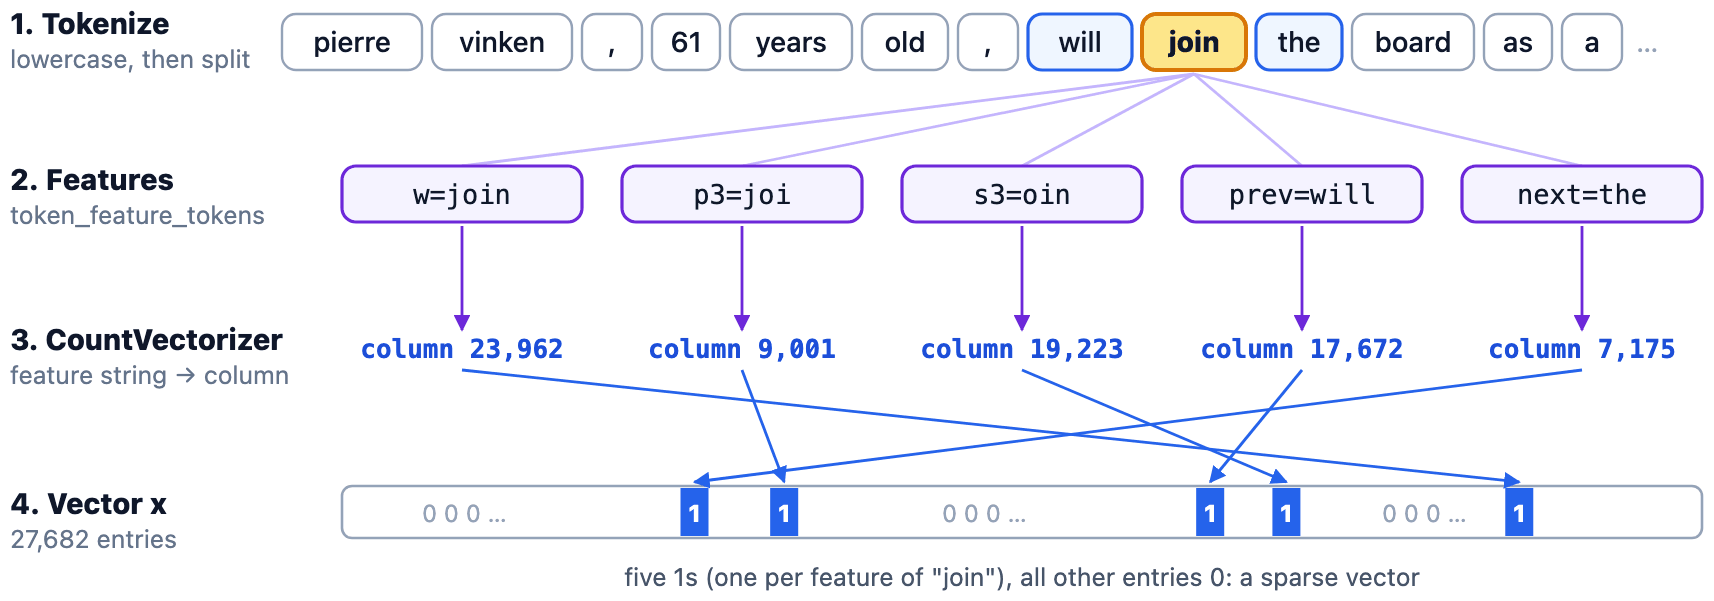

For each token we write a few **feature strings**: the word, its first and last three letters, and its neighbours. `CountVectorizer` (Part 2) gives every feature string seen in training its own column, so a token becomes a vector with a 1 in the columns of its features and 0 everywhere else. The walkthroughs below step through the tokenizer and the feature function.

In [17]:
# @title Walkthrough: simple_ws_punct_tokenize on a short input
trace_call(
    simple_ws_punct_tokenize, "Hi, Byte!",
    title="simple_ws_punct_tokenize('Hi, Byte!'): lowercase, pad punctuation, then split",
    intro="A short input. The text is lowercased first; then punctuation gets a space on each side.",
    notes={
        'characters.extend([" ", character, " "])': "{character!r} is punctuation, so it gets a space on each side.",
        "return": "Joining gives 'hi ,  byte ! ', and split() drops the extra spaces: four lowercase tokens.",
    },
)

In [ ]:
# @title Walkthrough: the features of one token
trace_call(
    token_feature_tokens, ["byte", "ate", "12", "pizza-slices", "."], 3,
    title="token_feature_tokens(tokens, 3): the features of 'pizza-slices'",
    intro="Five lowercase tokens; we ask for the features of position 3. Predict which cues will fire.",
    notes={
        'f"w={word}"': "The word itself, already lowercased by the tokenizer.",
        'f"p3=': "Prefix: the first three letters.",
        'f"s3=': "Suffix: the last three letters ({word[-3:]!r}). Endings such as -ing or -es hint at the tag.",
        'f"prev=': "The previous token, or <BOS> at the start of a sentence.",
        'f"next=': "The next token, or <EOS> at the end of a sentence.",
        "features = [": "Five context features: {features}",
        'features.append("has_hyphen")': "{word!r} contains '-', so the cue has_hyphen is added.",
        "return": "Each string becomes one column of the sparse input vector that the tagger reads in Part 2.",
    },
)

### The model: forward and backward pass

Part 2 trains a small MLP in PyTorch, with the same steps as in PS 01, that maps the features of one token to one of 12 Universal POS tags:

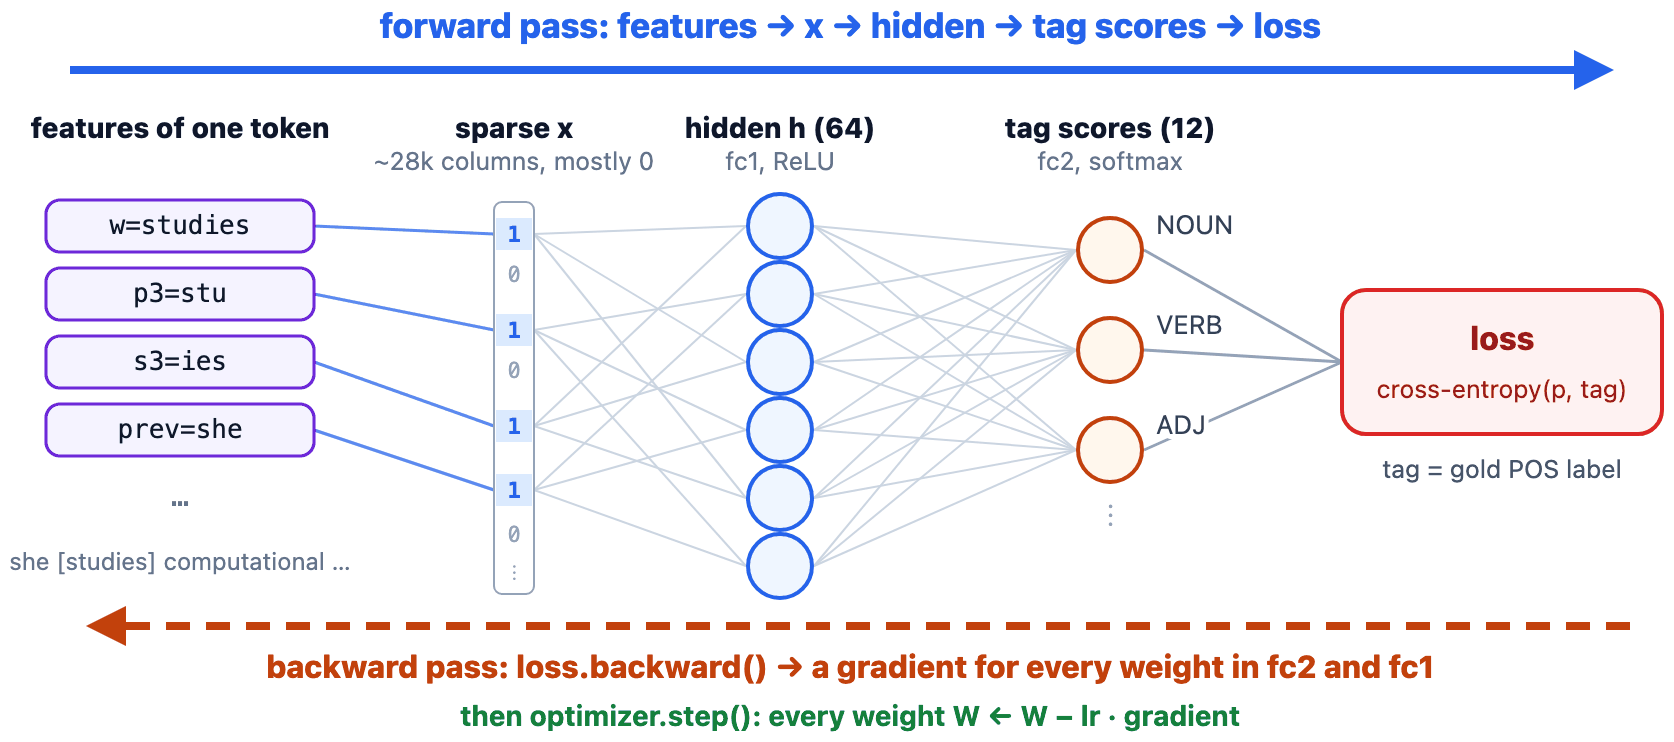

- **Forward pass** (blue): the active columns of `x` feed the 64 hidden units (`fc1`, ReLU), then one score per tag (`fc2`); softmax and cross-entropy compare the scores with the gold tag.
- **Backward pass** (orange): `loss.backward()` gives every weight a gradient, and `optimizer.step()` updates the weights.

After the next cell, an animation tags a whole sentence token by token, and a walkthrough plays both passes for the token *studies* with the trained weights.

In [21]:
# Part 2 — vectorize, train a PyTorch MLP, evaluate, and predict
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.feature_extraction.text import CountVectorizer


def feat_doc_tokenizer(document):
    """Preserve pre-built feature tokens such as w=the and prev=<BOS>."""
    return document.split()


# 1. Vectorize: CountVectorizer gives every feature string seen in training its own column
vectorizer = CountVectorizer(tokenizer=feat_doc_tokenizer, lowercase=False, token_pattern=None)
X_train = vectorizer.fit_transform(X_train_docs)  # sparse matrix: one slot per token, mostly zeros
X_test = vectorizer.transform(X_test_docs)

feature_names = vectorizer.get_feature_names_out()
print(f"Feature vocabulary size: {len(feature_names):,}")
print("Columns of the features of 'join':",
      {feature_names[column]: int(column) for column in X_train[8].nonzero()[1]})

# 2. Labels: one integer ID per Universal POS tag
tag_names = sorted(set(y_train))
tag_to_id = {tag: index for index, tag in enumerate(tag_names)}
y_train_ids = torch.tensor([tag_to_id[tag] for tag in y_train])
y_test_ids = torch.tensor([tag_to_id[tag] for tag in y_test])


def to_tensor(rows):
    """Turn rows of the sparse matrix into a dense float32 tensor, one row per token."""
    return torch.from_numpy(rows.toarray().astype(np.float32))


# 3. Model: the MLP of PS 01, fc1 -> ReLU -> fc2
class SimpleMLP(nn.Module):
    def __init__(self, input_size, hidden_size, num_classes):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        hidden = self.relu(self.fc1(x))
        return self.fc2(hidden)  # raw scores (logits), one per tag


torch.manual_seed(42)
model = SimpleMLP(input_size=X_train.shape[1], hidden_size=64, num_classes=len(tag_names))
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.5)

# 4. Training: the PS 01 step for every mini-batch of 64 tokens, two passes over the data (epochs)
BATCH_SIZE, EPOCHS = 64, 2
generator = torch.Generator().manual_seed(42)
for epoch in range(EPOCHS):
    model.train()
    order = torch.randperm(X_train.shape[0], generator=generator)
    total_loss = 0.0
    for start in range(0, len(order), BATCH_SIZE):
        batch = order[start:start + BATCH_SIZE].numpy()
        optimizer.zero_grad()                         # clear old gradients
        logits = model(to_tensor(X_train[batch]))     # forward pass
        loss = criterion(logits, y_train_ids[batch])  # cross-entropy loss
        loss.backward()                               # gradients for every weight
        optimizer.step()                              # update the weights
        total_loss += loss.item() * len(batch)
    print(f"Epoch {epoch + 1} | mean training loss {total_loss / len(order):.4f}")


# 5. Evaluation: no gradients; the sparse test matrix is converted in chunks
EVAL_CHUNK = 2048

def predict_ids(X):
    model.eval()
    chunks = []
    with torch.no_grad():
        for start in range(0, X.shape[0], EVAL_CHUNK):
            logits = model(to_tensor(X[start:start + EVAL_CHUNK]))
            chunks.append(logits.argmax(dim=1))
    return torch.cat(chunks)


majority_tag = Counter(y_train).most_common(1)[0][0]
baseline_accuracy = float(np.mean([tag == majority_tag for tag in y_test]))
model_accuracy = (predict_ids(X_test) == y_test_ids).float().mean().item()

print("\n=== BASELINE VS. COMPACT MLP ===")
print(f"Majority baseline ({majority_tag}): {baseline_accuracy:.3f}")
print(f"MLP after two epochs:           {model_accuracy:.3f}")
print(f"Absolute improvement:           {model_accuracy - baseline_accuracy:+.3f}")

pos_sentences = [
    "The lazy cat sleeps on the warm pizza box.",
    "She studies computational linguistics at the university.",
    "Running water sounds very peaceful and relaxing.",
    "The pizza will be delivered tomorrow morning.",
]


def pos_tag_baseline(text):
    tokens = simple_ws_punct_tokenize(text)
    return [(token, majority_tag) for token in tokens]


def pos_tag_nn(text):
    tokens = simple_ws_punct_tokenize(text)
    documents = [token_feature_doc(tokens, index) for index in range(len(tokens))]
    tag_ids = predict_ids(vectorizer.transform(documents))
    return [(token, tag_names[tag_id]) for token, tag_id in zip(tokens, tag_ids.tolist())]


print("\n=== BEFORE VS. AFTER ON NEW SENTENCES ===")
for sentence in pos_sentences:
    print(f"\n{sentence}")
    print("  baseline:", pos_tag_baseline(sentence))
    print("  MLP:     ", pos_tag_nn(sentence))

RuntimeError: duplicate registrations for aten.linspace.Tensor_Tensor

In [ ]:
# @title Animation: the trained tagger tags one sentence, token by token
# Uses the model and vectorizer trained in the cell above and the tokenizer and feature function of Part 1.
text = "The pizza will be delivered tomorrow morning."
tokens = simple_ws_punct_tokenize(text)
pos_pipeline_animation(model, vectorizer, tag_names, text, tokens,
                       [token_feature_tokens(tokens, index) for index in range(len(tokens))],
                       title="Animation: from a sentence to POS tags")

In [ ]:
# @title Walkthrough: how the trained tagger handles "studies"
# Uses the model and vectorizer trained above; the last step updates a copy, so the trained model is not changed.
tokens = ["she", "studies", "computational", "linguistics", "at", "the", "university", "."]
tagger_walkthrough(
    model, vectorizer, tokens, 1, token_feature_doc(tokens, 1), gold="VERB", tag_names=tag_names, lr=0.5,
    title="Inside the tagger: 'studies' in 'she studies computational linguistics .'",
)

In [ ]:
# Guided comparison: NLTK, spaCy, and the compact MLP tagger
pos_sentences = [
    "The lazy cat sleeps on the warm pizza box.",
    "She studies computational linguistics at the university.",
    "Running water sounds very peaceful and relaxing.",
    "The pizza will be delivered tomorrow morning.",
]

print("=== POS TAGGING COMPARISON ===")

for index, sentence in enumerate(pos_sentences, start=1):
    nltk_tokens = nltk.word_tokenize(sentence)
    nltk_tags = nltk.pos_tag(nltk_tokens)
    spacy_doc = nlp(sentence)
    spacy_tags = [(token.text, token.pos_, token.tag_) for token in spacy_doc]
    mlp_tags = pos_tag_nn(sentence)

    print(f"\n{index}. {sentence}")
    print("  NLTK (Penn Treebank):", nltk_tags)
    print("  spaCy (coarse, fine):", spacy_tags)
    print("  compact MLP (Universal):", mlp_tags)

print("\nInterpretation notes:")
print("• NLTK and spaCy expose different tag inventories.")
print("• Tokenization differences can prevent position-by-position comparison.")
print("• The compact MLP is a transparent baseline, not a replacement for a trained pipeline.")


=== POS TAGGING COMPARISON ===

1. The lazy cat sleeps on the warm pizza box.
  NLTK (Penn Treebank): [('The', 'DT'), ('lazy', 'JJ'), ('cat', 'NN'), ('sleeps', 'NNS'), ('on', 'IN'), ('the', 'DT'), ('warm', 'JJ'), ('pizza', 'NN'), ('box', 'NN'), ('.', '.')]
  spaCy (coarse, fine): [('The', 'DET', 'DT'), ('lazy', 'ADJ', 'JJ'), ('cat', 'NOUN', 'NN'), ('sleeps', 'VERB', 'VBZ'), ('on', 'ADP', 'IN'), ('the', 'DET', 'DT'), ('warm', 'ADJ', 'JJ'), ('pizza', 'NOUN', 'NN'), ('box', 'PROPN', 'NNP'), ('.', 'PUNCT', '.')]
  compact MLP (Universal): [('the', 'DET'), ('lazy', 'NOUN'), ('cat', 'NOUN'), ('sleeps', 'NOUN'), ('on', 'ADP'), ('the', 'DET'), ('warm', 'NOUN'), ('pizza', 'NOUN'), ('box', 'NOUN'), ('.', '.')]

2. She studies computational linguistics at the university.
  NLTK (Penn Treebank): [('She', 'PRP'), ('studies', 'NNS'), ('computational', 'JJ'), ('linguistics', 'NNS'), ('at', 'IN'), ('the', 'DT'), ('university', 'NN'), ('.', '.')]
  spaCy (coarse, fine): [('She', 'PRON', 'PRP'), ('studi

## Dependency parsing: heads, dependents, and trees

A dependency parse assigns each token:

- a **head** (the token it depends on), and
- a **dependency relation** describing the connection.

For example, in *Students read books*, *read* is the root, *Students* is its nominal subject, and *books* is its object.

**Transition-based parsing.** A transition-based parser builds the tree through actions over a stack and a buffer; Arc-standard parsing uses **SHIFT**, **LEFT-ARC**, and **RIGHT-ARC**.

In the homework, you will implement the checks that decide whether a dependency tree is valid. Here, we first use spaCy's pretrained parser and inspect its output; then we look at these conditions and step through Arc-standard parsing.


In [ ]:
# Guided demonstration: inspect spaCy dependency parses
parsing_examples = [
    "The cat ate the pizza in the kitchen.",
    "I saw the man with the telescope.",
]

def print_dependencies(token, depth):
    """Recursively print a dependency subtree."""
    for child in token.children:
        print("  " * depth + f"├─ {child.dep_}: {child.text}")
        print_dependencies(child, depth + 1)


def analyze_dependencies(sentence):
    """Display token-level dependencies and a readable tree."""
    doc = nlp(sentence)
    print(f"\nSentence: {sentence}")
    print(f"{'Token':<12} {'POS':<8} {'Relation':<12} {'Head':<12} Children")
    print("-" * 74)

    for token in doc:
        children = ", ".join(child.text for child in token.children) or "—"
        print(
            f"{token.text:<12} {token.pos_:<8} {token.dep_:<12} "
            f"{token.head.text:<12} {children}"
        )

    root = next(token for token in doc if token.dep_ == "ROOT")
    print("\nDependency tree:")
    print(f"ROOT: {root.text}")
    print_dependencies(root, 1)


print("=== DEPENDENCY PARSING ===")
for sentence in parsing_examples:
    analyze_dependencies(sentence)

print("\nCommon relations:")
dependency_types = {
    "nsubj": "nominal subject",
    "obj / dobj": "object (label depends on the parser/tag scheme)",
    "amod": "adjectival modifier",
    "prep": "prepositional modifier",
    "det": "determiner",
    "aux": "auxiliary",
    "advmod": "adverbial modifier",
}
for relation, meaning in dependency_types.items():
    print(f"  {relation:<12} → {meaning}")


=== DEPENDENCY PARSING ===

Sentence: The cat ate the pizza in the kitchen.
Token        POS      Relation     Head         Children
--------------------------------------------------------------------------
The          DET      det          cat          —
cat          NOUN     nsubj        ate          The
ate          VERB     ROOT         ate          cat, pizza, in, .
the          DET      det          pizza        —
pizza        NOUN     dobj         ate          the
in           ADP      prep         ate          kitchen
the          DET      det          kitchen      —
kitchen      NOUN     pobj         in           the
.            PUNCT    punct        ate          —

Dependency tree:
ROOT: ate
  ├─ nsubj: cat
    ├─ det: The
  ├─ dobj: pizza
    ├─ det: the
  ├─ prep: in
    ├─ pobj: kitchen
      ├─ det: the
  ├─ punct: .

Sentence: I saw the man with the telescope.
Token        POS      Relation     Head         Children
----------------------------------------------------

In [ ]:
# @title Explorer: click a word (or press Next) to see its head and dependents
parsing_examples = [
    "The cat ate the pizza in the kitchen.",
    "I saw the man with the telescope.",
]
dependency_explorer([nlp(sentence) for sentence in parsing_examples],
                    title="Dependency arcs: heads, relations, and attachment")

### Conditions on dependency graphs

A dependency graph has the words as nodes, plus an artificial **ROOT** (index 0), and an arc `i → j` from each head `i` to its dependent `j`; `i →* j` means a path of one or more arcs. A well-formed dependency tree satisfies four formal conditions:

| Condition | Formal definition | Intuition | How to check it |
|---|---|---|---|
| **Connected** | `i ↔* j` for all nodes, ignoring arc directions | the structure is complete | start at ROOT and walk along arcs in both directions; every word must be reached |
| **Acyclic** | if `i → j`, then not `j →* i` | the structure is hierarchical | follow arcs downward from each word; no word may come back to itself |
| **Single-head** | if `i → j` and `k → j`, then `i = k` | every word has at most one head | count the incoming arcs of each word |
| **Projective** | if `i → j`, then `i →* k` for every `k` between `i` and `j` | no crossing arcs | for each arc, every word between head and dependent must hang below the head |

Adding ROOT and giving every word exactly one head makes connectedness easy to guarantee. Projectivity matters for the parser below: Arc-standard can only build projective trees. The explorer checks the four conditions on a correct tree, on three broken versions of it, and on spaCy's own parse of *The cat ate a pizza yesterday that was cold.*, which is non-projective. In the homework, you implement exactly these four checks.

In [ ]:
# @title Explorer: check the four conditions on five small dependency graphs
words = ["ROOT", "The", "cat", "ate", "the", "pizza", "."]
tree = [(2, 1, "det"), (3, 2, "nsubj"), (0, 3, "root"), (5, 4, "det"), (3, 5, "dobj"), (3, 6, "punct")]  # (head, dependent, relation)

no_head = [arc for arc in tree if arc != (3, 6, "punct")]                    # "." loses its head
cycle = [arc for arc in tree if arc[1] not in (5, 6)] + [(5, 6, "?"), (6, 5, "?")]  # pizza and "." head each other
two_heads = tree + [(6, 5, "?")]                                             # pizza gets a second head

late_words = ["ROOT", "The", "cat", "ate", "a", "pizza", "yesterday", "that", "was", "cold", "."]
late_tree = [(2, 1, "det"), (3, 2, "nsubj"), (0, 3, "root"), (5, 4, "det"), (3, 5, "dobj"),
             (3, 6, "npadvmod"), (8, 7, "nsubj"), (5, 8, "relcl"), (8, 9, "acomp"), (3, 10, "punct")]

dependency_conditions_explorer([
    ("A well-formed tree", words, tree),
    ("A word without a head", words, no_head),
    ("A cycle", words, cycle),
    ("Two heads", words, two_heads),
    ("Crossing arcs", late_words, late_tree,
     "spaCy's en_core_web_sm returns this parse: 'that was cold' describes the pizza, but 'yesterday' sits in between."),
])

### Arc-standard transition-based parsing

A transition-based parser reads the sentence once from left to right and builds the tree with a few simple actions. A **configuration** is a triple (STACK, BUFFER, ARCS):

- start: STACK = [ROOT], BUFFER = all words in order, ARCS empty;
- stop: the BUFFER is empty and only ROOT is left on the STACK.

With `s1` the top of the stack and `s2` the item below it:

| Action | Allowed when | Effect |
|---|---|---|
| **SHIFT** | the buffer is not empty | move the first buffer word onto the stack |
| **LEFT-ARC** | `s2` exists and is not ROOT | add `s1 → s2` and remove `s2` |
| **RIGHT-ARC** | `s2` exists | add `s2 → s1` and remove `s1` |

**Choosing the action.** A trained parser predicts the next action with a classifier. To see the mechanics, we use a **static oracle** instead, which reads the correct (gold) tree:

1. LEFT-ARC if the gold head of `s2` is `s1` and `s2` already has all its dependents;
2. otherwise RIGHT-ARC if the gold head of `s1` is `s2` and `s1` already has all its dependents;
3. otherwise SHIFT.

A word may leave the stack only after all its own dependents are attached, because no arc can reach it afterwards. Every word is shifted once and removed once, so a sentence with *n* words needs exactly 2*n* transitions. The same rule explains why crossing (non-projective) arcs cannot be built.

The next cell implements this loop in a few lines. The animation after it shows the words moving from the buffer to the stack and into the tree, and the walkthrough lets you check every decision, including a sentence on which the parser gets stuck.

In [ ]:
# Guided demonstration: Arc-standard parsing with a static oracle
def arc_standard_parse(words, gold_heads):
    """Rebuild the gold tree with SHIFT, LEFT-ARC, and RIGHT-ARC, printing every transition."""
    stack, buffer, heads = [0], list(range(1, len(words))), {}  # heads: dependent -> head

    def has_all_dependents(node):
        return all(dependent in heads for dependent, head in enumerate(gold_heads) if head == node)

    while buffer or len(stack) > 1:
        s1 = stack[-1]
        s2 = stack[-2] if len(stack) > 1 else None
        if s2 not in (None, 0) and gold_heads[s2] == s1 and has_all_dependents(s2):
            action = "LEFT-ARC"                 # add s1 -> s2, then remove s2
            heads[s2] = s1
            del stack[-2]
        elif s2 is not None and gold_heads[s1] == s2 and has_all_dependents(s1):
            action = "RIGHT-ARC"                # add s2 -> s1, then remove s1
            heads[s1] = s2
            stack.pop()
        elif buffer:
            action = "SHIFT"                    # move the next word onto the stack
            stack.append(buffer.pop(0))
        else:
            raise ValueError("no legal action: the gold tree is not projective")
        print(f"{action:<10} stack={[words[i] for i in stack]}  buffer={[words[i] for i in buffer]}")
    return [-1] + [heads[index] for index in range(1, len(words))]


words = ["ROOT", "The", "cat", "ate", "the", "pizza", "."]
gold_heads = [-1, 2, 3, 0, 5, 3, 3]  # gold_heads[i] = index of the head of word i; "ate" hangs below ROOT
predicted_heads = arc_standard_parse(words, gold_heads)
print("\nRebuilt heads:", predicted_heads)
print("Same as the gold tree:", predicted_heads == gold_heads)

SHIFT      stack=['ROOT', 'The']  buffer=['cat', 'ate', 'the', 'pizza', '.']
SHIFT      stack=['ROOT', 'The', 'cat']  buffer=['ate', 'the', 'pizza', '.']
LEFT-ARC   stack=['ROOT', 'cat']  buffer=['ate', 'the', 'pizza', '.']
SHIFT      stack=['ROOT', 'cat', 'ate']  buffer=['the', 'pizza', '.']
LEFT-ARC   stack=['ROOT', 'ate']  buffer=['the', 'pizza', '.']
SHIFT      stack=['ROOT', 'ate', 'the']  buffer=['pizza', '.']
SHIFT      stack=['ROOT', 'ate', 'the', 'pizza']  buffer=['.']
LEFT-ARC   stack=['ROOT', 'ate', 'pizza']  buffer=['.']
RIGHT-ARC  stack=['ROOT', 'ate']  buffer=['.']
SHIFT      stack=['ROOT', 'ate', '.']  buffer=[]
RIGHT-ARC  stack=['ROOT', 'ate']  buffer=[]
RIGHT-ARC  stack=['ROOT']  buffer=[]

Rebuilt heads: [-1, 2, 3, 0, 5, 3, 3]
Same as the gold tree: True


In [ ]:
# @title Animation: Arc-standard builds the tree, transition by transition
arc_standard_animation(
    [nlp("The cat ate the pizza."), nlp("Book me the morning flight."), nlp("The cat ate a pizza yesterday that was cold.")],
    title="Animation: Arc-standard builds the tree",
)

In [ ]:
# @title Walkthrough: Arc-standard parsing, one transition at a time
arc_standard_walkthrough(
    [nlp("The cat ate the pizza."), nlp("Book me the morning flight."), nlp("The cat ate a pizza yesterday that was cold.")],
    title="Arc-standard parsing with a static oracle",
)

## 3. Semantics and Lexical Ambiguity

**Semantics** concerns the meanings of words, phrases, and sentences.

- **Lexical semantics:** meanings of words and relations among them.
- **Lexical ambiguity:** one word form can evoke multiple senses, as with *bank*.
- **Synset:** List of all **synsets** for a word (e.g., *car*, *happy*): name, POS, definition, examples.
- **Semantic relations:** links such as synonymy, antonymy, hypernymy, and hyponymy.

Two common sources of ambiguity are:

1. **Polysemy:** related senses, such as *paper* as material or an academic article.
2. **Homonymy:** historically or conceptually unrelated senses, such as *bark* of a dog and *bark* of a tree.

A tokenizer or POS tagger alone does not select the intended sense; the surrounding context must contribute evidence.


In [ ]:
# Exploring lexical ambiguity and semantic analysis

print("=== LEXICAL AMBIGUITY EXPLORATION ===")
print()

# Examples of ambiguous words with different meanings
ambiguous_words = {
    "bank": [
        "The bank approved my loan application.",  # Financial institution
        "We sat by the river bank watching the sunset."  # River side
    ],
    "bark": [
        "The dog's bark woke up the neighbors.",  # Dog sound
        "The bark of the old oak tree was rough."  # Tree covering
    ],
    "tear": [
        "A tear rolled down her cheek.",  # Drop from eye
        "Be careful not to tear the paper."  # Damage
    ]
}

print("ANALYZING LEXICAL AMBIGUITY:")
print()

# Demonstrate lemmatization in semantic context
for word, sentences in ambiguous_words.items():
    print(f"Word: '{word}' - Multiple meanings:")

    for i, sentence in enumerate(sentences, 1):
        print(f"  {i}. {sentence}")

        # Analyze with spaCy
        doc = nlp(sentence)
        for token in doc:
            if token.text == word:
                print(f"     → Lemma: '{token.lemma_}', POS: {token.pos_}")
                break
    print()


print()
print("Key observations:")
print("• Context affects how models interpret word meaning")
print("• Semantic analysis benefits from accurate tagging")


=== LEXICAL AMBIGUITY EXPLORATION ===

ANALYZING LEXICAL AMBIGUITY:

Word: 'bank' - Multiple meanings:
  1. The bank approved my loan application.
     → Lemma: 'bank', POS: NOUN
  2. We sat by the river bank watching the sunset.
     → Lemma: 'bank', POS: NOUN

Word: 'bark' - Multiple meanings:
  1. The dog's bark woke up the neighbors.
     → Lemma: 'bark', POS: NOUN
  2. The bark of the old oak tree was rough.
     → Lemma: 'bark', POS: NOUN

Word: 'tear' - Multiple meanings:
  1. A tear rolled down her cheek.
     → Lemma: 'tear', POS: NOUN
  2. Be careful not to tear the paper.
     → Lemma: 'tear', POS: VERB


Key observations:
• Context affects how models interpret word meaning
• Semantic analysis benefits from accurate tagging


## WordNet: synsets and semantic relations

WordNet is a curated **lexical database of English**. It groups lemmas into **synsets**, each representing one sense and providing:

- a part of speech;
- a short definition (gloss);
- optional usage examples;
- semantic relations to other synsets.

`car.n.01` means the first noun sense of *car*.

- A **hypernym** is more general: a car **is a** vehicle.
- A **hyponym** is more specific: a sedan **is a** car.

These links form a taxonomy. **Path similarity** compares two selected synsets by their distance in that taxonomy: a shorter path produces a higher score.

The next cell lists the senses of *car* and *happy* and the relations of their first sense. The cell after it compares *dog*, *cat*, and *car* with path similarity, and the explorer after that counts the edges of each path step by step.


In [ ]:
# Introduction to WordNet - A lexical database

from nltk.corpus import wordnet as wn

print("=== WORDNET EXPLORATION ===")
print()

# Explore a word in WordNet
def explore_word_semantics(word):
    """Explore semantic properties of a word using WordNet."""
    print(f"Exploring '{word}' in WordNet:")
    print("-" * 40)

    # Get all synsets (word senses) for the word
    synsets = wn.synsets(word)

    if not synsets:
        print(f"No synsets found for '{word}'")
        return

    print(f"Found {len(synsets)} synsets (word senses):")
    print()

    for i, synset in enumerate(synsets, 1):
        print(f"Sense {i}: {synset.name()}")
        print(f"  POS: {synset.pos()}")
        print(f"  Definition: {synset.definition()}")

        # Show examples if available
        if synset.examples():
            print(f"  Examples: {'; '.join(synset.examples())}")

        print()

    return synsets

# Explore semantic relationships
def show_semantic_relations(word, synset_index=0):
    """Show semantic relationships for a specific synset."""
    synsets = wn.synsets(word)
    if not synsets or synset_index >= len(synsets):
        print(f"Cannot find synset {synset_index} for '{word}'")
        return

    synset = synsets[synset_index]
    print(f"Semantic relationships for '{synset.name()}':")
    print("-" * 50)

    # Hypernyms (more general concepts)
    hypernyms = synset.hypernyms()
    if hypernyms:
        print(f"Hypernyms (more general): {[h.name() for h in hypernyms]}")

    # Hyponyms (more specific concepts)
    hyponyms = synset.hyponyms()
    if hyponyms:
        print(f"Hyponyms (more specific): {[h.name() for h in hyponyms]}")

    print()

# Demonstrate with example words
example_words = ["car", "happy"]

for word in example_words:
    synsets = explore_word_semantics(word)
    if synsets:
        show_semantic_relations(word, 0)  # Show relationships for first sense
    print("=" * 60)
    print()

=== WORDNET EXPLORATION ===

Exploring 'car' in WordNet:
----------------------------------------
Found 5 synsets (word senses):

Sense 1: car.n.01
  POS: n
  Definition: a motor vehicle with four wheels; usually propelled by an internal combustion engine
  Examples: he needs a car to get to work

Sense 2: car.n.02
  POS: n
  Definition: a wheeled vehicle adapted to the rails of railroad
  Examples: three cars had jumped the rails

Sense 3: car.n.03
  POS: n
  Definition: the compartment that is suspended from an airship and that carries personnel and the cargo and the power plant

Sense 4: car.n.04
  POS: n
  Definition: where passengers ride up and down
  Examples: the car was on the top floor

Sense 5: cable_car.n.01
  POS: n
  Definition: a conveyance for passengers or freight on a cable railway
  Examples: they took a cable car to the top of the mountain

Semantic relationships for 'car.n.01':
--------------------------------------------------
Hypernyms (more general): ['motor_veh

In [ ]:
# Semantic similarity between selected senses
from nltk.corpus import wordnet as wn

print("SEMANTIC SIMILARITY:")
print("WordNet can compute semantic similarity between concepts.")
print()

# Get synsets for comparison
dog = wn.synset('dog.n.01')  # First noun sense of 'dog'
cat = wn.synset('cat.n.01')  # First noun sense of 'cat'
car = wn.synset('car.n.01')  # First noun sense of 'car'

# Calculate similarities
dog_cat_sim = dog.path_similarity(cat)
dog_car_sim = dog.path_similarity(car)
cat_car_sim = cat.path_similarity(car)

print(f"Similarity between dog and cat: {dog_cat_sim:.3f}")
print(f"Similarity between dog and car: {dog_car_sim:.3f}")
print(f"Similarity between cat and car: {cat_car_sim:.3f}")

print()
print("WordNet applications:")
print("• Word sense disambiguation")
print("• Semantic similarity computation")
print("• Information retrieval and search")
print("• Machine translation and generation")
print("• Knowledge graph construction")

SEMANTIC SIMILARITY:
WordNet can compute semantic similarity between concepts.

Similarity between dog and cat: 0.200
Similarity between dog and car: 0.077
Similarity between cat and car: 0.056

WordNet applications:
• Word sense disambiguation
• Semantic similarity computation
• Information retrieval and search
• Machine translation and generation
• Knowledge graph construction


In [ ]:
# @title Explorer: how path_similarity counts the edges between two senses
from nltk.corpus import wordnet as wn

dog = wn.synset("dog.n.01")
cat = wn.synset("cat.n.01")
car = wn.synset("car.n.01")
wordnet_path_explorer([(dog, cat), (dog, car), (cat, car)])

## Word Sense Disambiguation: selecting a sense in context

A word can have multiple senses. **Word Sense Disambiguation (WSD)** chooses the sense that best fits a sentence or document.

### Lesk's algorithm

**Idea (Lesk, 1986):** sense $s_i$ of an ambiguous word $w$ is likely the intended one if many words of its dictionary definition also occur in the context of $w$. Both variants below remove stopwords, normalize the words (lowercase, base form), and compare two bags of words:

- $D_i$ = the words of the **definition** of sense $s_i$;
- $B$ = the evidence from the context of $w$;
- choose the sense that maximizes $\operatorname{overlap}(D_i, B)$; if several senses score the same, take the earliest one in WordNet's order (usually the most frequent sense).

| | **Simplified Lesk** | **Original Lesk** |
|---|---|---|
| $B$ | the **context words themselves** | the words of the **definitions of all senses of all context words** |
| compares | a definition with the sentence | a definition with other definitions |

**Toy example**

> We sat by the **bank** watching the boats on the **river**.

- Context words: `sit`, `watch`, `boat`, `river`.
- The river-bank definition, *sloping land (especially the slope beside a body of water)*, contains none of them: Simplified Lesk scores every sense 0 and falls back to the first sense.
- Original Lesk looks up the definitions of *river* (*a large natural stream of water*) and *boat* (*a small vessel for travel on water*). They contain *water*, which also occurs in the river-bank definition, so the river bank wins with real evidence.

The explorer below runs both variants on three sentences and counts the shared words; switch between them with the two buttons.

**In the homework**, you implement the **original Lesk algorithm** and compare it with Simplified Lesk on SemCor, a corpus whose nouns were annotated by hand with WordNet senses. There, the context is a window of three content words on each side of $w$, and the overlap is scored with the **cosine similarity** of the two count vectors instead of a simple count of shared words.

**Limitations of word overlap:** glosses are short, preprocessing choices affect the overlap.

In [ ]:
# @title Explorer: Simplified Lesk vs. original Lesk on three "bank" sentences
lesk_explorer(
    [
        "We sat by the bank watching the boats on the river.",
        "The cat napped on the bank next to the water.",
        "Byte deposited the pizza money at the bank.",
    ],
    target="bank",
    title='Simplified Lesk vs. original Lesk: which sense of "bank"?',
)

---

## Task 2.1: Extract syntax and interpret ambiguity

**Goal:** use spaCy's POS tags and dependency parse to find the structure that the parser chose for each ambiguous sentence.

Fill in the three `___` placeholders in the loop over the tokens of `doc`:

1. `analysis["tokens"]`: the token's text;
2. `analysis["pos_tags"]`: the tuple `(text, POS)`, from the coarse Universal tag `pos_`;
3. `analysis["dependencies"]`: the tuple `(text, relation, head text)`, from `dep_` and the token's `head`.

The subjects, objects, and root are collected for you.

**Expected checks:** every sentence has one token, one POS tuple, and one dependency tuple per word, and a root; the head of `with` in *I saw the man with the telescope.* is `man`.

In [ ]:
# Task 2.1: Complete the syntactic analysis function
def analyze_sentence_syntax(sentence):
    """Return token, POS, dependency, and key-role information."""
    doc = nlp(sentence)

    analysis = {
        "sentence": sentence,
        "tokens": [],
        "pos_tags": [],
        "dependencies": [],
        "subjects": [],
        "objects": [],
        "root_verb": None,
    }

    for token in doc:
        analysis["tokens"].append(___)
        analysis["pos_tags"].append(___)
        analysis["dependencies"].append(___)

        if token.dep_ in {"nsubj", "nsubjpass"}:
            analysis["subjects"].append(token.text)
        elif token.dep_ in {"obj", "dobj"}:
            analysis["objects"].append(token.text)
        elif token.dep_ == "ROOT":
            analysis["root_verb"] = token.text

    return analysis


def display_syntactic_analysis(analysis):
    """Display a compact analysis table."""
    print(f"Sentence: {analysis['sentence']}")
    print(f"{'Token':<14} {'POS':<10} {'Relation':<12} Head")
    print("-" * 52)

    for pos_info, dependency_info in zip(
        analysis["pos_tags"], analysis["dependencies"]
    ):
        token, pos = pos_info
        _, relation, head = dependency_info
        print(f"{token:<14} {pos:<10} {relation:<12} {head}")

    print(
        f"  root={analysis['root_verb']!r}; "
        f"subjects={analysis['subjects']}; objects={analysis['objects']}"
    )


ambiguous_sentences = [
    "I saw the man with the telescope.",
    "Flying planes can be dangerous.",
    "The shooting of the hunters was terrible.",
]

syntax_analyses = []
print("=== TASK 2.1: SYNTACTIC AMBIGUITY ===")
for index, sentence in enumerate(ambiguous_sentences, start=1):
    analysis = analyze_sentence_syntax(sentence)
    syntax_analyses.append(analysis)
    print(f"\nExample {index}")
    display_syntactic_analysis(analysis)

for analysis in syntax_analyses:
    assert analysis["tokens"] == [token.text for token in nlp(analysis["sentence"])]
    assert len(analysis["tokens"]) == len(analysis["pos_tags"])
    assert len(analysis["tokens"]) == len(analysis["dependencies"])
    assert analysis["root_verb"] is not None
assert ("with", "prep", "man") in syntax_analyses[0]["dependencies"]
print("\nCheck passed: every token has POS and dependency information, and each sentence has a root.")

---

## Task 2.2: Explore WordNet relations and definitions

**Goal:** complete a WordNet analysis that lists every sense of a word with its direct relations, and a reverse lookup that finds senses by a word in their definition.

The senses and their names, POS, definitions, and examples are provided. Fill in the `___` placeholders:

1. `"hypernyms"` and `"hyponyms"`: the **names** of the synsets returned by `synset.hypernyms()` and `synset.hyponyms()`;
2. in `find_word_by_definition`: loop over `wn.all_synsets()`, lowercase each definition, keep it if it contains `target`, and append the pair `(synset name, definition)`.

**Expected checks:** the first sense of *success* has the hypernym `happening.n.01` and some hyponyms, the first sense of *intelligence* has the hypernym `ability.n.02`, and the reverse lookup returns at most 5 definitions that contain "successful".

In [ ]:
# Task 2.2: Complete the WordNet analysis
from nltk.corpus import wordnet as wn

def comprehensive_word_analysis(word):
    """Return and display WordNet senses and direct taxonomic relations."""
    analysis = {"word": word, "synsets": [], "all_definitions": []}

    synsets = wn.synsets(word)
    if not synsets:
        analysis["error"] = f"No synsets found for {word!r}"
        return analysis

    print(f"=== WORDNET ANALYSIS: {word!r} ===")
    for index, synset in enumerate(synsets, start=1):
        synset_info = {
            "name": synset.name(),
            "pos": synset.pos(),
            "definition": synset.definition(),
            "examples": synset.examples(),
            "hypernyms": ___,
            "hyponyms": ___,
        }

        analysis["synsets"].append(synset_info)
        analysis["all_definitions"].append(synset_info["definition"])

        print(f"\n{index}. {synset_info['name']} ({synset_info['pos']})")
        print(f"   definition: {synset_info['definition']}")
        if synset_info["examples"]:
            print(f"   examples: {'; '.join(synset_info['examples'])}")
        if synset_info["hypernyms"]:
            print(f"   hypernyms: {', '.join(synset_info['hypernyms'])}")
        if synset_info["hyponyms"]:
            print(f"   hyponyms: {', '.join(synset_info['hyponyms'])}")

    return analysis


def find_word_by_definition(target_definition, limit=5):
    """Return the first WordNet definitions containing the target text."""
    matches = []
    target = target_definition.lower()

    for synset in ___:
        definition = ___
        if ___:
            matches.append(___)
        if len(matches) >= limit:
            break

    print(f"\n=== DEFINITIONS CONTAINING {target_definition!r} ===")
    for synset_name, definition in matches:
        print(f"  {synset_name}: {definition}")
    return matches


target_words = ["success", "intelligence"]
word_analyses = {}
for word in target_words:
    word_analyses[word] = comprehensive_word_analysis(word)
    print()

reverse_matches = find_word_by_definition("successful")

assert word_analyses["success"]["synsets"][0]["hypernyms"] == ["happening.n.01"]
assert word_analyses["success"]["synsets"][0]["hyponyms"], "the first sense of 'success' has hyponyms"
assert word_analyses["intelligence"]["synsets"][0]["hypernyms"] == ["ability.n.02"]
assert 0 < len(reverse_matches) <= 5
assert all("successful" in definition for _, definition in reverse_matches)
print("\nCheck passed: relations and reverse lookup have the expected values.")

---

## Summary

In this session, you followed a complete **explain → demonstrate → implement → inspect** cycle across four layers of computational linguistics.

**Morphology and tokenization**

- Distinguished inflection, derivation, stemming, and lemmatization.
- Observed that lemmatization is POS-sensitive.
- Compared space splitting, regex rules, NLTK, and spaCy on challenging text.

**Syntax**

- Traced token features through a compact neural POS tagger trained in PyTorch.
- Compared tag inventories and predictions across systems.
- Used dependency heads to diagnose attachment choices without assuming that syntax resolves every semantic ambiguity.
- Checked the four conditions on dependency trees and followed Arc-standard parsing transition by transition.

**Lexical semantics**

- Explored polysemy, homonymy, synsets, hypernyms, and hyponyms.
- Compared selected WordNet senses with path similarity.
- Compared Simplified and original Lesk, which use the context words or their definitions as evidence.

You are now prepared to implement the related algorithms more independently in the homework.
